In [131]:
# Cell 1: Import Required Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 100

print("All libraries imported successfully!")
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)

All libraries imported successfully!
Pandas Version: 3.1.1
NumPy Version: 2.4.6


In [132]:
# Cell 2: Project Configuration

PROJECT_NAME = "Smart Energy Consumption Forecasting"

DATA_PATH = "../dataset/household_power_consumption.txt"

OUTPUT_PATH = "../visualizations"

os.makedirs(OUTPUT_PATH, exist_ok=True)

print("Project:", PROJECT_NAME)
print("Dataset Path:", DATA_PATH)
print("Output Folder:", OUTPUT_PATH)

Project: Smart Energy Consumption Forecasting
Dataset Path: ../dataset/household_power_consumption.txt
Output Folder: ../visualizations


In [133]:
# Cell 3: Load Electricity Consumption Dataset

df = pd.read_csv(
    DATA_PATH,
    sep=";",
    decimal=",",
    na_values=["?"],
    low_memory=False,
    encoding="latin1"
)

print("Dataset Loaded Successfully!")
print("Total Records:", len(df))
print("Total Columns:", len(df.columns))

Dataset Loaded Successfully!
Total Records: 2075259
Total Columns: 9


In [134]:
# Cell 4: First Five Records

display(df.head())

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.000
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.000
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.000
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.000
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.000


In [135]:
# Cell 5: Last Five Records

display(df.tail())

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
2075254,26/11/2010,20:58:00,0.946,0.000,240.430,4.000,0.000,0.000,0.000
2075255,26/11/2010,20:59:00,0.944,0.000,240.000,4.000,0.000,0.000,0.000
2075256,26/11/2010,21:00:00,0.938,0.000,239.820,3.800,0.000,0.000,0.000
2075257,26/11/2010,21:01:00,0.934,0.000,239.700,3.800,0.000,0.000,0.000
2075258,26/11/2010,21:02:00,0.932,0.000,239.550,3.800,0.000,0.000,0.000


In [136]:
# Cell 6: Dataset Information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype
---  ------                 -----
 0   Date                   str  
 1   Time                   str  
 2   Global_active_power    str  
 3   Global_reactive_power  str  
 4   Voltage                str  
 5   Global_intensity       str  
 6   Sub_metering_1         str  
 7   Sub_metering_2         str  
 8   Sub_metering_3         str  
dtypes: str(9)
memory usage: 251.1 MB


In [137]:
# Cell 7: Feature Description

feature_description = {
    "Date": "Date of electricity measurement",
    "Time": "Time of electricity measurement",
    "Global_active_power": "Global active power (kW)",
    "Global_reactive_power": "Global reactive power (kW)",
    "Voltage": "Average voltage (V)",
    "Global_intensity": "Average current intensity (A)",
    "Sub_metering_1": "Kitchen electricity consumption (Wh)",
    "Sub_metering_2": "Laundry electricity consumption (Wh)",
    "Sub_metering_3": "Water heater and AC electricity consumption (Wh)"
}

feature_table = pd.DataFrame(
    list(feature_description.items()),
    columns=["Feature", "Description"]
)

display(feature_table)

,Feature,Description
0,Date,Date of electricity measurement
1,Time,Time of electricity measurement
2,Global_active_power,Global active power (kW)
3,Global_reactive_power,Global reactive power (kW)
4,Voltage,Average voltage (V)
5,Global_intensity,Average current intensity (A)
6,Sub_metering_1,Kitchen electricity consumption (Wh)
7,Sub_metering_2,Laundry electricity consumption (Wh)
8,Sub_metering_3,Water heater and AC electricity consumption (Wh)


In [138]:
# Cell 8: Number of Records and Columns

rows, columns = df.shape

print("Total Records:", rows)
print("Total Columns:", columns)
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
for column in df.columns:
    print("-", column)

Total Records: 2075259
Total Columns: 9
Dataset Shape: (2075259, 9)

Column Names:
- Date
- Time
- Global_active_power
- Global_reactive_power
- Voltage
- Global_intensity
- Sub_metering_1
- Sub_metering_2
- Sub_metering_3


In [139]:
# Cell 9: Missing Value Analysis

missing_table = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage (%)": (
        df.isnull().sum() / len(df) * 100
    )
})

missing_table = missing_table.sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_table)

print("Total Missing Values:", df.isnull().sum().sum())

,Missing Values,Missing Percentage (%)
Global_active_power,25979,1.251844
Sub_metering_2,25979,1.251844
Global_reactive_power,25979,1.251844
Voltage,25979,1.251844
Global_intensity,25979,1.251844
Sub_metering_3,25979,1.251844
Sub_metering_1,25979,1.251844
Date,0,0.000000
Time,0,0.000000


Total Missing Values: 181853


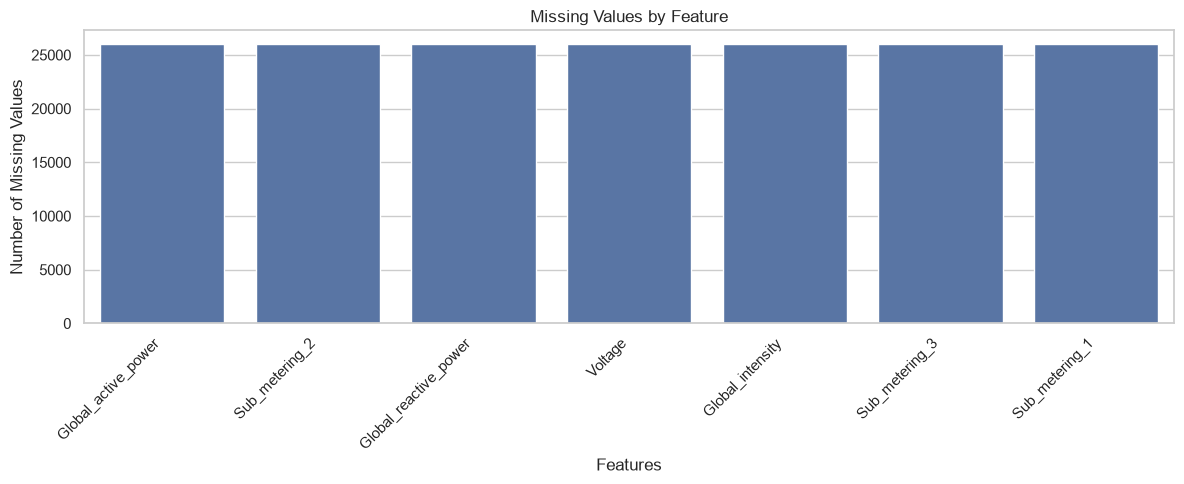

In [140]:
# Cell 10: Missing Values Visualization

missing_plot = missing_table[
    missing_table["Missing Values"] > 0
]

plt.figure(figsize=(12, 5))

if not missing_plot.empty:
    sns.barplot(
        x=missing_plot.index,
        y=missing_plot["Missing Values"]
    )
    plt.xticks(rotation=45, ha="right")
else:
    plt.text(
        0.5, 0.5,
        "No missing values found",
        ha="center",
        va="center"
    )

plt.title("Missing Values by Feature")
plt.xlabel("Features")
plt.ylabel("Number of Missing Values")

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_PATH, "missing_values.png"),
    bbox_inches="tight"
)
plt.show()

In [141]:
# Cell 11: Duplicate Record Analysis

duplicate_count = df.duplicated().sum()

duplicate_percentage = (
    duplicate_count / len(df) * 100
)

print("Total Duplicate Records:", duplicate_count)
print("Duplicate Percentage:", round(duplicate_percentage, 4), "%")

if duplicate_count > 0:
    print("\nSample Duplicate Records:")
    display(df[df.duplicated()].head())
else:
    print("\nNo duplicate records found.")

Total Duplicate Records: 0
Duplicate Percentage: 0.0 %

No duplicate records found.


In [142]:
# Cell 12: Datetime Conversion

df["DateTime"] = pd.to_datetime(
    df["Date"].astype(str) + " " + df["Time"].astype(str),
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

print("Datetime Conversion Completed!")

display(
    df[["Date", "Time", "DateTime"]].head()
)

Datetime Conversion Completed!


,Date,Time,DateTime
0,16/12/2006,17:24:00,2006-12-16 17:24:00
1,16/12/2006,17:25:00,2006-12-16 17:25:00
2,16/12/2006,17:26:00,2006-12-16 17:26:00
3,16/12/2006,17:27:00,2006-12-16 17:27:00
4,16/12/2006,17:28:00,2006-12-16 17:28:00


In [143]:
# Cell 13: Date and Time Range Analysis

start_date = df["DateTime"].min()
end_date = df["DateTime"].max()

print("Starting Date:", start_date)
print("Ending Date:", end_date)

print(
    "Valid Datetime Records:",
    df["DateTime"].notna().sum()
)

print(
    "Invalid Datetime Records:",
    df["DateTime"].isna().sum()
)

print("Total Duration:", end_date - start_date)

Starting Date: 2006-12-16 17:24:00
Ending Date: 2010-11-26 21:02:00
Valid Datetime Records: 2075259
Invalid Datetime Records: 0
Total Duration: 1441 days 03:38:00


In [144]:
# Cell 14: Numerical Data Conversion

measurement_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for column in measurement_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

print("Numerical Conversion Completed!")

display(df[measurement_columns].dtypes)

Numerical Conversion Completed!


Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object

In [145]:
# Cell 15: Consumption Statistics

target = "Global_active_power"

consumption_stats = df[target].describe()

display(consumption_stats)

print("Average Consumption:", df[target].mean(), "kW")
print("Maximum Consumption:", df[target].max(), "kW")
print("Minimum Consumption:", df[target].min(), "kW")
print("Median Consumption:", df[target].median(), "kW")
print("Standard Deviation:", df[target].std(), "kW")

count    2.049280e+06
mean     1.091615e+00
std      1.057294e+00
min      7.600000e-02
25%      3.080000e-01
50%      6.020000e-01
75%      1.528000e+00
max      1.112200e+01
Name: Global_active_power, dtype: float64

Average Consumption: 1.0916150365006245 kW
Maximum Consumption: 11.122 kW
Minimum Consumption: 0.076 kW
Median Consumption: 0.602 kW
Standard Deviation: 1.0572941610939828 kW


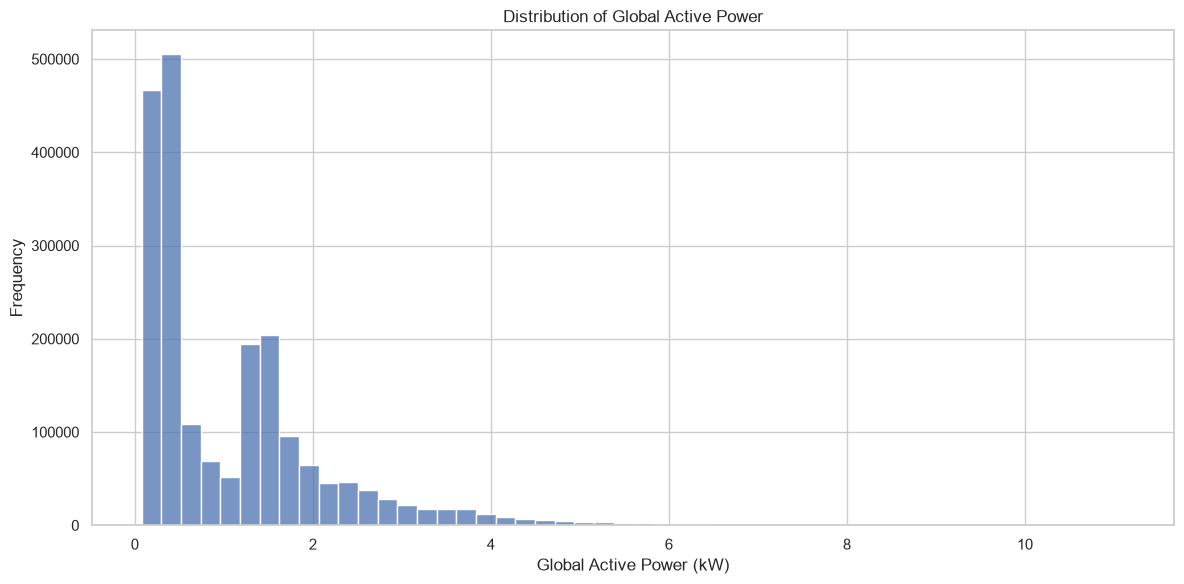

In [146]:
# Cell 16: Consumption Distribution

consumption_data = df[target].dropna()

plt.figure(figsize=(12, 6))

sns.histplot(
    consumption_data,
    bins=50,
    kde=False
)

plt.title("Distribution of Global Active Power")
plt.xlabel("Global Active Power (kW)")
plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_PATH, "consumption_distribution.png"),
    bbox_inches="tight"
)

plt.show()

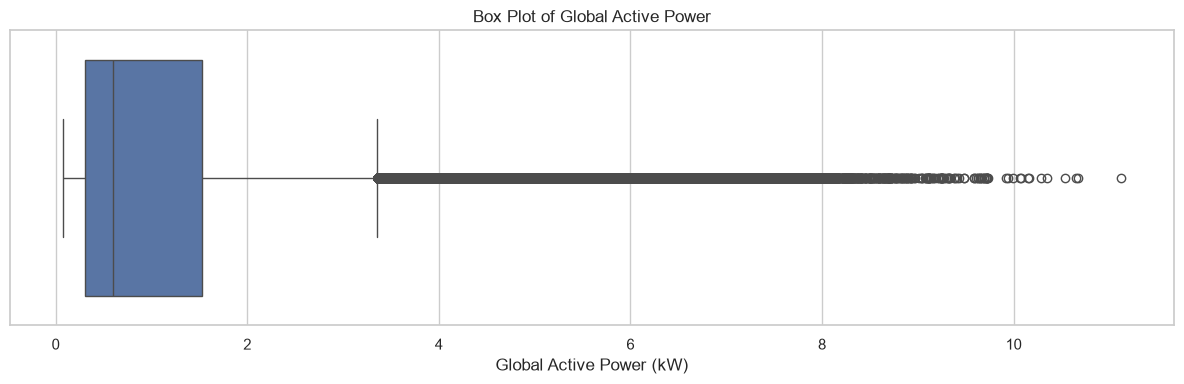

In [147]:
# Cell 17: Consumption Box Plot

plt.figure(figsize=(12, 4))

sns.boxplot(
    x=consumption_data
)

plt.title("Box Plot of Global Active Power")
plt.xlabel("Global Active Power (kW)")

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_PATH, "consumption_boxplot.png"),
    bbox_inches="tight"
)

plt.show()

In [148]:
# Cell 18: Numerical and Categorical Feature Identification

numerical_features = df.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

datetime_features = df.select_dtypes(
    include=["datetime"]
).columns.tolist()

print("NUMERICAL FEATURES:")
for feature in numerical_features:
    print("-", feature)

print("\nCATEGORICAL / TEXT FEATURES:")
for feature in categorical_features:
    print("-", feature)

print("\nDATETIME FEATURES:")
for feature in datetime_features:
    print("-", feature)

NUMERICAL FEATURES:
- Global_active_power
- Global_reactive_power
- Voltage
- Global_intensity
- Sub_metering_1
- Sub_metering_2
- Sub_metering_3

CATEGORICAL / TEXT FEATURES:
- Date
- Time

DATETIME FEATURES:
- DateTime


In [149]:
# Cell 19: Data Type Summary

data_type_summary = pd.DataFrame({
    "Feature": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notnull().sum().values,
    "Missing Count": df.isnull().sum().values,
    "Unique Values": df.nunique().values
})

display(data_type_summary)

,Feature,Data Type,Non-Null Count,Missing Count,Unique Values
0,Date,str,2075259,0,1442
1,Time,str,2075259,0,1440
2,Global_active_power,float64,2049280,25979,4186
3,Global_reactive_power,float64,2049280,25979,532
4,Voltage,float64,2049280,25979,2837
5,Global_intensity,float64,2049280,25979,221
6,Sub_metering_1,float64,2049280,25979,88
7,Sub_metering_2,float64,2049280,25979,81
8,Sub_metering_3,float64,2049280,25979,32
9,DateTime,datetime64[us],2075259,0,2075259


In [150]:
# Cell 20: Dataset Quality Summary

summary = {
    "Dataset Name": "Individual Household Electric Power Consumption",
    "Total Records": len(df),
    "Total Columns": len(df.columns),
    "Total Missing Values": int(df.isnull().sum().sum()),
    "Total Duplicate Records": int(df.duplicated().sum()),
    "Numerical Features": len(numerical_features),
    "Categorical/Text Features": len(categorical_features),
    "Datetime Features": len(datetime_features),
    "Starting Date": start_date,
    "Ending Date": end_date,
    "Average Active Power (kW)": df[target].mean(),
    "Maximum Active Power (kW)": df[target].max(),
    "Minimum Active Power (kW)": df[target].min()
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Metric", "Value"]
)

display(summary_df)

,Metric,Value
0,Dataset Name,Individual Household Electric Power Consumption
1,Total Records,2075259
2,Total Columns,10
3,Total Missing Values,181853
4,Total Duplicate Records,0
5,Numerical Features,7
6,Categorical/Text Features,2
7,Datetime Features,1
8,Starting Date,2006-12-16 17:24:00
9,Ending Date,2010-11-26 21:02:00


In [151]:
# Cell 21: Export Data Collection Reports

summary_df.to_csv(
    os.path.join(OUTPUT_PATH, "data_collection_summary.csv"),
    index=False
)

feature_table.to_csv(
    os.path.join(OUTPUT_PATH, "feature_description.csv"),
    index=False
)

data_type_summary.to_csv(
    os.path.join(OUTPUT_PATH, "data_type_summary.csv"),
    index=False
)

missing_table.to_csv(
    os.path.join(OUTPUT_PATH, "missing_values_summary.csv")
)

print("All Data Collection Reports Saved Successfully!")
print("Output Location:", OUTPUT_PATH)

All Data Collection Reports Saved Successfully!
Output Location: ../visualizations


In [152]:
# Cell 22: Import Required Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
import warnings

from sklearn.preprocessing import StandardScaler, MinMaxScaler

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Preprocessing libraries imported successfully!")

Preprocessing libraries imported successfully!


In [153]:
# Cell 23: Define Dataset Paths

DATA_PATH = "../dataset/household_power_consumption.txt"

CLEANED_PATH = "../dataset/cleaned_energy_consumption.csv"

OUTPUT_PATH = "../visualizations"

os.makedirs(OUTPUT_PATH, exist_ok=True)

print("Dataset Path:", DATA_PATH)
print("Cleaned Dataset Path:", CLEANED_PATH)

Dataset Path: ../dataset/household_power_consumption.txt
Cleaned Dataset Path: ../dataset/cleaned_energy_consumption.csv


In [154]:
# Cell 24: Load Original Electricity Dataset

df_clean = pd.read_csv(
    DATA_PATH,
    sep=";",
    decimal=",",
    na_values=["?"],
    low_memory=False,
    encoding="latin1"
)

print("Original Dataset Loaded Successfully!")
print("Shape:", df_clean.shape)

display(df_clean.head())

Original Dataset Loaded Successfully!
Shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.000
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.000
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.000
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.000
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.000


In [155]:
# Cell 25: Convert Date and Time into Datetime

df_clean["DateTime"] = pd.to_datetime(
    df_clean["Date"].astype(str) + " " + df_clean["Time"].astype(str),
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

print("Datetime Conversion Completed!")

display(df_clean[["Date", "Time", "DateTime"]].head())

Datetime Conversion Completed!


,Date,Time,DateTime
0,16/12/2006,17:24:00,2006-12-16 17:24:00
1,16/12/2006,17:25:00,2006-12-16 17:25:00
2,16/12/2006,17:26:00,2006-12-16 17:26:00
3,16/12/2006,17:27:00,2006-12-16 17:27:00
4,16/12/2006,17:28:00,2006-12-16 17:28:00


In [156]:
# Cell 26: Duplicate Detection

duplicates_before = df_clean.duplicated().sum()

print("Duplicate Records Before Cleaning:", duplicates_before)

Duplicate Records Before Cleaning: 0


In [157]:
# Cell 27: Remove Duplicate Records

df_clean = df_clean.drop_duplicates().copy()

print("Duplicate Records Removed:", duplicates_before)
print("Dataset Shape After Duplicate Removal:", df_clean.shape)

assert df_clean.duplicated().sum() == 0

print("Duplicate Validation Successful!")

Duplicate Records Removed: 0
Dataset Shape After Duplicate Removal: (2075259, 10)
Duplicate Validation Successful!


In [158]:
# Cell 28: Missing Value Analysis

missing_before = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().mean() * 100
    )
})

display(missing_before)

print("Total Missing Values:", df_clean.isnull().sum().sum())

,Missing Count,Missing Percentage
Date,0,0.000000
Time,0,0.000000
Global_active_power,25979,1.251844
Global_reactive_power,25979,1.251844
Voltage,25979,1.251844
Global_intensity,25979,1.251844
Sub_metering_1,25979,1.251844
Sub_metering_2,25979,1.251844
Sub_metering_3,25979,1.251844
DateTime,0,0.000000


Total Missing Values: 181853


In [159]:
# Cell 29: Convert Measurement Columns

measurement_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for column in measurement_columns:
    df_clean[column] = pd.to_numeric(
        df_clean[column],
        errors="coerce"
    )

print("All measurement columns converted to numeric format!")
display(df_clean[measurement_columns].dtypes)

All measurement columns converted to numeric format!


Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object

In [160]:
# Cell 30: Chronological Arrangement

df_clean = df_clean.dropna(subset=["DateTime"])

df_clean = df_clean.sort_values(
    by="DateTime"
).reset_index(drop=True)

df_clean = df_clean.set_index("DateTime")

print("Dataset arranged in chronological order!")

print("Starting Time:", df_clean.index.min())
print("Ending Time:", df_clean.index.max())

print(
    "Chronological Order:",
    df_clean.index.is_monotonic_increasing
)

Dataset arranged in chronological order!
Starting Time: 2006-12-16 17:24:00
Ending Time: 2010-11-26 21:02:00
Chronological Order: True


In [161]:
# Cell 31: Handle Short Missing Gaps (Causal Imputation)

# Ensure the dataset is in chronological order.
df_clean = df_clean.sort_index()

# Count missing values before imputation.
missing_before_interpolation = (
    df_clean[measurement_columns].isnull().sum().sum()
)

# Fill short gaps using only previous available observations.
# Maximum of 5 consecutive missing readings per column.
df_clean[measurement_columns] = (
    df_clean[measurement_columns]
    .ffill(limit=5)
)

# Count missing values after imputation.
missing_after_interpolation = (
    df_clean[measurement_columns].isnull().sum().sum()
)

# Calculate recovered values.
values_recovered = (
    missing_before_interpolation - missing_after_interpolation
)

print("Missing Values Before Imputation:",
      missing_before_interpolation)

print("Missing Values After Imputation:",
      missing_after_interpolation)

print("Values Recovered:",
      values_recovered)

print("\nRemaining Missing Values by Column:")
print(df_clean[measurement_columns].isnull().sum())

print("\nCausal Imputation Completed!")

assert df_clean.index.is_monotonic_increasing


Missing Values Before Imputation: 181853
Missing Values After Imputation: 180761
Values Recovered: 1092

Remaining Missing Values by Column:
Global_active_power      25823
Global_reactive_power    25823
Voltage                  25823
Global_intensity         25823
Sub_metering_1           25823
Sub_metering_2           25823
Sub_metering_3           25823
dtype: int64

Causal Imputation Completed!


In [162]:
# Cell 32: Remove Remaining Incomplete Measurement Records

rows_before = len(df_clean)

df_clean = df_clean.dropna(
    subset=measurement_columns
).copy()

rows_after = len(df_clean)

print("Rows Before Missing Value Treatment:", rows_before)
print("Rows After Missing Value Treatment:", rows_after)
print("Incomplete Rows Removed:", rows_before - rows_after)

print(
    "Remaining Missing Measurement Values:",
    df_clean[measurement_columns].isnull().sum().sum()
)

assert df_clean[measurement_columns].isnull().sum().sum() == 0

print("Missing Value Treatment Completed!")

Rows Before Missing Value Treatment: 2075259
Rows After Missing Value Treatment: 2049436
Incomplete Rows Removed: 25823
Remaining Missing Measurement Values: 0
Missing Value Treatment Completed!


In [163]:
# Cell 33: Missing Value Verification

missing_after = df_clean.isnull().sum()

missing_comparison = pd.DataFrame({
    "Before Cleaning": missing_before["Missing Count"],
    "After Cleaning": missing_after.reindex(
        missing_before.index,
        fill_value=0
    )
})

display(missing_comparison)

print(
    "Total Remaining Missing Values:",
    df_clean.isnull().sum().sum()
)

,Before Cleaning,After Cleaning
Date,0,0
Time,0,0
Global_active_power,25979,0
Global_reactive_power,25979,0
Voltage,25979,0
Global_intensity,25979,0
Sub_metering_1,25979,0
Sub_metering_2,25979,0
Sub_metering_3,25979,0
DateTime,0,0


Total Remaining Missing Values: 0


In [164]:
# Cell 34: Identify Incorrect Values

physical_invalid = (
    (df_clean[measurement_columns] < 0)
    .any(axis=1)
)

voltage_invalid = df_clean["Voltage"] <= 0

invalid_rows = physical_invalid | voltage_invalid

print("Physically Invalid Records:", invalid_rows.sum())

print("\nInvalid Records Sample:")
display(df_clean.loc[invalid_rows].head())

Physically Invalid Records: 0

Invalid Records Sample:


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
DateTime,,,,,,,,,


In [165]:
# Cell 35: Handle Invalid Measurements

invalid_count = int(invalid_rows.sum())

df_clean.loc[
    physical_invalid,
    measurement_columns
] = np.nan

df_clean.loc[
    voltage_invalid,
    "Voltage"
] = np.nan

df_clean = df_clean.dropna(
    subset=measurement_columns
).copy()

print("Invalid Records Identified:", invalid_count)
print("Remaining Invalid Records:",
      (
          (df_clean[measurement_columns] < 0).any(axis=1)
          | (df_clean["Voltage"] <= 0)
      ).sum()
)

print("Invalid Measurement Treatment Completed!")

Invalid Records Identified: 0
Remaining Invalid Records: 0
Invalid Measurement Treatment Completed!


In [166]:
# Cell 36: Data Consistency Validation

print("Data Type Information:")
display(df_clean.dtypes)

print("\nMeasurement Range:")
display(df_clean[measurement_columns].agg(["min", "max"]))

print("\nDuplicate Timestamps:", df_clean.index.duplicated().sum())

print(
    "Chronological Order:",
    df_clean.index.is_monotonic_increasing
)

Data Type Information:


Date                         str
Time                         str
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object


Measurement Range:


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
min,0.076,0.00,223.20,0.2,0.0,0.0,0.0
max,11.122,1.39,254.15,48.4,88.0,80.0,31.0



Duplicate Timestamps: 0
Chronological Order: True


In [167]:
# Cell 37: IQR Outlier Detection

Q1 = df_clean[measurement_columns].quantile(0.25)
Q3 = df_clean[measurement_columns].quantile(0.75)

IQR = Q3 - Q1

lower_bounds = Q1 - 1.5 * IQR
upper_bounds = Q3 + 1.5 * IQR

outlier_mask = (
    (df_clean[measurement_columns] < lower_bounds)
    | (df_clean[measurement_columns] > upper_bounds)
)

outlier_summary = pd.DataFrame({
    "Lower Bound": lower_bounds,
    "Upper Bound": upper_bounds,
    "Outlier Count": outlier_mask.sum(),
    "Outlier Percentage (%)": (
        outlier_mask.mean() * 100
    )
})

display(outlier_summary)

,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage (%)
Global_active_power,-1.522,3.358,94922,4.631616
Global_reactive_power,-0.171,0.413,40431,1.972787
Voltage,233.140,248.740,51067,2.491759
Global_intensity,-6.100,13.900,100976,4.927014
Sub_metering_1,0.000,0.000,169122,8.252124
Sub_metering_2,-1.500,2.500,77156,3.764743
Sub_metering_3,-25.500,42.500,0,0.000000


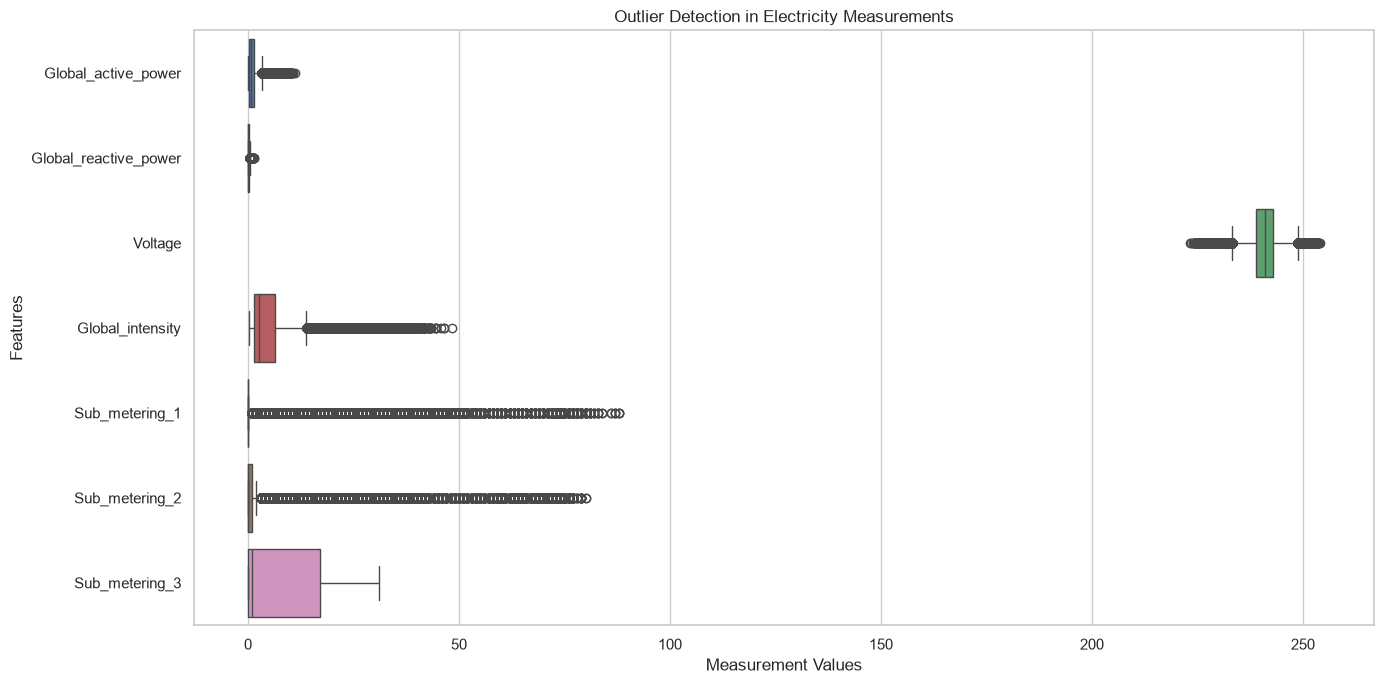

In [168]:
# Cell 38: Outlier Visualization

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df_clean[measurement_columns],
    orient="h"
)

plt.title("Outlier Detection in Electricity Measurements")
plt.xlabel("Measurement Values")
plt.ylabel("Features")

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_PATH, "preprocessing_outliers.png"),
    bbox_inches="tight"
)

plt.show()

In [169]:
# Cell 39: Identify Unusual Active Power Readings

active_power_q1 = df_clean["Global_active_power"].quantile(0.25)
active_power_q3 = df_clean["Global_active_power"].quantile(0.75)

active_power_iqr = active_power_q3 - active_power_q1

active_power_upper = (
    active_power_q3 + 1.5 * active_power_iqr
)

unusual_readings = df_clean[
    df_clean["Global_active_power"] > active_power_upper
]

print("Upper IQR Threshold:", active_power_upper, "kW")
print("Unusual High Consumption Readings:", len(unusual_readings))

display(unusual_readings.head(10))

Upper IQR Threshold: 3.358 kW
Unusual High Consumption Readings: 94922


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
DateTime,,,,,,,,,
2006-12-16 17:24:00,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0
2006-12-16 17:29:00,16/12/2006,17:29:00,3.520,0.522,235.02,15.0,0.0,2.0,17.0
2006-12-16 17:30:00,16/12/2006,17:30:00,3.702,0.520,235.09,15.8,0.0,1.0,17.0
2006-12-16 17:31:00,16/12/2006,17:31:00,3.700,0.520,235.22,15.8,0.0,1.0,17.0
2006-12-16 17:32:00,16/12/2006,17:32:00,3.668,0.510,233.99,15.8,0.0,1.0,17.0


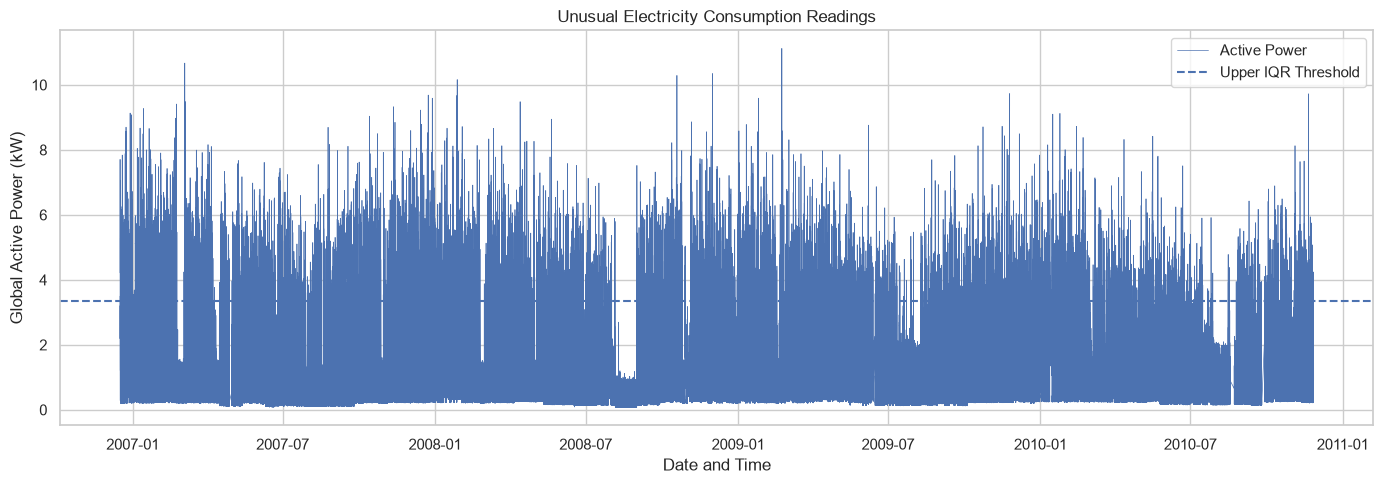

In [170]:
# Cell 40: Unusual Consumption Visualization

plt.figure(figsize=(14, 5))

plt.plot(
    df_clean.index,
    df_clean["Global_active_power"],
    linewidth=0.5,
    label="Active Power"
)

plt.axhline(
    active_power_upper,
    linestyle="--",
    label="Upper IQR Threshold"
)

plt.title("Unusual Electricity Consumption Readings")
plt.xlabel("Date and Time")
plt.ylabel("Global Active Power (kW)")
plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_PATH, "unusual_consumption.png"),
    bbox_inches="tight"
)

plt.show()

In [171]:
# Cell 41: Outlier Treatment Decision

print("Total Records Before Outlier Treatment:", len(df_clean))

print("Outliers Detected:", int(outlier_mask.sum().sum()))

print("Decision: Genuine high consumption readings are preserved.")

print(
    "Reason: Peak electricity demand is important "
    "for forecasting and energy management."
)

Total Records Before Outlier Treatment: 2049436
Outliers Detected: 533674
Decision: Genuine high consumption readings are preserved.
Reason: Peak electricity demand is important for forecasting and energy management.


In [172]:
# Cell 42: Chronological Train-Test Split

split_index = int(len(df_clean) * 0.80)

train_data = df_clean.iloc[:split_index].copy()
test_data = df_clean.iloc[split_index:].copy()

print("Training Records:", len(train_data))
print("Testing Records:", len(test_data))

print("\nTraining Period:")
print(train_data.index.min(), "to", train_data.index.max())

print("\nTesting Period:")
print(test_data.index.min(), "to", test_data.index.max())

assert train_data.index.max() < test_data.index.min()

print("\nChronological Split Verified!")

Training Records: 1639548
Testing Records: 409888

Training Period:
2006-12-16 17:24:00 to 2010-02-05 04:19:00

Testing Period:
2010-02-05 04:20:00 to 2010-11-26 21:02:00

Chronological Split Verified!


In [173]:
# Cell 43: Standard Scaling

standard_scaler = StandardScaler()

train_scaled = train_data.copy()
test_scaled = test_data.copy()

train_scaled[measurement_columns] = standard_scaler.fit_transform(
    train_data[measurement_columns]
)

test_scaled[measurement_columns] = standard_scaler.transform(
    test_data[measurement_columns]
)

print("Standardization Completed!")
print("\nTraining Data Scaled:")
display(train_scaled[measurement_columns].head())

print("\nTesting Data Scaled:")
display(test_scaled[measurement_columns].head())

Standardization Completed!

Training Data Scaled:


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
DateTime,,,,,,,
2006-12-16 17:24:00,2.840999,2.639201,-1.758239,2.979193,-0.184678,-0.059105,1.269279
2006-12-16 17:25:00,3.887549,2.799734,-2.119735,3.980199,-0.184678,-0.059105,1.150155
2006-12-16 17:26:00,3.900357,3.352681,-2.221312,3.980199,-0.184678,0.106813,1.269279
2006-12-16 17:27:00,3.913164,3.388355,-2.086871,3.980199,-0.184678,-0.059105,1.269279
2006-12-16 17:28:00,2.337849,3.620236,-1.507283,2.413407,-0.184678,-0.059105,1.269279



Testing Data Scaled:


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
DateTime,,,,,,,
2010-02-05 04:20:00,-0.697514,-0.410924,1.683441,-0.676657,-0.184678,-0.059105,-0.636706
2010-02-05 04:21:00,-0.701173,-0.393087,1.868670,-0.720179,-0.184678,-0.059105,-0.755830
2010-02-05 04:22:00,-0.695684,-0.375250,1.961285,-0.676657,-0.184678,-0.059105,-0.636706
2010-02-05 04:23:00,-0.703003,-0.393087,1.859707,-0.720179,-0.184678,0.106813,-0.636706
2010-02-05 04:24:00,-0.704832,-0.410924,1.569913,-0.720179,-0.184678,-0.059105,-0.755830


In [174]:
# Cell 44: Min-Max Normalization

minmax_scaler = MinMaxScaler()

train_normalized = train_data.copy()
test_normalized = test_data.copy()

train_normalized[measurement_columns] = minmax_scaler.fit_transform(
    train_data[measurement_columns]
)

test_normalized[measurement_columns] = minmax_scaler.transform(
    test_data[measurement_columns]
)

print("Min-Max Normalization Completed!")

print("\nTraining Normalized Data:")
display(train_normalized[measurement_columns].head())

print("\nTesting Normalized Data:")
display(test_normalized[measurement_columns].head())

Min-Max Normalization Completed!

Training Normalized Data:


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
DateTime,,,,,,,
2006-12-16 17:24:00,0.374796,0.300719,0.376090,0.377593,0.0,0.012658,0.548387
2006-12-16 17:25:00,0.478363,0.313669,0.336995,0.473029,0.0,0.012658,0.516129
2006-12-16 17:26:00,0.479631,0.358273,0.326010,0.473029,0.0,0.025316,0.548387
2006-12-16 17:27:00,0.480898,0.361151,0.340549,0.473029,0.0,0.012658,0.548387
2006-12-16 17:28:00,0.325005,0.379856,0.403231,0.323651,0.0,0.012658,0.548387



Testing Normalized Data:


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
DateTime,,,,,,,
2010-02-05 04:20:00,0.024624,0.054676,0.748304,0.029046,0.0,0.012658,0.032258
2010-02-05 04:21:00,0.024262,0.056115,0.768336,0.024896,0.0,0.012658,0.000000
2010-02-05 04:22:00,0.024805,0.057554,0.778352,0.029046,0.0,0.012658,0.032258
2010-02-05 04:23:00,0.024081,0.056115,0.767367,0.024896,0.0,0.025316,0.032258
2010-02-05 04:24:00,0.023900,0.054676,0.736026,0.024896,0.0,0.012658,0.000000


In [175]:
# Cell 45: Scaling Comparison

scaling_comparison = pd.DataFrame({
    "Original Mean": train_data[measurement_columns].mean(),
    "Standard Scaled Mean": train_scaled[measurement_columns].mean(),
    "MinMax Minimum": train_normalized[measurement_columns].min(),
    "MinMax Maximum": train_normalized[measurement_columns].max()
})

display(scaling_comparison)

,Original Mean,Standard Scaled Mean,MinMax Minimum,MinMax Maximum
Global_active_power,1.110463,-8.875565e-18,0.0,1.0
Global_reactive_power,0.122075,-1.375713e-16,0.0,1.0
Voltage,240.725182,2.840181e-15,0.0,1.0
Global_intensity,4.709491,8.431787e-17,0.0,1.0
Sub_metering_1,1.162475,-4.437783e-17,0.0,1.0
Sub_metering_2,1.356229,-4.437783e-18,0.0,1.0
Sub_metering_3,6.344896,6.656674e-18,0.0,1.0


In [176]:
# Cell 46: Ensure Chronological Order

df_clean = df_clean.sort_index()

print("Chronological Sorting Completed!")

print("Is Chronologically Sorted:",
      df_clean.index.is_monotonic_increasing)

print("First Timestamp:", df_clean.index.min())
print("Last Timestamp:", df_clean.index.max())

assert df_clean.index.is_monotonic_increasing

print("Time-Series Ordering Verified!")

Chronological Sorting Completed!
Is Chronologically Sorted: True
First Timestamp: 2006-12-16 17:24:00
Last Timestamp: 2010-11-26 21:02:00
Time-Series Ordering Verified!


In [177]:
# Cell 47: Final Data Quality Check

final_quality = {
    "Total Records": len(df_clean),
    "Total Features": len(df_clean.columns),
    "Missing Values": int(df_clean.isnull().sum().sum()),
    "Duplicate Rows": int(df_clean.duplicated().sum()),
    "Duplicate Timestamps": int(df_clean.index.duplicated().sum()),
    "Invalid DateTime": int(df_clean.index.isna().sum()),
    "Negative Measurements": int(
        (df_clean[measurement_columns] < 0).sum().sum()
    ),
    "Non-Positive Voltage": int(
        (df_clean["Voltage"] <= 0).sum()
    ),
    "Chronological Order": df_clean.index.is_monotonic_increasing
}

final_quality_df = pd.DataFrame(
    list(final_quality.items()),
    columns=["Quality Check", "Result"]
)

display(final_quality_df)

assert df_clean.isnull().sum().sum() == 0
assert df_clean.index.is_monotonic_increasing
assert df_clean.index.duplicated().sum() == 0

print("Final Data Quality Validation Passed!")

,Quality Check,Result
0,Total Records,2049436
1,Total Features,9
2,Missing Values,0
3,Duplicate Rows,0
4,Duplicate Timestamps,0
5,Invalid DateTime,0
6,Negative Measurements,0
7,Non-Positive Voltage,0
8,Chronological Order,True


Final Data Quality Validation Passed!


In [178]:
# Cell 48: Save Cleaned Dataset

df_clean.to_csv(
    CLEANED_PATH,
    index=True,
    index_label="DateTime"
)

print("Cleaned Dataset Saved Successfully!")
print("File:", CLEANED_PATH)
print("Final Shape:", df_clean.shape)

Cleaned Dataset Saved Successfully!
File: ../dataset/cleaned_energy_consumption.csv
Final Shape: (2049436, 9)


In [179]:
# Cell 49: Export Preprocessing Results

import joblib

final_quality_df.to_csv(
    os.path.join(OUTPUT_PATH, "preprocessing_quality_report.csv"),
    index=False
)

outlier_summary.to_csv(
    os.path.join(OUTPUT_PATH, "outlier_analysis.csv")
)

joblib.dump(
    standard_scaler,
    "../models/standard_scaler.pkl"
)

joblib.dump(
    minmax_scaler,
    "../models/minmax_scaler.pkl"
)

print("Preprocessing reports saved successfully!")
print("Scaler files saved successfully!")

Preprocessing reports saved successfully!
Scaler files saved successfully!


In [180]:
# Cell 50: Final Preprocessing Summary

print("=" * 65)
print("SMART ENERGY CONSUMPTION FORECASTING")
print("DATA CLEANING AND PREPROCESSING SUMMARY")
print("=" * 65)

print("Original Dataset Records: 2,075,259")
print("Final Cleaned Records:", len(df_clean))
print("Final Features:", len(df_clean.columns))

print("Remaining Missing Values:",
      df_clean.isnull().sum().sum())

print("Remaining Duplicate Timestamps:",
      df_clean.index.duplicated().sum())

print("Outliers Detected:",
      int(outlier_mask.sum().sum()))

print("Chronological Order:",
      df_clean.index.is_monotonic_increasing)

print("\nCleaned Dataset:", CLEANED_PATH)
print("\nPREPROCESSING COMPLETED SUCCESSFULLY!")

SMART ENERGY CONSUMPTION FORECASTING
DATA CLEANING AND PREPROCESSING SUMMARY
Original Dataset Records: 2,075,259
Final Cleaned Records: 2049436
Final Features: 9
Remaining Missing Values: 0
Remaining Duplicate Timestamps: 0
Outliers Detected: 533674
Chronological Order: True

Cleaned Dataset: ../dataset/cleaned_energy_consumption.csv

PREPROCESSING COMPLETED SUCCESSFULLY!


In [181]:
# Cell 51: Import Libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("EDA Libraries Imported Successfully!")


EDA Libraries Imported Successfully!


In [182]:
# Cell 52: Load the Cleaned Dataset

CLEANED_PATH = "../dataset/cleaned_energy_consumption.csv"
EDA_OUTPUT_PATH = "../visualizations/eda"

os.makedirs(EDA_OUTPUT_PATH, exist_ok=True)

df_eda = pd.read_csv(
    CLEANED_PATH,
    parse_dates=["DateTime"],
    index_col="DateTime"
)

df_eda = df_eda.sort_index()

print("Cleaned Dataset Loaded Successfully!")
print("Dataset Shape:", df_eda.shape)
display(df_eda.head())


Cleaned Dataset Loaded Successfully!
Dataset Shape: (2049436, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
DateTime,,,,,,,,,
2006-12-16 17:24:00,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [183]:
# Cell 53: Verify Dataset for EDA

print("Missing Values:", df_eda.isnull().sum().sum())
print("Duplicate Timestamps:", df_eda.index.duplicated().sum())
print("Chronological Order:", df_eda.index.is_monotonic_increasing)
print("Start Date:", df_eda.index.min())
print("End Date:", df_eda.index.max())

assert df_eda.index.is_monotonic_increasing
assert df_eda.index.duplicated().sum() == 0
assert df_eda["Global_active_power"].notna().all()

print("\nEDA Dataset Validation Passed!")


Missing Values: 0
Duplicate Timestamps: 0
Chronological Order: True
Start Date: 2006-12-16 17:24:00
End Date: 2010-11-26 21:02:00

EDA Dataset Validation Passed!


In [184]:
# Cell 54: Create Time-Based Features

df_eda["Hour"] = df_eda.index.hour
df_eda["Day"] = df_eda.index.day
df_eda["DayOfWeek"] = df_eda.index.dayofweek
df_eda["DayName"] = df_eda.index.day_name()
df_eda["Month"] = df_eda.index.month
df_eda["MonthName"] = df_eda.index.month_name()
df_eda["Year"] = df_eda.index.year

df_eda["IsWeekend"] = np.where(
    df_eda["DayOfWeek"] >= 5,
    "Weekend",
    "Weekday"
)

df_eda["Season"] = df_eda["Month"].map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
})

print("Time-Based Features Created!")
display(df_eda.head())


Time-Based Features Created!


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Day,DayOfWeek,DayName,Month,MonthName,Year,IsWeekend,Season
DateTime,,,,,,,,,,,,,,,,,,
2006-12-16 17:24:00,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,17,16,5,Saturday,12,December,2006,Weekend,Winter
2006-12-16 17:25:00,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,17,16,5,Saturday,12,December,2006,Weekend,Winter
2006-12-16 17:26:00,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,17,16,5,Saturday,12,December,2006,Weekend,Winter
2006-12-16 17:27:00,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,17,16,5,Saturday,12,December,2006,Weekend,Winter
2006-12-16 17:28:00,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,17,16,5,Saturday,12,December,2006,Weekend,Winter


In [185]:
# Cell 55: Overall Electricity Consumption Statistics

power = df_eda["Global_active_power"]

consumption_statistics = pd.DataFrame({
    "Metric": [
        "Average Active Power",
        "Maximum Active Power",
        "Minimum Active Power",
        "Median Active Power",
        "Standard Deviation"
    ],
    "Value (kW)": [
        power.mean(),
        power.max(),
        power.min(),
        power.median(),
        power.std()
    ]
})

display(consumption_statistics)

print("Overall Average Power:", round(power.mean(), 4), "kW")
print("Maximum Power:", round(power.max(), 4), "kW")
print("Minimum Power:", round(power.min(), 4), "kW")


,Metric,Value (kW)
0,Average Active Power,1.091635
1,Maximum Active Power,11.122000
2,Minimum Active Power,0.076000
3,Median Active Power,0.602000
4,Standard Deviation,1.057310


Overall Average Power: 1.0916 kW
Maximum Power: 11.122 kW
Minimum Power: 0.076 kW


In [186]:
# Cell 56: Convert Minute-Level Power into Hourly Energy

# Global_active_power is measured in kW.
# Hourly energy (kWh) = Average hourly power (kW) x 1 hour.
# Accept an hour only when at least 54 out of 60 readings are available.

MIN_HOURLY_READINGS = 54

hourly_average_power = (
    df_eda["Global_active_power"]
    .resample("h")
    .mean()
)

hourly_reading_count = (
    df_eda["Global_active_power"]
    .resample("h")
    .count()
)

hourly_energy = hourly_average_power.where(
    hourly_reading_count >= MIN_HOURLY_READINGS
).dropna()

hourly_power = hourly_average_power.where(
    hourly_reading_count >= MIN_HOURLY_READINGS
).dropna()

print("Hourly Energy Dataset Created!")
print("Total Hourly Slots:", len(hourly_average_power))
print("Valid Hourly Records:", len(hourly_energy))
print("Incomplete Hourly Records:",
      int((hourly_reading_count < MIN_HOURLY_READINGS).sum()))

print("Average Hourly Energy:",
      round(hourly_energy.mean(), 4), "kWh")

print("\nHourly Energy Preview:")
display(hourly_energy.head())

assert hourly_energy.notna().all()
assert (hourly_reading_count.loc[hourly_energy.index] >= MIN_HOURLY_READINGS).all()

print("\nHourly Energy Validation Passed!")


Hourly Energy Dataset Created!
Total Hourly Slots: 34589
Valid Hourly Records: 34146
Incomplete Hourly Records: 443
Average Hourly Energy: 1.0915 kWh

Hourly Energy Preview:


DateTime
2006-12-16 18:00:00    3.632200
2006-12-16 19:00:00    3.400233
2006-12-16 20:00:00    3.268567
2006-12-16 21:00:00    3.056467
2006-12-16 22:00:00    2.200133
Name: Global_active_power, dtype: float64


Hourly Energy Validation Passed!


In [187]:
# Cell 57: Create Daily, Weekly and Monthly Energy Consumption

# Use hourly energy calculated in Cell 56.
# A day is accepted only when all 24 hourly records are valid.
# Weekly and monthly totals are accepted only when all expected
# hourly records are available.

# Daily energy
daily_energy_raw = hourly_energy.resample("D").sum(min_count=24)
daily_hour_count = hourly_energy.resample("D").count()

daily_energy = daily_energy_raw.where(
    daily_hour_count == 24
).dropna()

# Weekly energy (Monday to Sunday)
weekly_energy_raw = hourly_energy.resample("W-SUN").sum(min_count=168)
weekly_hour_count = hourly_energy.resample("W-SUN").count()

weekly_energy = weekly_energy_raw.where(
    weekly_hour_count == 168
).dropna()

# Monthly energy
monthly_energy_raw = hourly_energy.resample("MS").sum(min_count=1)
monthly_hour_count = hourly_energy.resample("MS").count()

expected_monthly_hours = monthly_hour_count.index.days_in_month * 24

monthly_energy = monthly_energy_raw.where(
    monthly_hour_count == expected_monthly_hours
).dropna()

print("Daily Energy Records:", len(daily_energy))
print("Weekly Energy Records:", len(weekly_energy))
print("Monthly Energy Records:", len(monthly_energy))

print("\nAverage Daily Energy:",
      round(daily_energy.mean(), 3), "kWh")

print("Maximum Daily Energy:",
      round(daily_energy.max(), 3), "kWh")

print("Minimum Daily Energy:",
      round(daily_energy.min(), 3), "kWh")

print("\nAverage Weekly Energy:",
      round(weekly_energy.mean(), 3), "kWh")

print("Average Monthly Energy:",
      round(monthly_energy.mean(), 3), "kWh")

print("\nDaily Energy Preview:")
display(daily_energy.head())

print("\nWeekly Energy Preview:")
display(weekly_energy.head())

print("\nMonthly Energy Preview:")
display(monthly_energy.head())

assert daily_hour_count.loc[daily_energy.index].eq(24).all()
assert weekly_hour_count.loc[weekly_energy.index].eq(168).all()

print("\nDaily, Weekly and Monthly Energy Validation Completed!")


Daily Energy Records: 1411
Weekly Energy Records: 188
Monthly Energy Records: 33

Average Daily Energy: 26.208 kWh
Maximum Daily Energy: 79.556 kWh
Minimum Daily Energy: 4.172 kWh

Average Weekly Energy: 184.434 kWh
Average Monthly Energy: 823.107 kWh

Daily Energy Preview:


DateTime
2006-12-17    56.507667
2006-12-18    36.730433
2006-12-19    27.769900
2006-12-20    37.095800
2006-12-21    28.618533
Name: Global_active_power, dtype: float64


Weekly Energy Preview:


DateTime
2006-12-24    291.293600
2006-12-31    329.149233
2007-01-07    249.351133
2007-01-14    269.659267
2007-01-21    275.427767
Name: Global_active_power, dtype: float64


Monthly Energy Preview:


DateTime
2007-01-01    1150.287167
2007-02-01     941.582967
2007-03-01     981.042900
2007-05-01     733.481200
2007-09-01     697.997900
Name: Global_active_power, dtype: float64


Daily, Weekly and Monthly Energy Validation Completed!


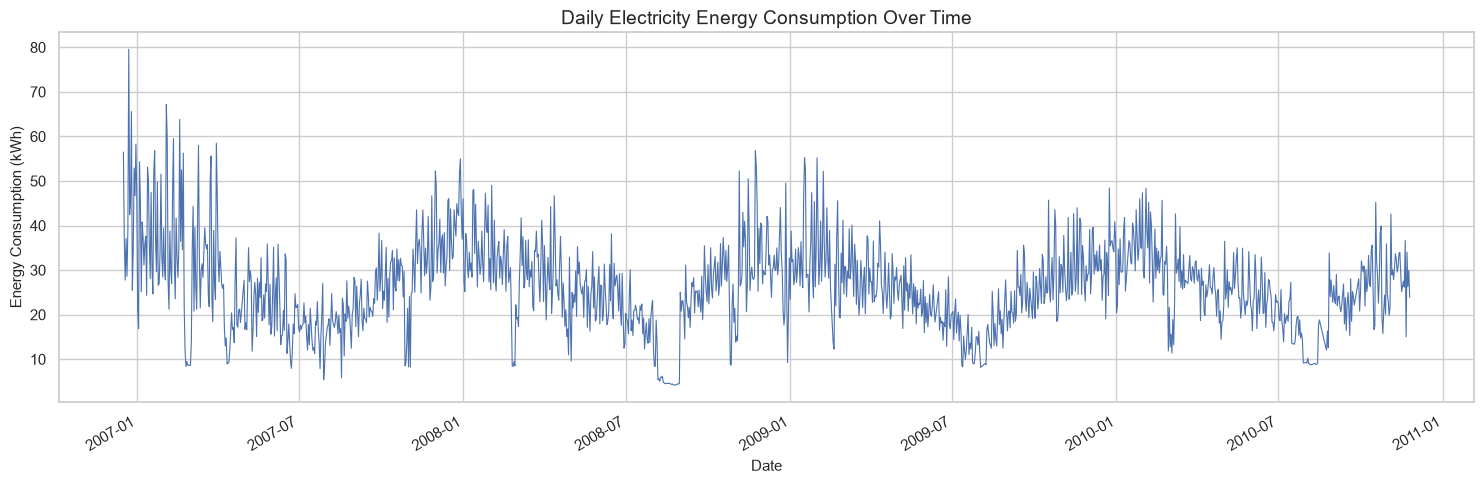

In [188]:
# Cell 58: Electricity Consumption Over Time - Line Chart

plt.figure(figsize=(15, 5))

daily_energy.plot(linewidth=0.8)

plt.title("Daily Electricity Energy Consumption Over Time")
plt.xlabel("Date")
plt.ylabel("Energy Consumption (kWh)")
plt.tight_layout()

plt.savefig(
    os.path.join(EDA_OUTPUT_PATH, "daily_consumption_trend.png"),
    dpi=300
)

plt.show()


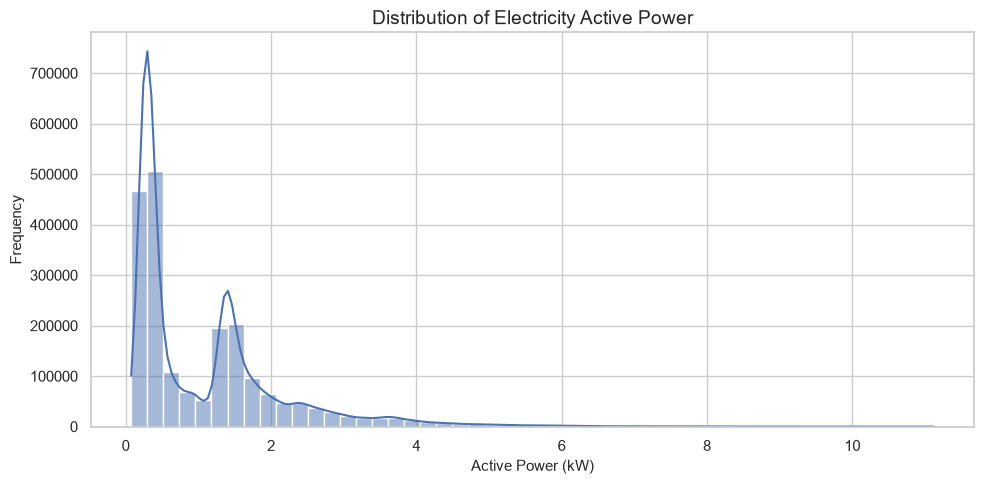

In [189]:
# Cell 59: Electricity Consumption Distribution - Histogram

plt.figure(figsize=(10, 5))

sns.histplot(
    power,
    bins=50,
    kde=True
)

plt.title("Distribution of Electricity Active Power")
plt.xlabel("Active Power (kW)")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    os.path.join(EDA_OUTPUT_PATH, "power_distribution_histogram.png"),
    dpi=300
)

plt.show()


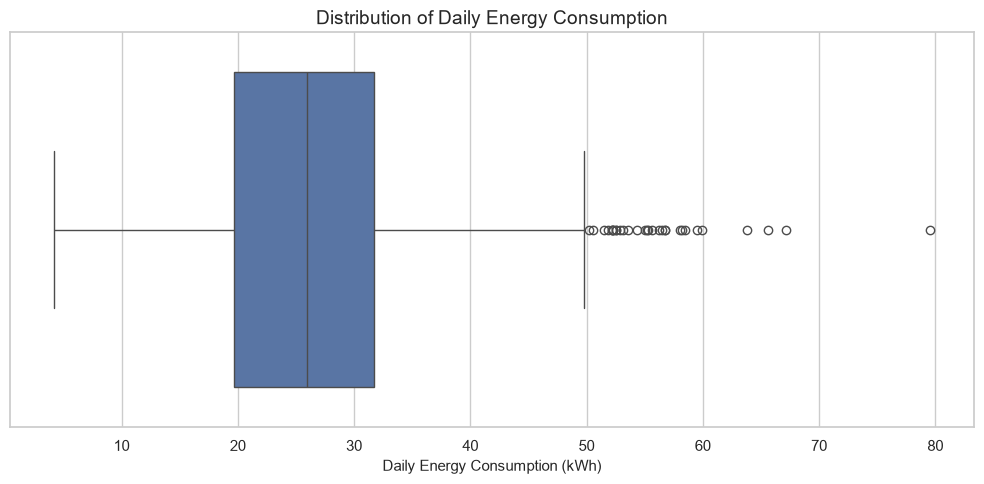

In [190]:
# Cell 60: Daily Consumption Box Plot

plt.figure(figsize=(10, 5))

sns.boxplot(x=daily_energy)

plt.title("Distribution of Daily Energy Consumption")
plt.xlabel("Daily Energy Consumption (kWh)")
plt.tight_layout()

plt.savefig(
    os.path.join(EDA_OUTPUT_PATH, "daily_consumption_boxplot.png"),
    dpi=300
)

plt.show()


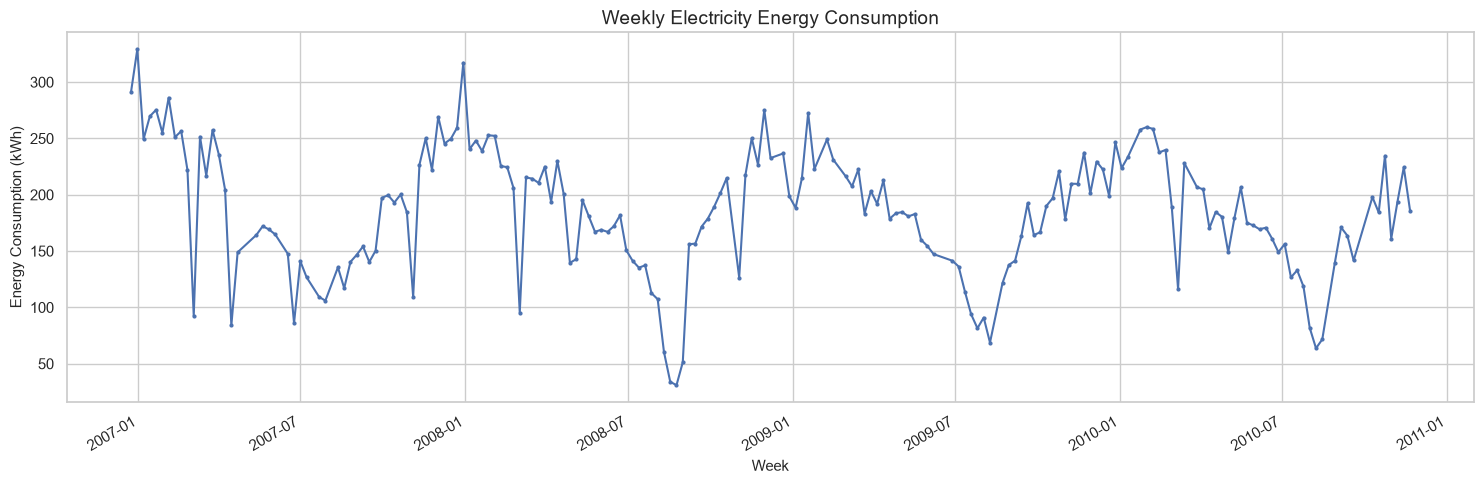

In [191]:
# Cell 61: Weekly Electricity Consumption Pattern

plt.figure(figsize=(15, 5))

weekly_energy.plot(
    kind="line",
    marker="o",
    markersize=2
)

plt.title("Weekly Electricity Energy Consumption")
plt.xlabel("Week")
plt.ylabel("Energy Consumption (kWh)")
plt.tight_layout()

plt.savefig(
    os.path.join(EDA_OUTPUT_PATH, "weekly_consumption_trend.png"),
    dpi=300
)

plt.show()


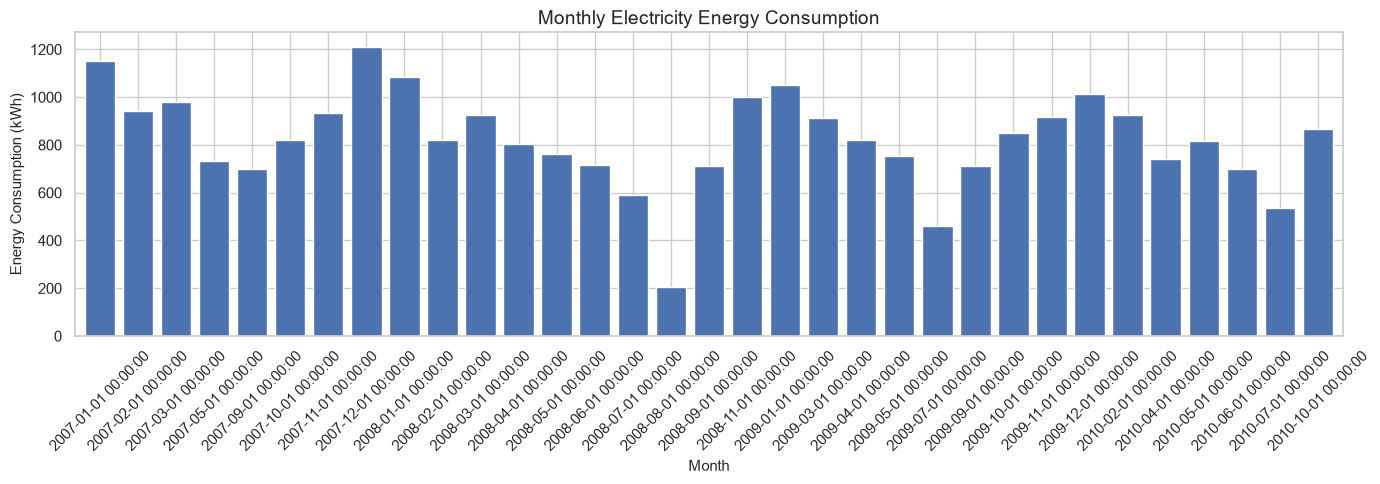

In [192]:
# Cell 62: Monthly Electricity Consumption Bar Chart

plt.figure(figsize=(14, 5))

monthly_energy.plot(kind="bar", width=0.8)

plt.title("Monthly Electricity Energy Consumption")
plt.xlabel("Month")
plt.ylabel("Energy Consumption (kWh)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    os.path.join(EDA_OUTPUT_PATH, "monthly_consumption_bar.png"),
    dpi=300
)

plt.show()


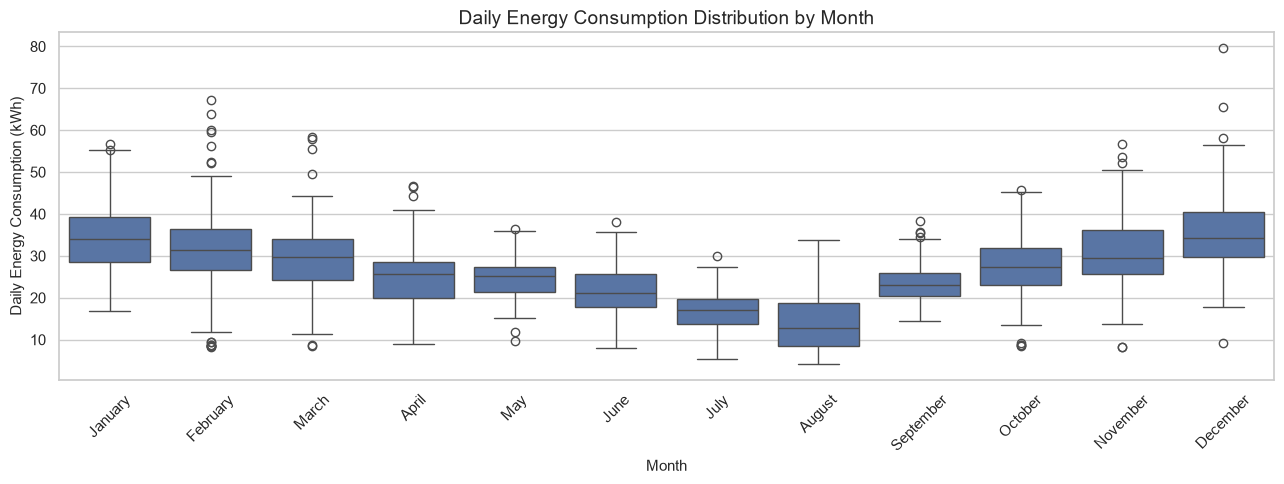

Monthly Consumption Box Plot Created!


In [193]:
# Cell 63: Monthly Consumption Box Plot

# Use only complete daily energy values from Cell 57.
monthly_box_data = daily_energy.to_frame(
    "DailyEnergy_kWh"
).copy()

monthly_box_data["MonthName"] = (
    monthly_box_data.index.month_name()
)

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

plt.figure(figsize=(13, 5))

sns.boxplot(
    data=monthly_box_data,
    x="MonthName",
    y="DailyEnergy_kWh",
    order=month_order
)

plt.title("Daily Energy Consumption Distribution by Month")
plt.xlabel("Month")
plt.ylabel("Daily Energy Consumption (kWh)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    os.path.join(EDA_OUTPUT_PATH, "monthly_consumption_boxplot.png"),
    dpi=300
)

plt.show()

print("Monthly Consumption Box Plot Created!")


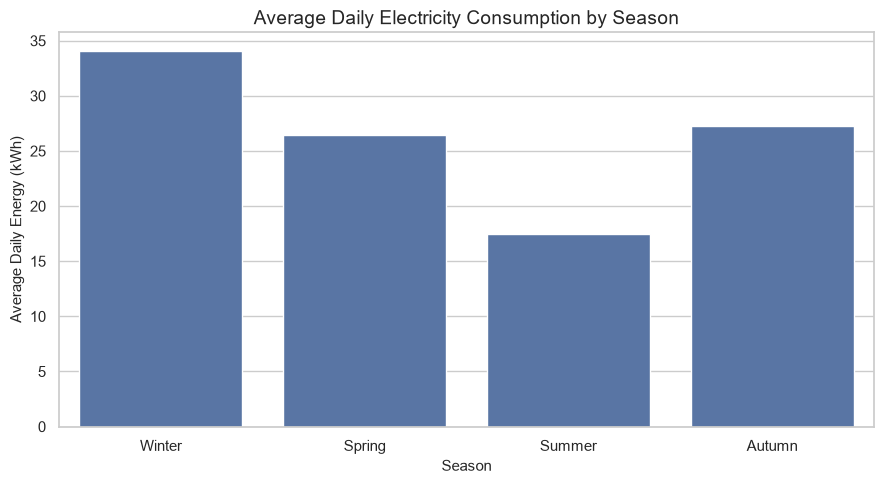

,Average_Daily_Energy_kWh
Season,
Winter,34.042904
Spring,26.481736
Summer,17.424966
Autumn,27.233034


Seasonal Consumption Analysis Completed!


In [194]:
# Cell 64: Seasonal Electricity Consumption

# Use complete daily energy values from Cell 57.
seasonal_data = daily_energy.to_frame(
    "Daily_Energy_kWh"
).copy()

seasonal_data["Month"] = seasonal_data.index.month

seasonal_data["Season"] = seasonal_data["Month"].map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
})

season_order = ["Winter", "Spring", "Summer", "Autumn"]

seasonal_energy = (
    seasonal_data.groupby("Season")["Daily_Energy_kWh"]
    .mean()
    .reindex(season_order)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=seasonal_energy.index,
    y=seasonal_energy.values
)

plt.title("Average Daily Electricity Consumption by Season")
plt.xlabel("Season")
plt.ylabel("Average Daily Energy (kWh)")
plt.tight_layout()

plt.savefig(
    os.path.join(EDA_OUTPUT_PATH, "seasonal_consumption.png"),
    dpi=300
)

plt.show()

display(
    seasonal_energy.to_frame("Average_Daily_Energy_kWh")
)

print("Seasonal Consumption Analysis Completed!")


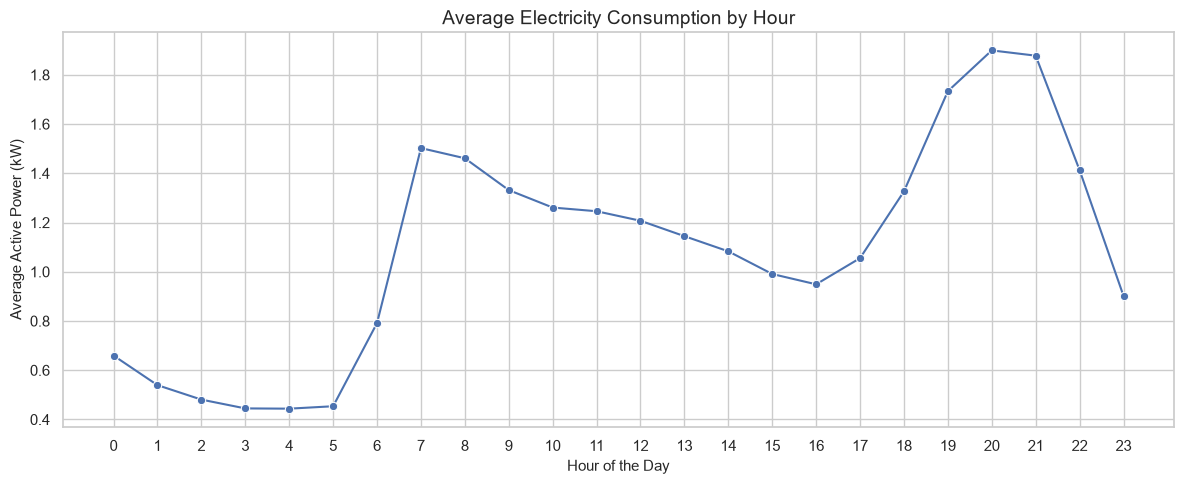

,Average_Power_kW
Hour,
0,0.659406
1,0.539325
2,0.480618
3,0.444851
4,0.443843
5,0.453660
6,0.791633
7,1.502264
8,1.460957


In [195]:
# Cell 65: Average Electricity Consumption by Hour

hourly_pattern = df_eda.groupby("Hour")[
    "Global_active_power"
].mean()

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hourly_pattern.index,
    y=hourly_pattern.values,
    marker="o"
)

plt.title("Average Electricity Consumption by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Active Power (kW)")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(EDA_OUTPUT_PATH, "hourly_consumption_pattern.png"),
    dpi=300
)

plt.show()

display(hourly_pattern.to_frame("Average_Power_kW"))


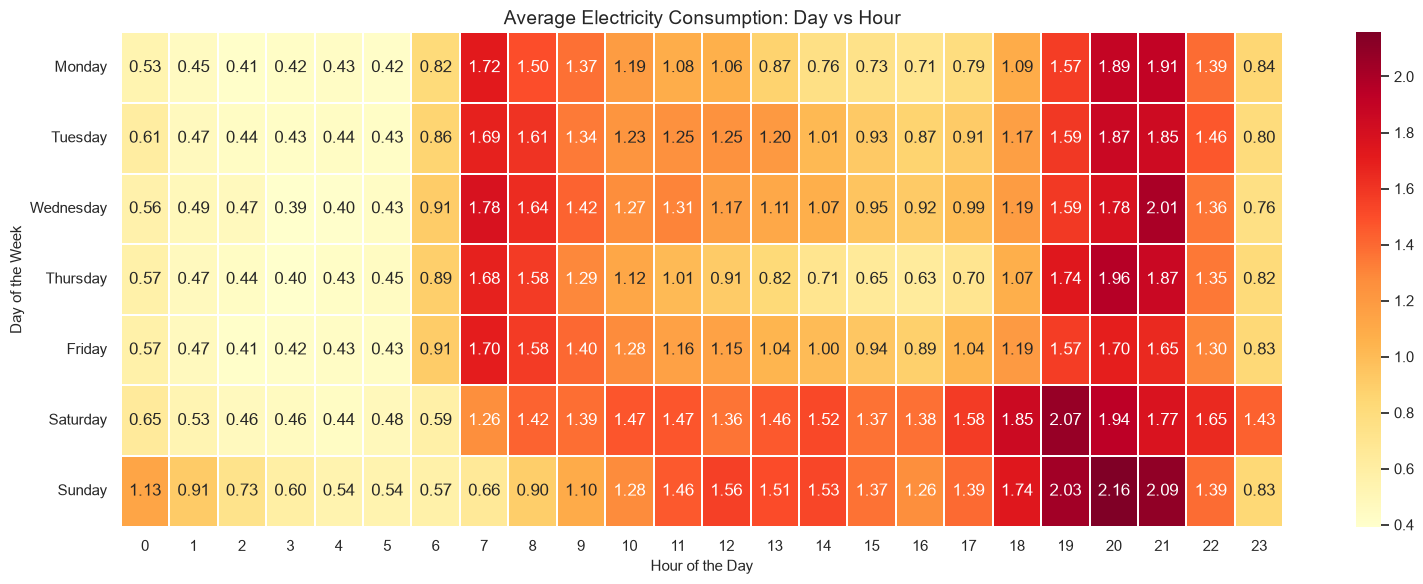

In [196]:
# Cell 66: Hourly and Daily Consumption Heatmap

heatmap_data = df_eda.pivot_table(
    values="Global_active_power",
    index="DayOfWeek",
    columns="Hour",
    aggfunc="mean"
)

heatmap_data = heatmap_data.reindex(range(7))

heatmap_data.index = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

plt.figure(figsize=(16, 6))

sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    annot=True,
    fmt=".2f",
    linewidths=0.3
)

plt.title("Average Electricity Consumption: Day vs Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Day of the Week")
plt.tight_layout()

plt.savefig(
    os.path.join(EDA_OUTPUT_PATH, "hourly_daily_heatmap.png"),
    dpi=300
)

plt.show()


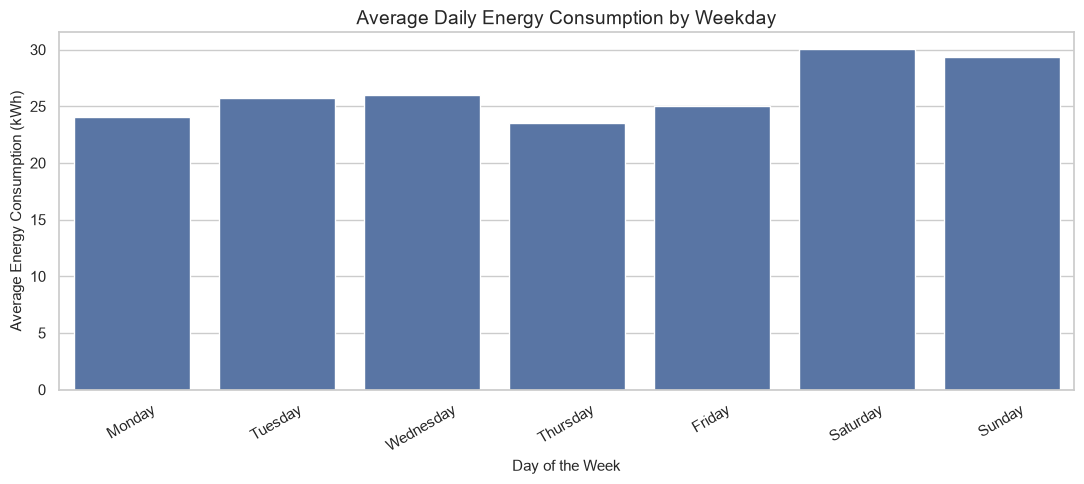

,Average_Daily_Energy_kWh
DayName,
Monday,24.020806
Tuesday,25.725784
Wednesday,25.971053
Thursday,23.531600
Friday,25.027542
Saturday,30.009434
Sunday,29.328569


In [197]:
# Cell 67: Average Daily Consumption by Day of the Week

daily_pattern = daily_energy.to_frame("Energy_kWh")

daily_pattern["DayOfWeek"] = daily_pattern.index.dayofweek

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

daily_pattern["DayName"] = daily_pattern.index.day_name()

day_average = (
    daily_pattern.groupby("DayName")["Energy_kWh"]
    .mean()
    .reindex(weekday_order)
)

plt.figure(figsize=(11, 5))

sns.barplot(
    x=day_average.index,
    y=day_average.values
)

plt.title("Average Daily Energy Consumption by Weekday")
plt.xlabel("Day of the Week")
plt.ylabel("Average Energy Consumption (kWh)")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    os.path.join(EDA_OUTPUT_PATH, "weekday_consumption.png"),
    dpi=300
)

plt.show()

display(day_average.to_frame("Average_Daily_Energy_kWh"))


In [198]:
# Cell 68: Identify Peak Hourly Consumption

peak_hour = hourly_energy.idxmax()
minimum_hour = hourly_energy.idxmin()

peak_hour_value = hourly_energy.max()
minimum_hour_value = hourly_energy.min()

print("Peak Hour:", peak_hour)
print("Peak Hour Energy:", round(peak_hour_value, 4), "kWh")

print("\nMinimum Consumption Hour:", minimum_hour)
print("Minimum Hour Energy:", round(minimum_hour_value, 4), "kWh")

peak_hours = hourly_energy.sort_values(
    ascending=False
).head(10)

print("\nTop 10 Peak Consumption Hours:")
display(peak_hours.to_frame("Energy_kWh"))


Peak Hour: 2008-11-23 18:00:00
Peak Hour Energy: 6.5605 kWh

Minimum Consumption Hour: 2008-08-23 21:00:00
Minimum Hour Energy: 0.124 kWh

Top 10 Peak Consumption Hours:


,Energy_kWh
DateTime,
2008-11-23 18:00:00,6.560533
2009-01-16 20:00:00,6.519633
2008-02-02 19:00:00,6.496033
2007-12-23 19:00:00,6.488000
2007-02-22 21:00:00,6.363867
2007-12-28 17:00:00,6.333667
2008-11-23 20:00:00,6.310567
2007-01-21 20:00:00,6.076567
2008-01-26 19:00:00,6.013800


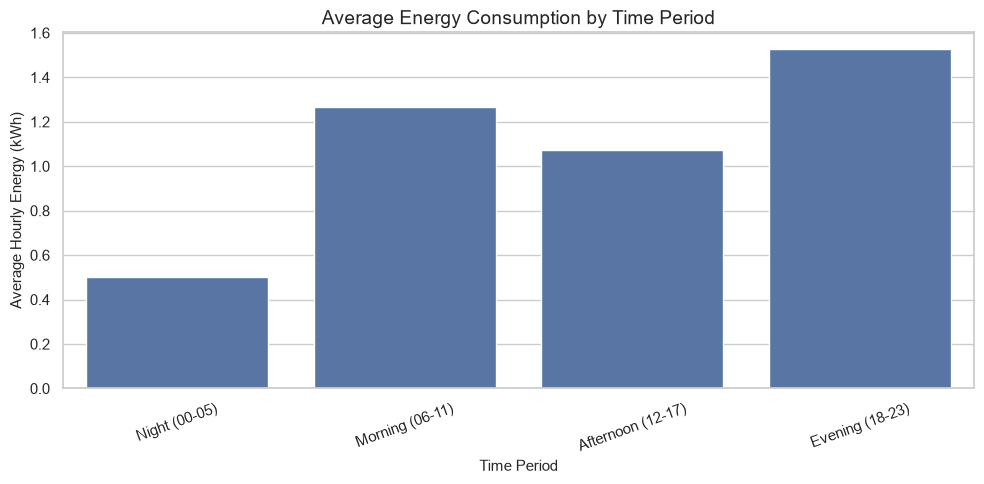

,Average_Hourly_Energy_kWh
Period,
Night (00-05),0.503649
Morning (06-11),1.265440
Afternoon (12-17),1.071379
Evening (18-23),1.525423


In [199]:
# Cell 69: Identify Peak Consumption Periods by Time of Day

peak_period_data = hourly_energy.to_frame("Energy_kWh")

peak_period_data["Hour"] = peak_period_data.index.hour

peak_period_data["Period"] = pd.cut(
    peak_period_data["Hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=[
        "Night (00-05)",
        "Morning (06-11)",
        "Afternoon (12-17)",
        "Evening (18-23)"
    ]
)

period_average = peak_period_data.groupby(
    "Period", observed=False
)["Energy_kWh"].mean()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=period_average.index.astype(str),
    y=period_average.values
)

plt.title("Average Energy Consumption by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Average Hourly Energy (kWh)")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    os.path.join(EDA_OUTPUT_PATH, "peak_consumption_periods.png"),
    dpi=300
)

plt.show()

display(period_average.to_frame("Average_Hourly_Energy_kWh"))


,mean,median,max,min,sum,count
DayType,,,,,,
Weekday,24.853568,24.761883,65.568500,4.171633,25201.518237,1014
Weekend,29.668144,28.612333,79.556433,4.244033,11778.253233,397


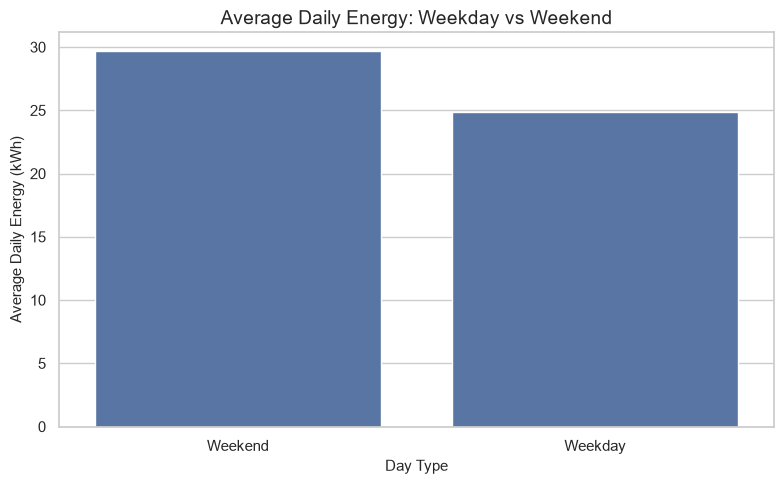

In [200]:
# Cell 70: Compare Weekday and Weekend Energy Consumption

daily_comparison = daily_energy.to_frame("Energy_kWh")

daily_comparison["DayType"] = np.where(
    daily_comparison.index.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

weekday_weekend = daily_comparison.groupby(
    "DayType"
)["Energy_kWh"].agg(
    ["mean", "median", "max", "min", "sum", "count"]
)

display(weekday_weekend)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=daily_comparison,
    x="DayType",
    y="Energy_kWh",
    errorbar=None
)

plt.title("Average Daily Energy: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Daily Energy (kWh)")
plt.tight_layout()

plt.savefig(
    os.path.join(EDA_OUTPUT_PATH, "weekday_vs_weekend.png"),
    dpi=300
)

plt.show()


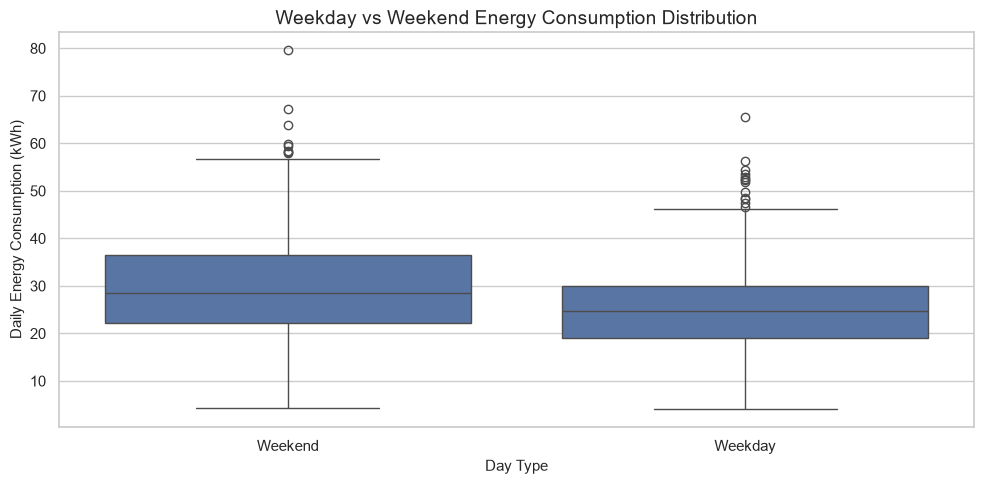

In [201]:
# Cell 71: Weekday and Weekend Consumption Distribution

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=daily_comparison,
    x="DayType",
    y="Energy_kWh"
)

plt.title("Weekday vs Weekend Energy Consumption Distribution")
plt.xlabel("Day Type")
plt.ylabel("Daily Energy Consumption (kWh)")
plt.tight_layout()

plt.savefig(
    os.path.join(EDA_OUTPUT_PATH, "weekday_weekend_boxplot.png"),
    dpi=300
)

plt.show()


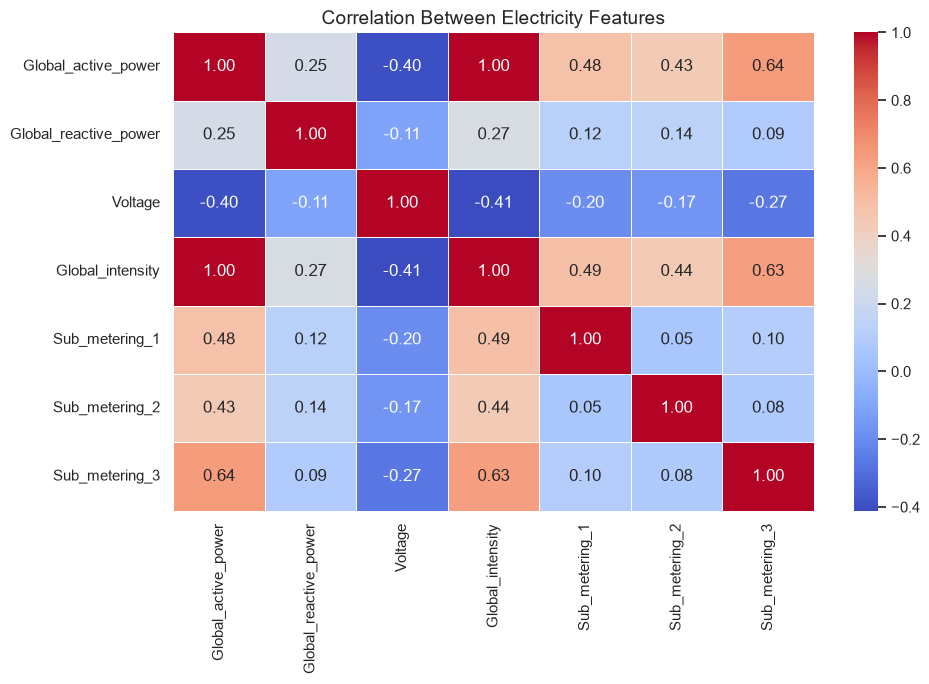

In [202]:
# Cell 72: Correlation Heatmap of Numerical Features

numeric_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

correlation_matrix = df_eda[numeric_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Electricity Features")
plt.tight_layout()

plt.savefig(
    os.path.join(EDA_OUTPUT_PATH, "feature_correlation_heatmap.png"),
    dpi=300
)

plt.show()


In [203]:
# Cell 73: Save EDA Statistics and Analysis Tables

eda_statistics = pd.DataFrame({
    "Metric": [
        "Average Active Power (kW)",
        "Maximum Active Power (kW)",
        "Minimum Active Power (kW)",
        "Average Daily Energy (kWh)",
        "Maximum Daily Energy (kWh)",
        "Minimum Daily Energy (kWh)",
        "Average Hourly Energy (kWh)",
        "Peak Hourly Energy (kWh)"
    ],
    "Value": [
        power.mean(),
        power.max(),
        power.min(),
        daily_energy.mean(),
        daily_energy.max(),
        daily_energy.min(),
        hourly_energy.mean(),
        hourly_energy.max()
    ]
})

eda_statistics.to_csv(
    os.path.join(EDA_OUTPUT_PATH, "eda_statistics.csv"),
    index=False
)

hourly_pattern.to_csv(
    os.path.join(EDA_OUTPUT_PATH, "hourly_pattern.csv")
)

monthly_energy.to_csv(
    os.path.join(EDA_OUTPUT_PATH, "monthly_energy.csv")
)

seasonal_energy.to_csv(
    os.path.join(EDA_OUTPUT_PATH, "seasonal_energy.csv")
)

weekday_weekend.to_csv(
    os.path.join(EDA_OUTPUT_PATH, "weekday_weekend_comparison.csv")
)

peak_hours.to_csv(
    os.path.join(EDA_OUTPUT_PATH, "top_peak_hours.csv")
)

print("EDA Statistics and Analysis Tables Saved Successfully!")


EDA Statistics and Analysis Tables Saved Successfully!


In [204]:
# Cell 74: Final EDA Summary

print("=" * 65)
print("SMART ENERGY CONSUMPTION FORECASTING")
print("EXPLORATORY DATA ANALYSIS SUMMARY")
print("=" * 65)

print("Total Cleaned Records:", len(df_eda))
print("Average Active Power:", round(power.mean(), 4), "kW")
print("Maximum Active Power:", round(power.max(), 4), "kW")
print("Minimum Active Power:", round(power.min(), 4), "kW")

print("\nAverage Daily Energy:",
      round(daily_energy.mean(), 3), "kWh")

print("Maximum Daily Energy:",
      round(daily_energy.max(), 3), "kWh")

print("Minimum Daily Energy:",
      round(daily_energy.min(), 3), "kWh")

print("\nPeak Hour:", peak_hour)
print("Peak Hour Energy:", round(peak_hour_value, 3), "kWh")

print("\nHighest Average Hour:",
      hourly_pattern.idxmax())

print("Highest Average Weekday:",
      day_average.idxmax())

print("Highest Average Seasonal Consumption:",
      seasonal_energy.idxmax())

print("\nEDA Output Folder:", EDA_OUTPUT_PATH)
print("\nEXPLORATORY DATA ANALYSIS COMPLETED!")


SMART ENERGY CONSUMPTION FORECASTING
EXPLORATORY DATA ANALYSIS SUMMARY
Total Cleaned Records: 2049436
Average Active Power: 1.0916 kW
Maximum Active Power: 11.122 kW
Minimum Active Power: 0.076 kW

Average Daily Energy: 26.208 kWh
Maximum Daily Energy: 79.556 kWh
Minimum Daily Energy: 4.172 kWh

Peak Hour: 2008-11-23 18:00:00
Peak Hour Energy: 6.561 kWh

Highest Average Hour: 20
Highest Average Weekday: Saturday
Highest Average Seasonal Consumption: Winter

EDA Output Folder: ../visualizations/eda

EXPLORATORY DATA ANALYSIS COMPLETED!


Days with Complete Readings: 1410
Days with Less Than 95% Coverage: 25
Average Daily Coverage: 98.7 %


,Available_Minute_Readings,Expected_Minute_Readings,Coverage_Percentage
DateTime,,,
2006-12-16,396,1440,27.5
2006-12-17,1440,1440,100.0
2006-12-18,1440,1440,100.0
2006-12-19,1440,1440,100.0
2006-12-20,1440,1440,100.0


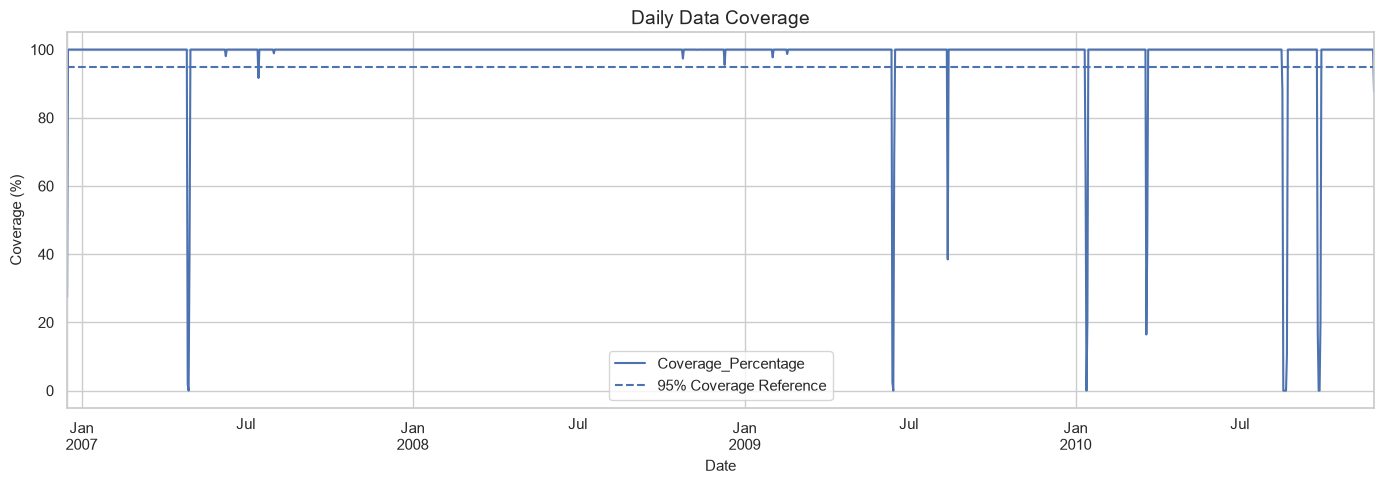

In [205]:
# Cell 75: Check Daily Data Coverage

daily_record_count = df_eda["Global_active_power"].resample("D").count()

daily_coverage = pd.DataFrame({
    "Available_Minute_Readings": daily_record_count,
    "Expected_Minute_Readings": 1440
})

daily_coverage["Coverage_Percentage"] = (
    daily_coverage["Available_Minute_Readings"] / 1440
) * 100

print("Days with Complete Readings:",
      (daily_coverage["Coverage_Percentage"] == 100).sum())

print("Days with Less Than 95% Coverage:",
      (daily_coverage["Coverage_Percentage"] < 95).sum())

print("Average Daily Coverage:",
      round(daily_coverage["Coverage_Percentage"].mean(), 2), "%")

display(daily_coverage.head())

daily_coverage.to_csv(
    os.path.join(EDA_OUTPUT_PATH, "daily_data_coverage.csv")
)

plt.figure(figsize=(14, 5))

daily_coverage["Coverage_Percentage"].plot()

plt.axhline(
    y=95,
    linestyle="--",
    label="95% Coverage Reference"
)

plt.title("Daily Data Coverage")
plt.xlabel("Date")
plt.ylabel("Coverage (%)")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(EDA_OUTPUT_PATH, "daily_data_coverage.png"),
    dpi=300
)

plt.show()


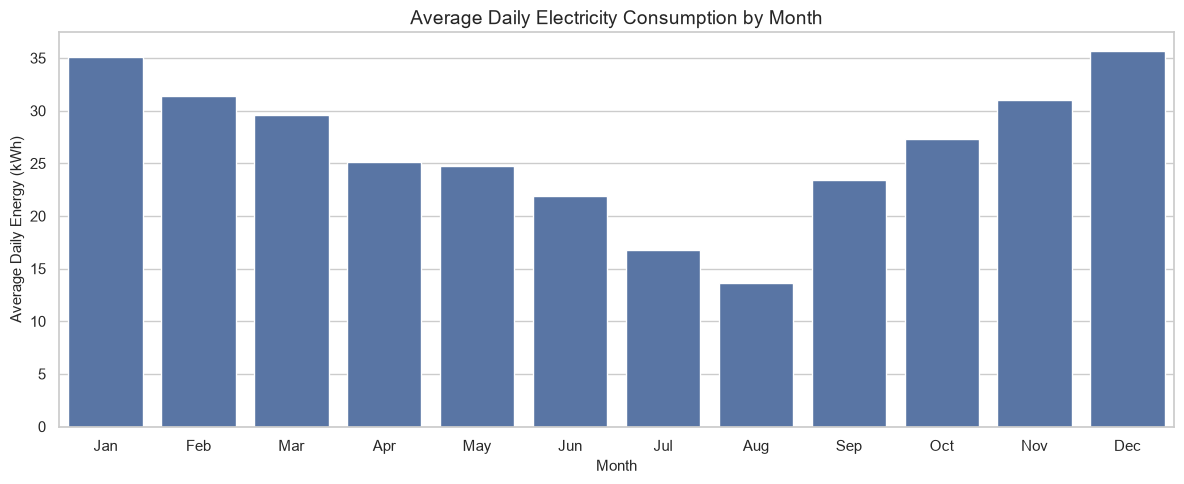

,Average_Daily_Energy_kWh
Jan,35.073165
Feb,31.373219
Mar,29.553126
Apr,25.157149
May,24.709695
Jun,21.870202
Jul,16.809345
Aug,13.632502
Sep,23.407168
Oct,27.300569


In [206]:
# Cell 76: Average Monthly Daily Energy Consumption

complete_days = daily_coverage[
    daily_coverage["Coverage_Percentage"] >= 95
].index

valid_daily_energy = daily_energy.loc[
    daily_energy.index.isin(complete_days)
]

average_monthly_energy = valid_daily_energy.groupby(
    valid_daily_energy.index.month
).mean()

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

average_monthly_energy.index = [
    month_names[int(m) - 1]
    for m in average_monthly_energy.index
]

plt.figure(figsize=(12, 5))

sns.barplot(
    x=average_monthly_energy.index,
    y=average_monthly_energy.values
)

plt.title("Average Daily Electricity Consumption by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Energy (kWh)")
plt.tight_layout()

plt.savefig(
    os.path.join(
        EDA_OUTPUT_PATH,
        "average_monthly_consumption.png"
    ),
    dpi=300
)

plt.show()

display(
    average_monthly_energy.to_frame(
        "Average_Daily_Energy_kWh"
    )
)


In [207]:
# Cell 77: Import Feature Engineering Libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

FEATURE_OUTPUT_PATH = "../evaluation/feature_engineering"
os.makedirs(FEATURE_OUTPUT_PATH, exist_ok=True)

print("Feature Engineering Libraries Imported Successfully!")


Feature Engineering Libraries Imported Successfully!


In [208]:
# Cell 78: Verify and Prepare the Source Dataset

assert isinstance(df_eda.index, pd.DatetimeIndex), \
    "Dataset index must be DateTime."

df_eda = df_eda.sort_index()

assert df_eda.index.is_monotonic_increasing
assert not df_eda.index.duplicated().any()

source_power = pd.to_numeric(
    df_eda["Global_active_power"],
    errors="coerce"
).dropna()

print("Source Dataset Verified!")
print("Start:", source_power.index.min())
print("End:", source_power.index.max())
print("Minute-Level Records:", len(source_power))


Source Dataset Verified!
Start: 2006-12-16 17:24:00
End: 2010-11-26 21:02:00
Minute-Level Records: 2049436


In [209]:
# Cell 79: Aggregate Minute-Level Power into Hourly Energy

# Global_active_power is measured in kilowatts (kW).
# Energy (kWh) = Average Power (kW) x Time (hours).
#
# Since each reading represents one minute:
# Average hourly power is equivalent to hourly energy in kWh
# when the hour contains sufficient valid readings.

# Step 1: Calculate average power for each hour.
hourly_average_power = (
    source_power.resample("h").mean()
)

# Step 2: Count valid minute readings in each hour.
hourly_reading_count = (
    source_power.resample("h").count()
)

# Step 3: Require at least 54 valid readings out of 60 (90% coverage).
MIN_HOURLY_READINGS = 54

hourly_energy_raw = hourly_average_power.where(
    hourly_reading_count >= MIN_HOURLY_READINGS
)

# Step 4: Create a continuous hourly datetime index.
full_hour_index = pd.date_range(
    start=source_power.index.min().floor("h"),
    end=source_power.index.max().floor("h"),
    freq="h"
)

# Step 5: Create the hourly forecasting dataset.
hourly_data = pd.DataFrame(index=full_hour_index)

hourly_data.index.name = "DateTime"

# Store hourly energy consumption.
hourly_data["Energy_kWh"] = (
    hourly_energy_raw.reindex(full_hour_index)
)

# Store the number of available minute readings.
hourly_data["Available_Readings"] = (
    hourly_reading_count
    .reindex(full_hour_index)
    .fillna(0)
    .astype(int)
)

# Step 6: Calculate hourly data coverage percentage.
hourly_data["Coverage_Percentage"] = (
    hourly_data["Available_Readings"] / 60
) * 100

# Step 7: Display hourly dataset information.
print("=" * 60)
print("HOURLY ENERGY DATASET")
print("=" * 60)

print("Total Hourly Time Slots:", len(hourly_data))

print(
    "Valid Hourly Records:",
    hourly_data["Energy_kWh"].notna().sum()
)

print(
    "Incomplete Hourly Records:",
    hourly_data["Energy_kWh"].isna().sum()
)

print(
    "Average Hourly Energy:",
    round(hourly_data["Energy_kWh"].mean(), 4),
    "kWh"
)

print(
    "Maximum Hourly Energy:",
    round(hourly_data["Energy_kWh"].max(), 4),
    "kWh"
)

print(
    "Minimum Hourly Energy:",
    round(hourly_data["Energy_kWh"].min(), 4),
    "kWh"
)

print("\nHourly Dataset Preview:")
display(hourly_data.head(10))

# Step 8: Validate hourly dataset.
assert isinstance(hourly_data.index, pd.DatetimeIndex)

assert hourly_data.index.is_monotonic_increasing

assert not hourly_data.index.duplicated().any()

assert hourly_data["Energy_kWh"].notna().sum() > 0

assert (
    hourly_data.loc[
        hourly_data["Energy_kWh"].notna(),
        "Available_Readings"
    ] >= MIN_HOURLY_READINGS
).all()

print("\nHourly Energy Calculation Completed Successfully!")
print("Hourly Dataset Validation Passed!")


HOURLY ENERGY DATASET
Total Hourly Time Slots: 34589
Valid Hourly Records: 34146
Incomplete Hourly Records: 443
Average Hourly Energy: 1.0915 kWh
Maximum Hourly Energy: 6.5605 kWh
Minimum Hourly Energy: 0.124 kWh

Hourly Dataset Preview:


,Energy_kWh,Available_Readings,Coverage_Percentage
DateTime,,,
2006-12-16 17:00:00,NaN,36,60.0
2006-12-16 18:00:00,3.632200,60,100.0
2006-12-16 19:00:00,3.400233,60,100.0
2006-12-16 20:00:00,3.268567,60,100.0
2006-12-16 21:00:00,3.056467,60,100.0
2006-12-16 22:00:00,2.200133,60,100.0
2006-12-16 23:00:00,2.061600,60,100.0
2006-12-17 00:00:00,1.882467,60,100.0
2006-12-17 01:00:00,3.349400,60,100.0



Hourly Energy Calculation Completed Successfully!
Hourly Dataset Validation Passed!


In [210]:
# Cell 80: Extract Hour, Day, Weekday, Month and Year

feature_data = hourly_data.copy()

feature_data["Hour"] = feature_data.index.hour
feature_data["Day"] = feature_data.index.day
feature_data["DayOfWeek"] = feature_data.index.dayofweek
feature_data["Month"] = feature_data.index.month
feature_data["Year"] = feature_data.index.year

# ISO week number (1 to 53)
feature_data["WeekNumber"] = (
    feature_data.index.isocalendar().week.astype(int)
)

print("Datetime Features Extracted!")
display(
    feature_data[
        [
            "Energy_kWh",
            "Hour",
            "Day",
            "DayOfWeek",
            "Month",
            "Year",
            "WeekNumber"
        ]
    ].head()
)


Datetime Features Extracted!


,Energy_kWh,Hour,Day,DayOfWeek,Month,Year,WeekNumber
DateTime,,,,,,,
2006-12-16 17:00:00,NaN,17,16,5,12,2006,50
2006-12-16 18:00:00,3.632200,18,16,5,12,2006,50
2006-12-16 19:00:00,3.400233,19,16,5,12,2006,50
2006-12-16 20:00:00,3.268567,20,16,5,12,2006,50
2006-12-16 21:00:00,3.056467,21,16,5,12,2006,50


In [211]:
# Cell 81: Create Weekend Indicator

# Monday = 0, Sunday = 6
# Weekend = Saturday or Sunday

feature_data["Weekend_Indicator"] = (
    feature_data["DayOfWeek"] >= 5
).astype(int)

feature_data["DayName"] = (
    feature_data.index.day_name()
)

feature_data["MonthName"] = (
    feature_data.index.month_name()
)

print("Weekend Indicator Created!")
print(feature_data[
    ["DayOfWeek", "DayName", "Weekend_Indicator"]
].head(10))


Weekend Indicator Created!
                     DayOfWeek   DayName  Weekend_Indicator
DateTime                                                   
2006-12-16 17:00:00          5  Saturday                  1
2006-12-16 18:00:00          5  Saturday                  1
2006-12-16 19:00:00          5  Saturday                  1
2006-12-16 20:00:00          5  Saturday                  1
2006-12-16 21:00:00          5  Saturday                  1
2006-12-16 22:00:00          5  Saturday                  1
2006-12-16 23:00:00          5  Saturday                  1
2006-12-17 00:00:00          6    Sunday                  1
2006-12-17 01:00:00          6    Sunday                  1
2006-12-17 02:00:00          6    Sunday                  1


In [212]:
# Cell 82: Previous Hour Consumption (Lag 1)

# Ensure the data is in chronological order.
feature_data = feature_data.sort_index()

# Confirm that the index contains every hourly timestamp.
assert isinstance(feature_data.index, pd.DatetimeIndex)
assert feature_data.index.is_monotonic_increasing
assert not feature_data.index.duplicated().any()

assert (
    feature_data.index.to_series().diff().dropna()
    == pd.Timedelta(hours=1)
).all(), "Hourly index contains missing timestamps!"

# Previous hour consumption.
# Missing historical readings remain NaN.
feature_data["Previous_Hour_Consumption"] = (
    feature_data["Energy_kWh"].shift(1)
)

print("Previous Hour Feature Created!")

display(
    feature_data[
        ["Energy_kWh", "Previous_Hour_Consumption"]
    ].head(10)
)


Previous Hour Feature Created!


,Energy_kWh,Previous_Hour_Consumption
DateTime,,
2006-12-16 17:00:00,NaN,NaN
2006-12-16 18:00:00,3.632200,NaN
2006-12-16 19:00:00,3.400233,3.632200
2006-12-16 20:00:00,3.268567,3.400233
2006-12-16 21:00:00,3.056467,3.268567
2006-12-16 22:00:00,2.200133,3.056467
2006-12-16 23:00:00,2.061600,2.200133
2006-12-17 00:00:00,1.882467,2.061600
2006-12-17 01:00:00,3.349400,1.882467


In [213]:
# Cell 83: Previous Day Consumption (Lag 24)

# Consumption at the same hour on the previous day.
feature_data["Previous_Day_Consumption"] = (
    feature_data["Energy_kWh"].shift(24)
)

print("Previous Day Feature Created!")

display(
    feature_data[
        ["Energy_kWh", "Previous_Day_Consumption"]
    ].iloc[20:30]
)


Previous Day Feature Created!


,Energy_kWh,Previous_Day_Consumption
DateTime,,
2006-12-17 13:00:00,1.660767,NaN
2006-12-17 14:00:00,2.092633,NaN
2006-12-17 15:00:00,2.985400,NaN
2006-12-17 16:00:00,3.326033,NaN
2006-12-17 17:00:00,3.406767,NaN
2006-12-17 18:00:00,3.697100,3.632200
2006-12-17 19:00:00,2.908400,3.400233
2006-12-17 20:00:00,3.361500,3.268567
2006-12-17 21:00:00,3.040767,3.056467


In [214]:
# Cell 84: Previous Week Consumption (Lag 168)

# Consumption at the same hour seven days earlier.
feature_data["Previous_Week_Consumption"] = (
    feature_data["Energy_kWh"].shift(168)
)

print("Previous Week Feature Created!")

display(
    feature_data[
        ["Energy_kWh", "Previous_Week_Consumption"]
    ].iloc[165:175]
)


Previous Week Feature Created!


,Energy_kWh,Previous_Week_Consumption
DateTime,,
2006-12-23 14:00:00,3.757967,NaN
2006-12-23 15:00:00,4.049100,NaN
2006-12-23 16:00:00,4.349100,NaN
2006-12-23 17:00:00,5.452533,NaN
2006-12-23 18:00:00,3.879400,3.632200
2006-12-23 19:00:00,4.117833,3.400233
2006-12-23 20:00:00,4.181400,3.268567
2006-12-23 21:00:00,3.288433,3.056467
2006-12-23 22:00:00,4.327933,2.200133


In [215]:
# Cell 85: Create Rolling Average Consumption Features

# Shift first to exclude the current target value.
past_energy = feature_data["Energy_kWh"].shift(1)

# Average of the previous 24 consecutive hours.
feature_data["Rolling_Average_24H"] = (
    past_energy.rolling(
        window=24,
        min_periods=24
    ).mean()
)

# Average of the previous 168 consecutive hours.
feature_data["Rolling_Average_7D"] = (
    past_energy.rolling(
        window=168,
        min_periods=168
    ).mean()
)

print("Rolling Average Features Created!")

display(
    feature_data[
        [
            "Energy_kWh",
            "Rolling_Average_24H",
            "Rolling_Average_7D"
        ]
    ].iloc[165:175]
)


Rolling Average Features Created!


,Energy_kWh,Rolling_Average_24H,Rolling_Average_7D
DateTime,,,
2006-12-23 14:00:00,3.757967,2.588317,NaN
2006-12-23 15:00:00,4.049100,2.710917,NaN
2006-12-23 16:00:00,4.349100,2.819144,NaN
2006-12-23 17:00:00,5.452533,2.934890,NaN
2006-12-23 18:00:00,3.879400,3.099713,1.771207
2006-12-23 19:00:00,4.117833,3.149397,1.772679
2006-12-23 20:00:00,4.181400,3.156883,1.776950
2006-12-23 21:00:00,3.288433,3.183772,1.782384
2006-12-23 22:00:00,4.327933,3.131263,1.783764


In [252]:
# Cell 86: Calculate Previous Completed Day Average Consumption

# Calculate hourly readings per day
daily_complete_hours = (
    feature_data["Energy_kWh"]
    .resample("D")
    .count()
)

# Calculate daily energy totals
daily_hourly_total = (
    feature_data["Energy_kWh"]
    .resample("D")
    .sum(min_count=24)
)

# Keep only complete days
daily_hourly_total = daily_hourly_total.where(
    daily_complete_hours == 24
)

# Calculate average hourly energy for complete days
daily_average_energy = daily_hourly_total / 24

# Carry forward the most recent completed day's average,
# then shift to ensure only past information is used.
previous_day_average = (
    daily_average_energy.ffill().shift(1)
)

# Map to hourly records
feature_data["Daily_Average_Consumption"] = (
    previous_day_average
    .reindex(feature_data.index.normalize())
    .to_numpy()
)

print("Previous Completed Day Average Feature Created!")

print(
    "Missing Values:",
    feature_data["Daily_Average_Consumption"].isna().sum()
)

display(
    feature_data[
        ["Energy_kWh", "Daily_Average_Consumption"]
    ].head(30)
)

Previous Completed Day Average Feature Created!
Missing Values: 31


,Energy_kWh,Daily_Average_Consumption
DateTime,,
2006-12-16 17:00:00,NaN,NaN
2006-12-16 18:00:00,3.632200,NaN
2006-12-16 19:00:00,3.400233,NaN
2006-12-16 20:00:00,3.268567,NaN
2006-12-16 21:00:00,3.056467,NaN
2006-12-16 22:00:00,2.200133,NaN
2006-12-16 23:00:00,2.061600,NaN
2006-12-17 00:00:00,1.882467,NaN
2006-12-17 01:00:00,3.349400,NaN


In [217]:
# Cell 87: Calculate Previous Completed Month Average Consumption

import pandas as pd
import numpy as np

# Step 1: Check input data
if "feature_data" not in globals():
    raise NameError(
        "feature_data is missing. Run Cell 80 first."
    )

if "Energy_kWh" not in feature_data.columns:
    raise ValueError("Energy_kWh column is missing!")

# Step 2: Sort data chronologically
feature_data = feature_data.sort_index()

# Step 3: Calculate valid hourly readings per day
daily_hourly_count = (
    feature_data["Energy_kWh"]
    .resample("D")
    .count()
)

# Step 4: Calculate daily energy totals
daily_hourly_total = (
    feature_data["Energy_kWh"]
    .resample("D")
    .sum(min_count=24)
)

# Step 5: Keep only complete days (24 valid hours)
daily_hourly_total = daily_hourly_total.where(
    daily_hourly_count == 24
)

# Step 6: Create daily energy DataFrame
daily_energy_frame = daily_hourly_total.to_frame(
    "Daily_Energy_kWh"
)

daily_energy_frame["MonthPeriod"] = (
    daily_energy_frame.index.to_period("M")
)

# Step 7: Calculate average daily energy per month
monthly_average_daily_energy = (
    daily_energy_frame
    .groupby("MonthPeriod")["Daily_Energy_kWh"]
    .mean()
)

# Step 8: Use previous month's average only
previous_month_average = (
    monthly_average_daily_energy.shift(1)
)

# Step 9: Map previous month's average to hourly records
feature_data["Monthly_Average_Consumption"] = (
    previous_month_average
    .reindex(feature_data.index.to_period("M"))
    .to_numpy()
)

# Step 10: Display validation results
print("=" * 60)
print("MONTHLY FEATURE ENGINEERING")
print("=" * 60)

print("Total Records:", len(feature_data))
print(
    "Complete Days:",
    int((daily_hourly_count == 24).sum())
)
print(
    "Missing Monthly Feature Values:",
    feature_data["Monthly_Average_Consumption"].isna().sum()
)

display(
    feature_data[
        ["Energy_kWh", "Monthly_Average_Consumption"]
    ].head(30)
)

print("\nMonthly Feature Created Successfully!")

MONTHLY FEATURE ENGINEERING
Total Records: 34589
Complete Days: 1411
Missing Monthly Feature Values: 367


,Energy_kWh,Monthly_Average_Consumption
DateTime,,
2006-12-16 17:00:00,NaN,NaN
2006-12-16 18:00:00,3.632200,NaN
2006-12-16 19:00:00,3.400233,NaN
2006-12-16 20:00:00,3.268567,NaN
2006-12-16 21:00:00,3.056467,NaN
2006-12-16 22:00:00,2.200133,NaN
2006-12-16 23:00:00,2.061600,NaN
2006-12-17 00:00:00,1.882467,NaN
2006-12-17 01:00:00,3.349400,NaN



Monthly Feature Created Successfully!


In [218]:
# Cell 88: Validate All Engineered Features

engineered_features = [
    "Hour",
    "Day",
    "DayOfWeek",
    "Month",
    "Year",
    "WeekNumber",
    "Weekend_Indicator",
    "Previous_Hour_Consumption",
    "Previous_Day_Consumption",
    "Previous_Week_Consumption",
    "Rolling_Average_24H",
    "Rolling_Average_7D",
    "Daily_Average_Consumption",
    "Monthly_Average_Consumption"
]

print("=" * 65)
print("FEATURE ENGINEERING VALIDATION")
print("=" * 65)

print("Total Engineered Features:", len(engineered_features))

# Check feature existence.
missing_columns = [
    col for col in engineered_features
    if col not in feature_data.columns
]

assert not missing_columns, (
    f"Missing features: {missing_columns}"
)

# Display missing values.
print("\nMissing Values:")
display(
    feature_data[engineered_features].isnull().sum()
)

# Validate datetime features.
assert feature_data["Hour"].between(0, 23).all()
assert feature_data["Day"].between(1, 31).all()
assert feature_data["DayOfWeek"].between(0, 6).all()
assert feature_data["Month"].between(1, 12).all()
assert feature_data["WeekNumber"].between(1, 53).all()

assert feature_data["Weekend_Indicator"].isin([0, 1]).all()

# Validate chronological order.
assert feature_data.index.is_monotonic_increasing
assert not feature_data.index.duplicated().any()

# Check numeric values wherever they are not missing.
for col in engineered_features:
    values = feature_data[col].dropna().to_numpy(dtype=float)
    assert np.isfinite(values).all(), (
        f"Invalid numerical values in {col}"
    )

print("\nDatetime Feature Validation Passed!")
print("Numerical Feature Validation Passed!")

FEATURE ENGINEERING VALIDATION
Total Engineered Features: 14

Missing Values:


Hour                              0
Day                               0
DayOfWeek                         0
Month                             0
Year                              0
WeekNumber                        0
Weekend_Indicator                 0
Previous_Hour_Consumption       443
Previous_Day_Consumption        466
Previous_Week_Consumption       610
Rolling_Average_24H             788
Rolling_Average_7D             2948
Daily_Average_Consumption       727
Monthly_Average_Consumption     367
dtype: int64


Datetime Feature Validation Passed!
Numerical Feature Validation Passed!


In [219]:
# Cell 89: Check Lag and Rolling Features for Data Leakage

energy = feature_data["Energy_kWh"]

# Find a position with 169 consecutive valid hourly readings.
valid_history = (
    energy.rolling(
        window=169,
        min_periods=169
    ).count()
)

valid_positions = np.flatnonzero(
    valid_history.to_numpy() == 169
)

assert len(valid_positions) > 0, (
    "No continuous 169-hour section found. "
    "Cannot perform leakage validation."
)

sample_position = int(valid_positions[0])
sample_time = feature_data.index[sample_position]

print("Sample Timestamp:", sample_time)

# Expected lag values.
expected_lag_1 = energy.iloc[sample_position - 1]
expected_lag_24 = energy.iloc[sample_position - 24]
expected_lag_168 = energy.iloc[sample_position - 168]

# Actual lag values.
actual_lag_1 = feature_data[
    "Previous_Hour_Consumption"
].iloc[sample_position]

actual_lag_24 = feature_data[
    "Previous_Day_Consumption"
].iloc[sample_position]

actual_lag_168 = feature_data[
    "Previous_Week_Consumption"
].iloc[sample_position]

# Validate lag features.
assert np.isclose(actual_lag_1, expected_lag_1)
assert np.isclose(actual_lag_24, expected_lag_24)
assert np.isclose(actual_lag_168, expected_lag_168)

# Expected rolling averages using only past values.
expected_24h = energy.iloc[
    sample_position - 24:sample_position
].mean()

expected_7d = energy.iloc[
    sample_position - 168:sample_position
].mean()

actual_24h = feature_data[
    "Rolling_Average_24H"
].iloc[sample_position]

actual_7d = feature_data[
    "Rolling_Average_7D"
].iloc[sample_position]

# Validate rolling features.
assert np.isclose(actual_24h, expected_24h)
assert np.isclose(actual_7d, expected_7d)

# Display results.
print("\nLag Validation:")
print("Previous Hour:", actual_lag_1)
print("Previous Day:", actual_lag_24)
print("Previous Week:", actual_lag_168)

print("\nRolling Average Validation:")
print("Expected 24H:", expected_24h)
print("Actual 24H:", actual_24h)

print("Expected 7D:", expected_7d)
print("Actual 7D:", actual_7d)

print("\nAll Lag Feature Checks Passed!")
print("All Rolling Feature Checks Passed!")
print("No Current-Target Leakage Detected!")

Sample Timestamp: 2006-12-23 18:00:00

Lag Validation:
Previous Hour: 5.452533333333333
Previous Day: 2.686966666666667
Previous Week: 3.6321999999999997

Rolling Average Validation:
Expected 24H: 3.0997125000000003
Actual 24H: 3.0997125000000003
Expected 7D: 1.771207142857143
Actual 7D: 1.7712071428571428

All Lag Feature Checks Passed!
All Rolling Feature Checks Passed!
No Current-Target Leakage Detected!


In [220]:
# Cell 90: Create Final Machine Learning Feature Dataset

# Keep only rows with a valid target and all required feature values.
# Early rows naturally contain NaN values because lag history is unavailable.
# Missing hourly observations also cause affected lag/rolling features to be NaN.

feature_columns = engineered_features

feature_engineered_df = feature_data[
    ["Energy_kWh"] + feature_columns
].copy()

feature_engineered_df = feature_engineered_df.dropna(
    subset=["Energy_kWh"] + feature_columns
)

feature_engineered_df = feature_engineered_df.sort_index()

print("Final Feature Dataset Created!")
print("Final Dataset Shape:", feature_engineered_df.shape)
print("Target Column: Energy_kWh")
print("Number of Features:", len(feature_columns))

display(feature_engineered_df.head())


Final Feature Dataset Created!
Final Dataset Shape: (31428, 15)
Target Column: Energy_kWh
Number of Features: 14


,Energy_kWh,Hour,Day,DayOfWeek,Month,Year,WeekNumber,Weekend_Indicator,Previous_Hour_Consumption,Previous_Day_Consumption,Previous_Week_Consumption,Rolling_Average_24H,Rolling_Average_7D,Daily_Average_Consumption,Monthly_Average_Consumption
DateTime,,,,,,,,,,,,,,,
2007-01-01 00:00:00,2.550633,0,1,0,1,2007,1,0,3.104433,0.676233,0.999567,2.426525,1.959222,2.426525,45.130033
2007-01-01 01:00:00,2.523400,1,1,0,1,2007,1,0,2.550633,0.716167,1.206767,2.504625,1.968454,2.426525,45.130033
2007-01-01 02:00:00,2.582333,2,1,0,1,2007,1,0,2.523400,0.721933,0.438000,2.579926,1.976291,2.426525,45.130033
2007-01-01 03:00:00,2.541667,3,1,0,1,2007,1,0,2.582333,0.778567,0.589967,2.657443,1.989055,2.426525,45.130033
2007-01-01 04:00:00,2.475733,4,1,0,1,2007,1,0,2.541667,1.277767,0.578667,2.730906,2.000672,2.426525,45.130033


In [221]:
# Cell 91: Final Feature Dataset Quality Check

print("Missing Values:",
      feature_engineered_df.isnull().sum().sum())

print("Duplicate Timestamps:",
      feature_engineered_df.index.duplicated().sum())

print("Chronological Order:",
      feature_engineered_df.index.is_monotonic_increasing)

print("Start Timestamp:",
      feature_engineered_df.index.min())

print("End Timestamp:",
      feature_engineered_df.index.max())

assert feature_engineered_df.isnull().sum().sum() == 0
assert not feature_engineered_df.index.duplicated().any()
assert feature_engineered_df.index.is_monotonic_increasing

print("\nFinal Feature Dataset Validation Passed!")


Missing Values: 0
Duplicate Timestamps: 0
Chronological Order: True
Start Timestamp: 2007-01-01 00:00:00
End Timestamp: 2010-11-26 20:00:00

Final Feature Dataset Validation Passed!


In [222]:
# Cell 92: Save Feature Engineered Dataset

FEATURE_DATASET_PATH = (
    "../dataset/feature_engineered_hourly.csv"
)

feature_engineered_df.to_csv(
    FEATURE_DATASET_PATH,
    index_label="DateTime"
)

print("Feature Engineered Dataset Saved Successfully!")
print("Saved Location:", FEATURE_DATASET_PATH)
print("Rows:", len(feature_engineered_df))
print("Columns:", len(feature_engineered_df.columns))


Feature Engineered Dataset Saved Successfully!
Saved Location: ../dataset/feature_engineered_hourly.csv
Rows: 31428
Columns: 15


In [223]:
# Cell 93: Save Feature Description Report

feature_descriptions = {
    "Energy_kWh": "Hourly electricity energy consumption (target)",
    "Hour": "Hour of the day (0-23)",
    "Day": "Day of the month (1-31)",
    "DayOfWeek": "Day of the week (Monday=0, Sunday=6)",
    "Month": "Month of the year (1-12)",
    "Year": "Calendar year",
    "WeekNumber": "ISO week number (1-53)",
    "Weekend_Indicator": "1 for Saturday/Sunday, otherwise 0",
    "Previous_Hour_Consumption": "Energy consumption one hour earlier",
    "Previous_Day_Consumption": "Energy consumption at the same hour one day earlier",
    "Previous_Week_Consumption": "Energy consumption at the same hour seven days earlier",
    "Rolling_Average_24H": "Mean energy of the previous 24 hourly observations",
    "Rolling_Average_7D": "Mean energy of the previous 168 hourly observations",
    "Daily_Average_Consumption": "Average hourly energy of the previous complete day",
    "Monthly_Average_Consumption": "Mean daily energy across complete 24-hour days in the previous calendar month"
}

feature_report = pd.DataFrame({
    "Feature": list(feature_descriptions.keys()),
    "Description": list(feature_descriptions.values()),
    "Data_Type": [
        str(feature_engineered_df[col].dtype)
        for col in feature_descriptions.keys()
    ]
})

feature_report.to_csv(
    os.path.join(
        FEATURE_OUTPUT_PATH,
        "feature_description_report.csv"
    ),
    index=False
)

display(feature_report)

print("Feature Description Report Saved!")


,Feature,Description,Data_Type
0,Energy_kWh,Hourly electricity energy consumption (target),float64
1,Hour,Hour of the day (0-23),int32
2,Day,Day of the month (1-31),int32
3,DayOfWeek,"Day of the week (Monday=0, Sunday=6)",int32
4,Month,Month of the year (1-12),int32
5,Year,Calendar year,int32
6,WeekNumber,ISO week number (1-53),int64
7,Weekend_Indicator,"1 for Saturday/Sunday, otherwise 0",int64
8,Previous_Hour_Consumption,Energy consumption one hour earlier,float64
9,Previous_Day_Consumption,Energy consumption at the same hour one day ea...,float64


Feature Description Report Saved!


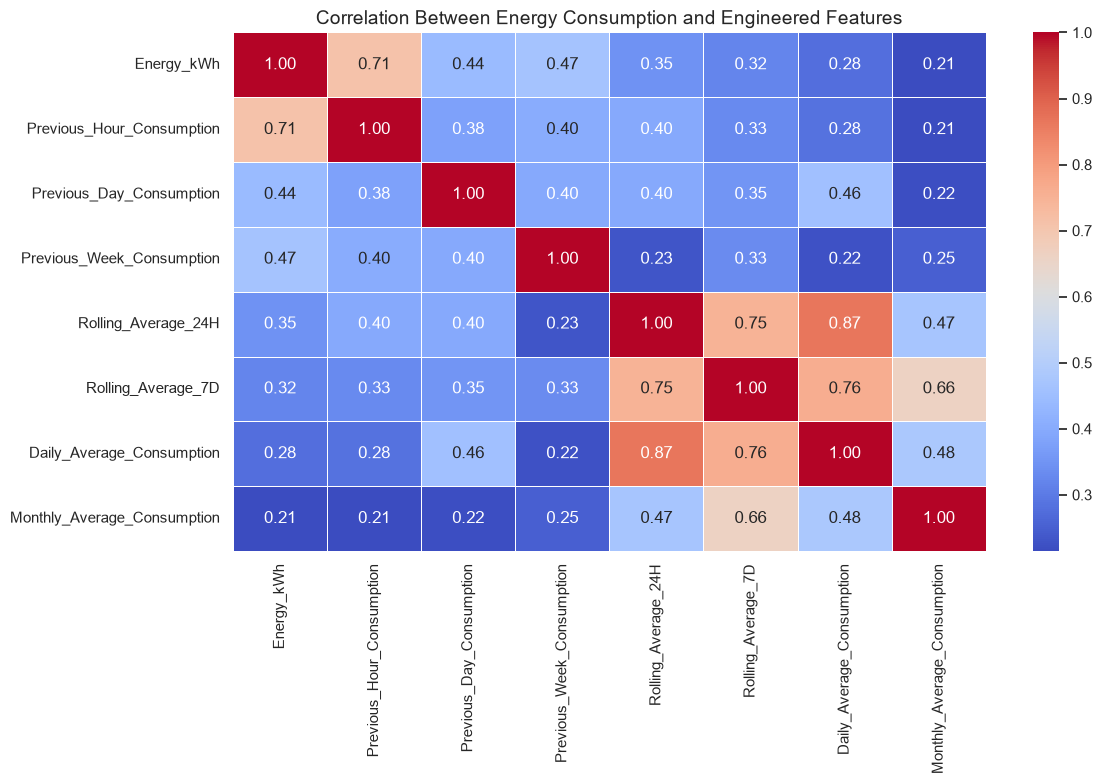

Feature Correlation Analysis Completed!


In [224]:
# Cell 94: Feature Correlation Analysis

correlation_columns = [
    "Energy_kWh",
    "Previous_Hour_Consumption",
    "Previous_Day_Consumption",
    "Previous_Week_Consumption",
    "Rolling_Average_24H",
    "Rolling_Average_7D",
    "Daily_Average_Consumption",
    "Monthly_Average_Consumption"
]

feature_correlation = feature_engineered_df[
    correlation_columns
].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    feature_correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Energy Consumption and Engineered Features")
plt.tight_layout()

plt.savefig(
    os.path.join(
        FEATURE_OUTPUT_PATH,
        "feature_correlation_heatmap.png"
    ),
    dpi=300
)

plt.show()

feature_correlation.to_csv(
    os.path.join(
        FEATURE_OUTPUT_PATH,
        "feature_correlation_matrix.csv"
    )
)

print("Feature Correlation Analysis Completed!")


In [225]:
# Cell 95: Final Feature Engineering Summary

print("=" * 65)
print("SMART ENERGY CONSUMPTION FORECASTING")
print("FEATURE ENGINEERING SUMMARY")
print("=" * 65)

print("Original Minute-Level Records:", len(source_power))
print("Total Hourly Time Slots:", len(hourly_data))
print("Valid Hourly Targets:",
      hourly_data["Energy_kWh"].notna().sum())

print("\nTotal Engineered Features:", len(engineered_features))
print("Final ML Dataset Shape:", feature_engineered_df.shape)

print("\nTarget Variable: Energy_kWh")

print("\nEngineered Features:")
for col in engineered_features:
    print("-", col)

print("\nMissing Values:",
      feature_engineered_df.isnull().sum().sum())

print("Duplicate Timestamps:",
      feature_engineered_df.index.duplicated().sum())

print("\nSaved Dataset:", FEATURE_DATASET_PATH)
print("Reports Folder:", FEATURE_OUTPUT_PATH)

print("\nFEATURE ENGINEERING COMPLETED!")


SMART ENERGY CONSUMPTION FORECASTING
FEATURE ENGINEERING SUMMARY
Original Minute-Level Records: 2049436
Total Hourly Time Slots: 34589
Valid Hourly Targets: 34146

Total Engineered Features: 14
Final ML Dataset Shape: (31428, 15)

Target Variable: Energy_kWh

Engineered Features:
- Hour
- Day
- DayOfWeek
- Month
- Year
- WeekNumber
- Weekend_Indicator
- Previous_Hour_Consumption
- Previous_Day_Consumption
- Previous_Week_Consumption
- Rolling_Average_24H
- Rolling_Average_7D
- Daily_Average_Consumption
- Monthly_Average_Consumption

Missing Values: 0
Duplicate Timestamps: 0

Saved Dataset: ../dataset/feature_engineered_hourly.csv
Reports Folder: ../evaluation/feature_engineering

FEATURE ENGINEERING COMPLETED!


In [226]:
# Cell 96: Import Required Libraries

import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Libraries Imported Successfully!")


Libraries Imported Successfully!


In [227]:
# Cell 97: Load Feature-Engineered Dataset

from pathlib import Path
import pandas as pd

DATASET_PATH = Path("../dataset/feature_engineered_hourly.csv")

MODEL_OUTPUT_PATH = Path("../models")
EVALUATION_OUTPUT_PATH = Path("../evaluation/model_development")
VISUALIZATION_PATH = Path("../visualizations/model_development")

MODEL_OUTPUT_PATH.mkdir(parents=True, exist_ok=True)
EVALUATION_OUTPUT_PATH.mkdir(parents=True, exist_ok=True)
VISUALIZATION_PATH.mkdir(parents=True, exist_ok=True)

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_PATH.resolve()}"
    )

model_data = pd.read_csv(
    DATASET_PATH,
    parse_dates=["DateTime"],
    index_col="DateTime"
)

model_data = model_data.sort_index()

print("Feature-Engineered Dataset Loaded!")
print("Dataset Shape:", model_data.shape)
print("Date Range:", model_data.index.min(), "to", model_data.index.max())

display(model_data.head())

Feature-Engineered Dataset Loaded!
Dataset Shape: (31428, 15)
Date Range: 2007-01-01 00:00:00 to 2010-11-26 20:00:00


,Energy_kWh,Hour,Day,DayOfWeek,Month,Year,WeekNumber,Weekend_Indicator,Previous_Hour_Consumption,Previous_Day_Consumption,Previous_Week_Consumption,Rolling_Average_24H,Rolling_Average_7D,Daily_Average_Consumption,Monthly_Average_Consumption
DateTime,,,,,,,,,,,,,,,
2007-01-01 00:00:00,2.550633,0,1,0,1,2007,1,0,3.104433,0.676233,0.999567,2.426525,1.959222,2.426525,45.130033
2007-01-01 01:00:00,2.523400,1,1,0,1,2007,1,0,2.550633,0.716167,1.206767,2.504625,1.968454,2.426525,45.130033
2007-01-01 02:00:00,2.582333,2,1,0,1,2007,1,0,2.523400,0.721933,0.438000,2.579926,1.976291,2.426525,45.130033
2007-01-01 03:00:00,2.541667,3,1,0,1,2007,1,0,2.582333,0.778567,0.589967,2.657443,1.989055,2.426525,45.130033
2007-01-01 04:00:00,2.475733,4,1,0,1,2007,1,0,2.541667,1.277767,0.578667,2.730906,2.000672,2.426525,45.130033


In [228]:
# Cell 98: Select Input Features and Target

import numpy as np

target_column = "Energy_kWh"

feature_columns = [
    "Hour",
    "Day",
    "DayOfWeek",
    "Month",
    "Year",
    "WeekNumber",
    "Weekend_Indicator",
    "Previous_Hour_Consumption",
    "Previous_Day_Consumption",
    "Previous_Week_Consumption",
    "Rolling_Average_24H",
    "Rolling_Average_7D",
    "Daily_Average_Consumption",
    "Monthly_Average_Consumption"
]

# Check required columns
required_columns = feature_columns + [target_column]

missing_columns = [
    col for col in required_columns
    if col not in model_data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Remove rows with missing required values
model_data = model_data.dropna(
    subset=required_columns
).copy()

# Separate input features and target
X = model_data[feature_columns].astype(float)
y = model_data[target_column].astype(float)

# Display dataset information
print("=" * 60)
print("FEATURE SELECTION AND TARGET PREPARATION")
print("=" * 60)

print("Input Features:", len(feature_columns))
print("Target Variable:", target_column)
print("Total Records:", len(model_data))

print("Input Feature Shape:", X.shape)
print("Target Shape:", y.shape)

# Validate numerical values
assert np.isfinite(X.to_numpy()).all(), "Invalid values found in X!"
assert np.isfinite(y.to_numpy()).all(), "Invalid values found in y!"

# Validate indexes
assert X.index.equals(y.index)

print("\nFeature and Target Validation Passed!")

FEATURE SELECTION AND TARGET PREPARATION
Input Features: 14
Target Variable: Energy_kWh
Total Records: 31428
Input Feature Shape: (31428, 14)
Target Shape: (31428,)

Feature and Target Validation Passed!


In [229]:
# Cell 99: Chronological Train-Test Split

split_position = int(len(X) * 0.80)

X_train = X.iloc[:split_position].copy()
X_test = X.iloc[split_position:].copy()

y_train = y.iloc[:split_position].copy()
y_test = y.iloc[split_position:].copy()

print("=" * 60)
print("CHRONOLOGICAL TRAIN-TEST SPLIT")
print("=" * 60)

print("Total Records:", len(X))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Period:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTesting Period:")
print(X_test.index.min(), "to", X_test.index.max())

print("\nTraining Percentage:",
      round(len(X_train) / len(X) * 100, 2), "%")

print("Testing Percentage:",
      round(len(X_test) / len(X) * 100, 2), "%")

assert X_train.index.max() < X_test.index.min()
assert y_train.index.equals(X_train.index)
assert y_test.index.equals(X_test.index)

print("\nChronological Split Validation Passed!")

CHRONOLOGICAL TRAIN-TEST SPLIT
Total Records: 31428
Training Records: 25142
Testing Records: 6286

Training Period:
2007-01-01 00:00:00 to 2010-02-06 19:00:00

Testing Period:
2010-02-06 20:00:00 to 2010-11-26 20:00:00

Training Percentage: 80.0 %
Testing Percentage: 20.0 %

Chronological Split Validation Passed!


In [230]:
# Cell 100: Initialize Machine Learning Models

models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        loss="squared_error",
        random_state=RANDOM_STATE
    )
}

# Add XGBoost only if it is installed.
try:
    from xgboost import XGBRegressor

    models["XGBoost"] = XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    print("XGBoost Available!")

except ImportError:
    print("XGBoost Not Installed. Skipping Optional Model.")

print("\nModels Initialized:")
for model_name in models:
    print("-", model_name)

print("\nTotal Models:", len(models))


XGBoost Available!

Models Initialized:
- Linear Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- XGBoost

Total Models: 5


In [231]:
# Cell 101: Train All Machine Learning Models

trained_models = {}

for model_name, model in models.items():

    print("\n" + "=" * 60)
    print("Training:", model_name)
    print("=" * 60)

    model.fit(X_train, y_train)

    trained_models[model_name] = model

    print(model_name, "Training Completed!")

print("\nAll Available Models Trained Successfully!")



Training: Linear Regression
Linear Regression Training Completed!

Training: Decision Tree
Decision Tree Training Completed!

Training: Random Forest
Random Forest Training Completed!

Training: Gradient Boosting
Gradient Boosting Training Completed!

Training: XGBoost
XGBoost Training Completed!

All Available Models Trained Successfully!


In [232]:
# Cell 102: Generate Predictions on Unseen Test Data

predictions = {}

for model_name, model in trained_models.items():

    y_pred = model.predict(X_test)

    predictions[model_name] = y_pred

    print("\nModel:", model_name)
    print("Predictions Generated:", len(y_pred))

print("\nPrediction Generation Completed!")

# Create prediction dataframe.
prediction_df = pd.DataFrame(
    predictions,
    index=X_test.index
)

prediction_df["Actual_Energy_kWh"] = y_test

display(prediction_df.head(10))



Model: Linear Regression
Predictions Generated: 6286

Model: Decision Tree
Predictions Generated: 6286

Model: Random Forest
Predictions Generated: 6286

Model: Gradient Boosting
Predictions Generated: 6286

Model: XGBoost
Predictions Generated: 6286

Prediction Generation Completed!


,Linear Regression,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Actual_Energy_kWh
DateTime,,,,,,
2010-02-06 20:00:00,3.486333,3.050683,3.370487,3.338048,3.263639,2.558233
2010-02-06 21:00:00,2.586777,2.706623,2.465068,2.685504,2.597228,2.988300
2010-02-06 22:00:00,2.763269,2.245275,2.500618,2.423309,2.417935,2.849100
2010-02-06 23:00:00,2.334163,1.663195,2.127130,1.927617,2.191167,3.474900
2010-02-07 00:00:00,2.361425,2.454396,2.558505,2.568293,2.421479,1.058700
2010-02-07 01:00:00,0.868067,0.448943,0.578865,0.703365,0.698130,1.010433
2010-02-07 02:00:00,0.864913,0.448943,0.439940,0.616767,0.593169,0.976967
2010-02-07 03:00:00,0.849188,0.448943,0.464449,0.572999,0.581684,0.471600
2010-02-07 04:00:00,0.553235,0.561870,0.503105,0.482310,0.470404,0.320033


In [233]:
# Cell 103: Evaluate Model Performance Using Correct Formulas

evaluation_results = []

actual_values = np.asarray(y_test, dtype=float)

assert len(actual_values) > 0, "Test set is empty."
assert np.isfinite(actual_values).all(), "Invalid actual values found."

for model_name, y_pred in predictions.items():

    predicted_values = np.asarray(y_pred, dtype=float)

    assert len(actual_values) == len(predicted_values)
    assert np.isfinite(predicted_values).all(), (
        f"Invalid predictions found for {model_name}"
    )

    errors = actual_values - predicted_values
    absolute_errors = np.abs(errors)

    # Mean Absolute Error
    mae = np.mean(absolute_errors)

    # Mean Squared Error
    mse = np.mean(errors ** 2)

    # Root Mean Squared Error
    rmse = np.sqrt(mse)

    # R-squared
    ss_res = np.sum(errors ** 2)
    ss_tot = np.sum((actual_values - np.mean(actual_values)) ** 2)
    r2 = 1 - (ss_res / ss_tot) if ss_tot > 0 else np.nan

    # MAPE: exclude exact zero actual values.
    nonzero_actual = actual_values != 0
    mape = (
        np.mean(
            absolute_errors[nonzero_actual] /
            np.abs(actual_values[nonzero_actual])
        ) * 100
        if np.any(nonzero_actual)
        else np.nan
    )

    # WAPE: total absolute error divided by total absolute actual energy.
    actual_total = np.sum(np.abs(actual_values))
    wape = (
        np.sum(absolute_errors) / actual_total * 100
        if actual_total > 0
        else np.nan
    )

    # sMAPE: define zero/zero pairs as zero contribution.
    smape_denominator = (
        np.abs(actual_values) + np.abs(predicted_values)
    )
    smape_terms = np.divide(
        2 * absolute_errors,
        smape_denominator,
        out=np.zeros_like(absolute_errors, dtype=float),
        where=smape_denominator != 0
    )
    smape = np.mean(smape_terms) * 100

    evaluation_results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2_Score": r2,
        "MAPE_Percentage": mape,
        "WAPE_Percentage": wape,
        "sMAPE_Percentage": smape
    })

results_df = pd.DataFrame(evaluation_results)

# Select the model with the lowest RMSE on the chronological test set.
results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("=" * 100)
print("MACHINE LEARNING MODEL PERFORMANCE")
print("=" * 100)
display(results_df.round(4))

best_model_name = results_df.iloc[0]["Model"]

print("\nBest Performing Model (lowest test RMSE):", best_model_name)
print("MAPE excludes exact-zero actual values; near-zero values can still inflate it.")
print("WAPE and sMAPE are included as complementary percentage metrics.")


MACHINE LEARNING MODEL PERFORMANCE


,Model,MAE,MSE,RMSE,R2_Score,MAPE_Percentage,WAPE_Percentage,sMAPE_Percentage
0,XGBoost,0.3346,0.2302,0.4798,0.5802,44.7271,33.1781,34.7786
1,Gradient Boosting,0.3422,0.2377,0.4875,0.5665,45.4402,33.9297,35.4921
2,Random Forest,0.3437,0.2431,0.4930,0.5567,46.8464,34.0856,35.1097
3,Linear Regression,0.3716,0.2696,0.5192,0.5084,50.5508,36.8522,39.0211
4,Decision Tree,0.3795,0.3150,0.5613,0.4255,47.8346,37.6333,37.0508



Best Performing Model (lowest test RMSE): XGBoost
MAPE excludes exact-zero actual values; near-zero values can still inflate it.
WAPE and sMAPE are included as complementary percentage metrics.


In [234]:
# Cell 104: Identify the Best Performing Model

from sklearn.base import clone

# Select the model with the lowest RMSE on the held-out chronological test set.
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

best_rmse = results_df.loc[0, "RMSE"]
best_mae = results_df.loc[0, "MAE"]
best_r2 = results_df.loc[0, "R2_Score"]

print("=" * 60)
print("BEST PERFORMING MODEL")
print("=" * 60)

print("Best Model:", best_model_name)
print("Test MAE:", round(best_mae, 4), "kWh")
print("Test RMSE:", round(best_rmse, 4), "kWh")
print("Test R2 Score:", round(best_r2, 4))

# Refit a separate copy on all available historical rows for deployment forecasting.
# This does not change the previously computed held-out test metrics/predictions.
forecast_model = clone(best_model)
forecast_model.fit(X, y)

print("\nBest model selected using held-out test RMSE.")
print("Separate forecasting model refitted on all available historical data.")


BEST PERFORMING MODEL
Best Model: XGBoost
Test MAE: 0.3346 kWh
Test RMSE: 0.4798 kWh
Test R2 Score: 0.5802

Best model selected using held-out test RMSE.
Separate forecasting model refitted on all available historical data.


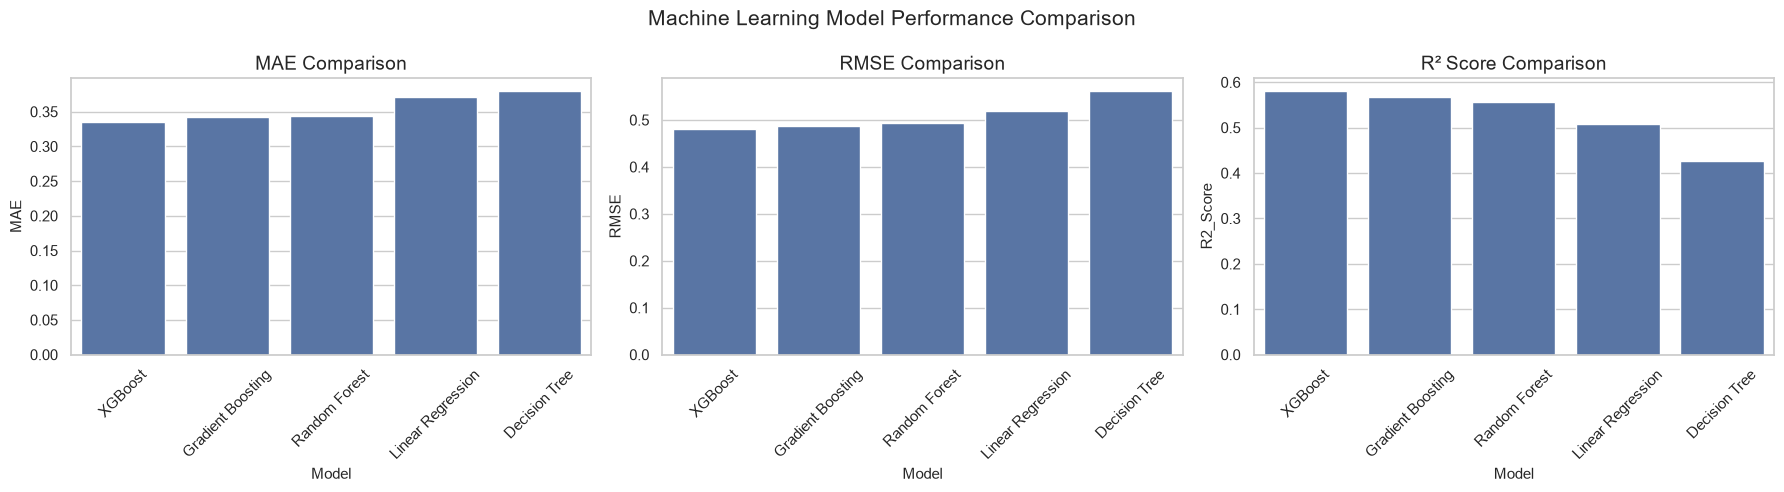

Model Comparison Graph Saved!


In [235]:
# Cell 105: Compare Model Performance Graphically

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# MAE comparison
sns.barplot(
    data=results_df,
    x="Model",
    y="MAE",
    ax=axes[0]
)
axes[0].set_title("MAE Comparison")
axes[0].tick_params(axis="x", rotation=45)

# RMSE comparison
sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE",
    ax=axes[1]
)
axes[1].set_title("RMSE Comparison")
axes[1].tick_params(axis="x", rotation=45)

# R2 comparison
sns.barplot(
    data=results_df,
    x="Model",
    y="R2_Score",
    ax=axes[2]
)
axes[2].set_title("R² Score Comparison")
axes[2].tick_params(axis="x", rotation=45)

plt.suptitle(
    "Machine Learning Model Performance Comparison",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    VISUALIZATION_PATH / "model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model Comparison Graph Saved!")


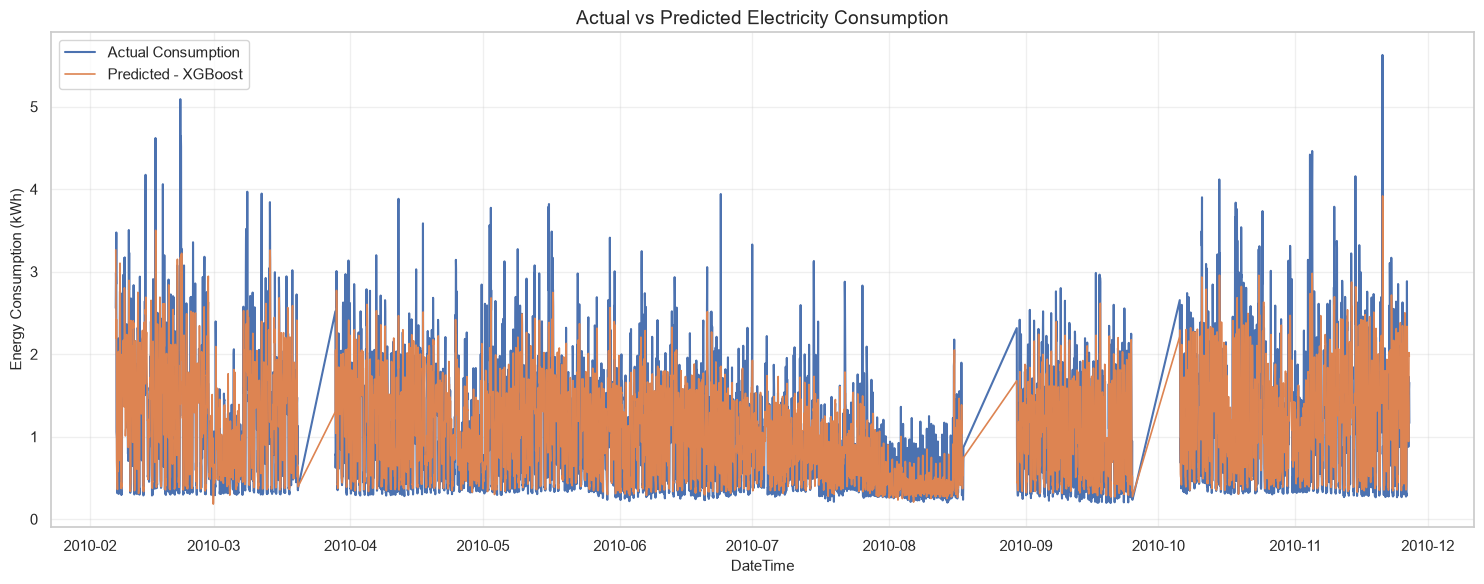

In [236]:
# Cell 106: Actual vs Predicted Consumption

plt.figure(figsize=(15, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual Consumption",
    linewidth=1.5
)

plt.plot(
    y_test.index,
    predictions[best_model_name],
    label=f"Predicted - {best_model_name}",
    linewidth=1.2
)

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("DateTime")
plt.ylabel("Energy Consumption (kWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    VISUALIZATION_PATH / "actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [237]:
# Cell 107: Save Trained Models and Evaluation Results

# Save all trained models.
for model_name, model in trained_models.items():

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
    )

    model_path = MODEL_OUTPUT_PATH / f"{safe_name}_model.pkl"

    joblib.dump(model, model_path)

    print("Saved:", model_path)

# Save model comparison table.
results_df.to_csv(
    EVALUATION_OUTPUT_PATH / "model_comparison_results.csv",
    index=False
)

# Save predictions.
prediction_df.to_csv(
    EVALUATION_OUTPUT_PATH / "test_predictions.csv",
    index_label="DateTime"
)

# Save best model information.
best_model_info = pd.DataFrame([{
    "Best_Model": best_model_name,
    "MAE": best_mae,
    "RMSE": best_rmse,
    "R2_Score": best_r2
}])

best_model_info.to_csv(
    EVALUATION_OUTPUT_PATH / "best_model_summary.csv",
    index=False
)

print("\nAll Models and Evaluation Results Saved Successfully!")


Saved: ..\models\linear_regression_model.pkl
Saved: ..\models\decision_tree_model.pkl
Saved: ..\models\random_forest_model.pkl
Saved: ..\models\gradient_boosting_model.pkl
Saved: ..\models\xgboost_model.pkl

All Models and Evaluation Results Saved Successfully!


In [238]:
# Cell 108: Final Machine Learning Summary

print("=" * 70)
print("SMART ENERGY CONSUMPTION FORECASTING")
print("MACHINE LEARNING MODEL DEVELOPMENT SUMMARY")
print("=" * 70)

print("\nTotal Dataset Records:", len(model_data))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nInput Features:", len(feature_columns))
print("Target Variable:", target_column)

print("\nModels Trained:")
for model_name in trained_models:
    print("-", model_name)

print("\nModel Performance:")
display(results_df.round(4))

print("\nBest Performing Model:", best_model_name)

print("\nBest MAE:", round(best_mae, 4), "kWh")
print("Best RMSE:", round(best_rmse, 4), "kWh")
print("Best R2 Score:", round(best_r2, 4))

print("\nSaved Model Directory:", MODEL_OUTPUT_PATH)
print("Evaluation Directory:", EVALUATION_OUTPUT_PATH)
print("Visualization Directory:", VISUALIZATION_PATH)

print("\nMACHINE LEARNING MODEL DEVELOPMENT COMPLETED!")


SMART ENERGY CONSUMPTION FORECASTING
MACHINE LEARNING MODEL DEVELOPMENT SUMMARY

Total Dataset Records: 31428
Training Records: 25142
Testing Records: 6286

Input Features: 14
Target Variable: Energy_kWh

Models Trained:
- Linear Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- XGBoost

Model Performance:


,Model,MAE,MSE,RMSE,R2_Score,MAPE_Percentage,WAPE_Percentage,sMAPE_Percentage
0,XGBoost,0.3346,0.2302,0.4798,0.5802,44.7271,33.1781,34.7786
1,Gradient Boosting,0.3422,0.2377,0.4875,0.5665,45.4402,33.9297,35.4921
2,Random Forest,0.3437,0.2431,0.4930,0.5567,46.8464,34.0856,35.1097
3,Linear Regression,0.3716,0.2696,0.5192,0.5084,50.5508,36.8522,39.0211
4,Decision Tree,0.3795,0.3150,0.5613,0.4255,47.8346,37.6333,37.0508



Best Performing Model: XGBoost

Best MAE: 0.3346 kWh
Best RMSE: 0.4798 kWh
Best R2 Score: 0.5802

Saved Model Directory: ..\models
Evaluation Directory: ..\evaluation\model_development
Visualization Directory: ..\visualizations\model_development

MACHINE LEARNING MODEL DEVELOPMENT COMPLETED!


In [239]:
# Cell 109A: Diagnose Missing Hourly Records

historical_energy = model_data["Energy_kWh"].copy().astype(float)
historical_energy = historical_energy.sort_index()

expected_index = pd.date_range(
    start=historical_energy.index.min(),
    end=historical_energy.index.max(),
    freq="h"
)

missing_timestamps = expected_index.difference(
    historical_energy.index
)

print("Existing Hourly Records:", len(historical_energy))
print("Expected Hourly Records:", len(expected_index))
print("Missing Hourly Timestamps:", len(missing_timestamps))

print("\nFirst 20 Missing Timestamps:")
print(missing_timestamps[:20])

print("\nExisting Missing Energy Values:",
      historical_energy.isna().sum())

Existing Hourly Records: 31428
Expected Hourly Records: 34221
Missing Hourly Timestamps: 2793

First 20 Missing Timestamps:
DatetimeIndex(['2007-04-28 00:00:00', '2007-04-28 01:00:00',
               '2007-04-28 02:00:00', '2007-04-28 03:00:00',
               '2007-04-28 04:00:00', '2007-04-28 05:00:00',
               '2007-04-28 06:00:00', '2007-04-28 07:00:00',
               '2007-04-28 08:00:00', '2007-04-28 09:00:00',
               '2007-04-28 10:00:00', '2007-04-28 11:00:00',
               '2007-04-28 12:00:00', '2007-04-28 13:00:00',
               '2007-04-28 14:00:00', '2007-04-28 15:00:00',
               '2007-04-28 16:00:00', '2007-04-28 17:00:00',
               '2007-04-28 18:00:00', '2007-04-28 19:00:00'],
              dtype='datetime64[us]', freq=None)

Existing Missing Energy Values: 0


In [240]:
# Cell 109B: Inspect Latest Historical Data Gaps

historical_energy = (
    model_data["Energy_kWh"]
    .copy()
    .astype(float)
    .sort_index()
)

expected_index = pd.date_range(
    start=historical_energy.index.min(),
    end=historical_energy.index.max(),
    freq="h"
)

missing_timestamps = expected_index.difference(
    historical_energy.index
)

print("Total Missing Timestamps:", len(missing_timestamps))

print("\nLast 30 Historical Records:")
print(historical_energy.tail(30))

print("\nLast 30 Missing Timestamps:")
print(missing_timestamps[-30:])

# Check the latest continuous hourly segment.
latest_time = historical_energy.index.max()

last_168_hours = pd.date_range(
    end=latest_time,
    periods=168,
    freq="h"
)

available_last_168 = historical_energy.reindex(last_168_hours)

print("\nLatest 168 Hours:")
print("Available readings:", available_last_168.notna().sum())
print("Missing readings:", available_last_168.isna().sum())

print("\nLatest 24 Hours:")
print("Available readings:",
      available_last_168.tail(24).notna().sum())

Total Missing Timestamps: 2793

Last 30 Historical Records:
DateTime
2010-11-25 15:00:00    0.333000
2010-11-25 16:00:00    0.541800
2010-11-25 17:00:00    1.480100
2010-11-25 18:00:00    2.211600
2010-11-25 19:00:00    2.330467
2010-11-25 20:00:00    1.647833
2010-11-25 21:00:00    1.342933
2010-11-25 22:00:00    1.247567
2010-11-25 23:00:00    0.957000
2010-11-26 00:00:00    0.294300
2010-11-26 01:00:00    0.281000
2010-11-26 02:00:00    0.273433
2010-11-26 03:00:00    0.298367
2010-11-26 04:00:00    0.314033
2010-11-26 05:00:00    0.282567
2010-11-26 06:00:00    1.008767
2010-11-26 07:00:00    2.883933
2010-11-26 08:00:00    1.999300
2010-11-26 09:00:00    1.849967
2010-11-26 10:00:00    1.352767
2010-11-26 11:00:00    1.338900
2010-11-26 12:00:00    1.490200
2010-11-26 13:00:00    1.612933
2010-11-26 14:00:00    1.407767
2010-11-26 15:00:00    0.876433
2010-11-26 16:00:00    1.067933
2010-11-26 17:00:00    1.725900
2010-11-26 18:00:00    1.573467
2010-11-26 19:00:00    1.659333
201

In [241]:
# Cell 109: Prepare Latest Continuous Historical Data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import joblib

# Load the original feature-engineered target.
all_historical_energy = (
    model_data["Energy_kWh"]
    .copy()
    .astype(float)
    .sort_index()
)

# Check duplicate timestamps.
if all_historical_energy.index.has_duplicates:
    raise ValueError("Duplicate timestamps found.")

# Select the latest 168 continuous hours.
latest_timestamp = all_historical_energy.index.max()

latest_168_index = pd.date_range(
    end=latest_timestamp,
    periods=168,
    freq="h"
)

historical_energy = all_historical_energy.reindex(
    latest_168_index
)

# Verify that all 168 hours are available.
if historical_energy.isna().any():
    raise ValueError(
        "Latest 168 hours contain missing values. "
        "A continuous historical period is required."
    )

if not np.isfinite(historical_energy).all():
    raise ValueError("Invalid historical energy values found.")

if (historical_energy < 0).any():
    raise ValueError("Negative historical energy values found.")

# Store the latest known monthly average feature.
latest_monthly_average = float(
    model_data["Monthly_Average_Consumption"].iloc[-1]
)

# Create output folders.
FORECAST_OUTPUT_PATH = Path("../evaluation/future_forecasting")
FORECAST_VISUALIZATION_PATH = Path("../visualizations/future_forecasting")

FORECAST_OUTPUT_PATH.mkdir(parents=True, exist_ok=True)
FORECAST_VISUALIZATION_PATH.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("HISTORICAL FORECAST DATA PREPARATION")
print("=" * 65)

print("Historical Start:", historical_energy.index.min())
print("Historical End:", historical_energy.index.max())
print("Available Hourly Readings:", len(historical_energy))
print("Missing Values:", historical_energy.isna().sum())
print("Latest Known Monthly Average:", latest_monthly_average)

print("\nLatest 168 Hours Verified Successfully!")

HISTORICAL FORECAST DATA PREPARATION
Historical Start: 2010-11-19 21:00:00
Historical End: 2010-11-26 20:00:00
Available Hourly Readings: 168
Missing Values: 0
Latest Known Monthly Average: 27.922256989247312

Latest 168 Hours Verified Successfully!


In [242]:
# Cell 110: Recursive Future Energy Forecasting Function

def get_previous_day_average(series, forecast_time):

    previous_day = forecast_time.normalize() - pd.Timedelta(days=1)

    day_index = pd.date_range(
        start=previous_day,
        periods=24,
        freq="h"
    )

    day_values = series.reindex(day_index)

    if day_values.isna().any():
        raise ValueError(
            f"Previous-day hourly readings unavailable: {previous_day}"
        )

    return day_values.mean()


def forecast_future_energy(
    model,
    history,
    feature_columns,
    hours=168
):

    forecast_history = history.copy()

    future_predictions = []

    # Keep the latest known monthly feature as a fixed reference.
    monthly_average_reference = latest_monthly_average

    for step in range(hours):

        next_time = (
            forecast_history.index[-1] + pd.Timedelta(hours=1)
        )

        past_168_hours = forecast_history.tail(168)

        if len(past_168_hours) != 168 or past_168_hours.isna().any():
            raise ValueError("168 continuous readings are required.")

        features = {
            "Hour": next_time.hour,
            "Day": next_time.day,
            "DayOfWeek": next_time.dayofweek,
            "Month": next_time.month,
            "Year": next_time.year,
            "WeekNumber": int(next_time.isocalendar().week),
            "Weekend_Indicator": int(next_time.dayofweek >= 5),

            "Previous_Hour_Consumption":
                forecast_history.iloc[-1],

            "Previous_Day_Consumption":
                forecast_history.iloc[-24],

            "Previous_Week_Consumption":
                forecast_history.iloc[-168],

            "Rolling_Average_24H":
                forecast_history.tail(24).mean(),

            "Rolling_Average_7D":
                forecast_history.tail(168).mean(),

            "Daily_Average_Consumption":
                get_previous_day_average(
                    forecast_history,
                    next_time
                ),

            "Monthly_Average_Consumption":
                monthly_average_reference
        }

        input_data = pd.DataFrame(
            [[features[col] for col in feature_columns]],
            columns=feature_columns,
            index=[next_time]
        )

        predicted_energy = float(
            model.predict(input_data)[0]
        )

        predicted_energy = max(0.0, predicted_energy)

        future_predictions.append({
            "DateTime": next_time,
            "Predicted_Energy_kWh": predicted_energy
        })

        # Add the predicted value to history.
        forecast_history.loc[next_time] = predicted_energy

    forecast_df = pd.DataFrame(future_predictions)

    return forecast_df.set_index("DateTime")


print("Recursive Forecasting Function Ready!")

Recursive Forecasting Function Ready!


In [243]:
# Cell 111: Generate Future Electricity Consumption Predictions

# Forecast the next 7 days (168 hours).
FORECAST_HOURS = 168

future_forecast = forecast_future_energy(
    model=forecast_model,
    history=historical_energy,
    feature_columns=feature_columns,
    hours=FORECAST_HOURS
)

# Next-hour prediction.
next_hour_prediction = future_forecast[
    "Predicted_Energy_kWh"
].iloc[0]

# Next-day prediction = sum of 24 hourly energy predictions.
next_day_forecast = future_forecast.iloc[:24]

next_day_energy = next_day_forecast[
    "Predicted_Energy_kWh"
].sum()

# Total predicted energy for 7 days.
seven_day_energy = future_forecast[
    "Predicted_Energy_kWh"
].sum()

print("=" * 70)
print("FUTURE ELECTRICITY CONSUMPTION PREDICTION")
print("=" * 70)

print("\nBest Model:", best_model_name)

print("\nNext Hour Prediction:")
print(round(next_hour_prediction, 4), "kWh")
print("Forecast Time:", future_forecast.index[0])

print("\nNext 24 Hours Prediction:")
print(round(next_day_energy, 4), "kWh")

print("\nNext 7 Days Prediction:")
print(round(seven_day_energy, 4), "kWh")

print("\nHourly Forecast Preview:")
display(future_forecast.head(10))

print("\nFuture Energy Prediction Completed!")

FUTURE ELECTRICITY CONSUMPTION PREDICTION

Best Model: XGBoost

Next Hour Prediction:
1.3703 kWh
Forecast Time: 2010-11-26 21:00:00

Next 24 Hours Prediction:
35.3906 kWh

Next 7 Days Prediction:
228.3429 kWh

Hourly Forecast Preview:


,Predicted_Energy_kWh
DateTime,
2010-11-26 21:00:00,1.370267
2010-11-26 22:00:00,1.123492
2010-11-26 23:00:00,0.550255
2010-11-27 00:00:00,0.511122
2010-11-27 01:00:00,0.500855
2010-11-27 02:00:00,0.492671
2010-11-27 03:00:00,0.488399
2010-11-27 04:00:00,0.506442
2010-11-27 05:00:00,0.540151



Future Energy Prediction Completed!


In [244]:
# Cell 112: Calculate Daily Future Energy Demand

daily_future_energy = (
    future_forecast["Predicted_Energy_kWh"]
    .resample("D")
    .sum()
)

daily_forecast_df = daily_future_energy.to_frame(
    name="Predicted_Daily_Energy_kWh"
)

print("=" * 65)
print("NEXT 7 DAYS - DAILY ENERGY DEMAND")
print("=" * 65)

display(daily_forecast_df.round(4))

# Save daily forecast.
daily_forecast_df.to_csv(
    FORECAST_OUTPUT_PATH / "daily_energy_forecast.csv"
)

print("Daily Forecast Saved Successfully!")

NEXT 7 DAYS - DAILY ENERGY DEMAND


,Predicted_Daily_Energy_kWh
DateTime,
2010-11-26,3.0440
2010-11-27,37.5093
2010-11-28,33.8803
2010-11-29,32.1475
2010-11-30,31.9087
2010-12-01,32.1379
2010-12-02,30.0018
2010-12-03,27.7134


Daily Forecast Saved Successfully!


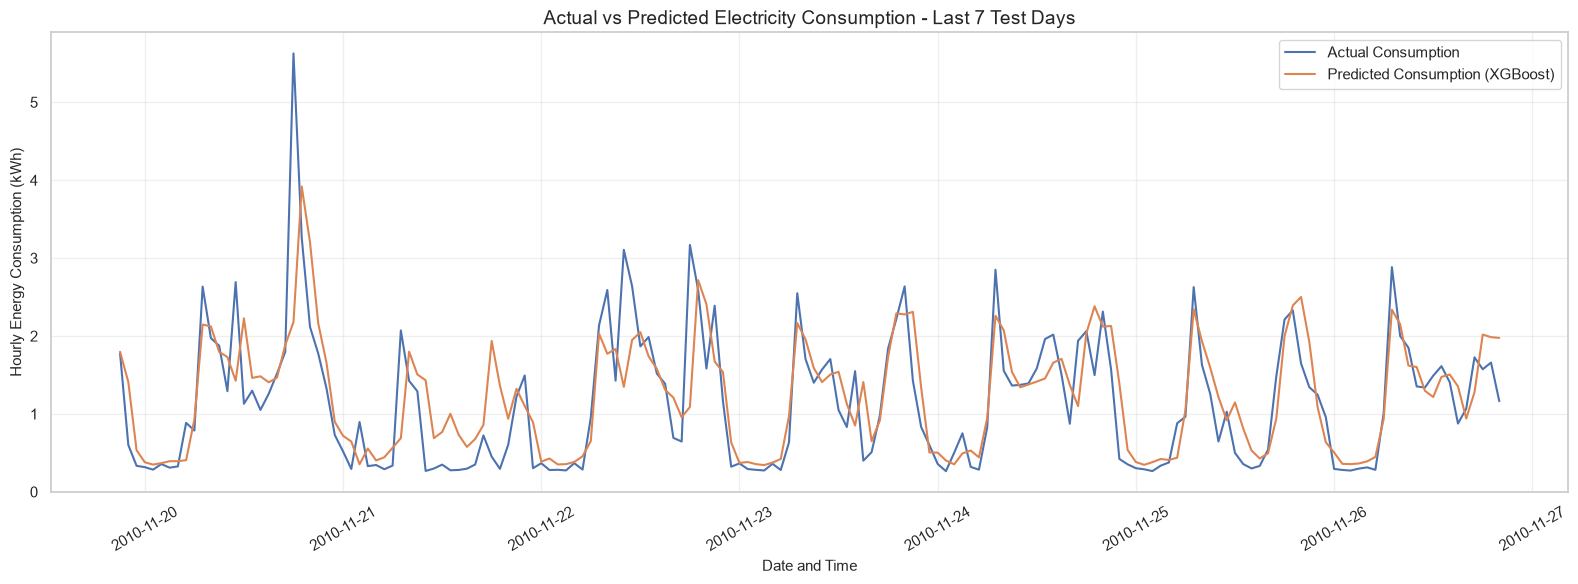

Actual vs Predicted Visualization Created!


In [245]:
# Cell 113: Actual vs Predicted Energy Consumption

comparison_df = pd.DataFrame({
    "Actual_Energy_kWh": y_test,
    "Predicted_Energy_kWh": predictions[best_model_name]
}, index=y_test.index)

comparison_df = comparison_df.tail(24 * 7)

plt.figure(figsize=(16, 6))

plt.plot(
    comparison_df.index,
    comparison_df["Actual_Energy_kWh"],
    label="Actual Consumption",
    linewidth=1.5
)

plt.plot(
    comparison_df.index,
    comparison_df["Predicted_Energy_kWh"],
    label=f"Predicted Consumption ({best_model_name})",
    linewidth=1.5
)

plt.title("Actual vs Predicted Electricity Consumption - Last 7 Test Days")
plt.xlabel("Date and Time")
plt.ylabel("Hourly Energy Consumption (kWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    FORECAST_VISUALIZATION_PATH / "actual_vs_predicted_energy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Actual vs Predicted Visualization Created!")

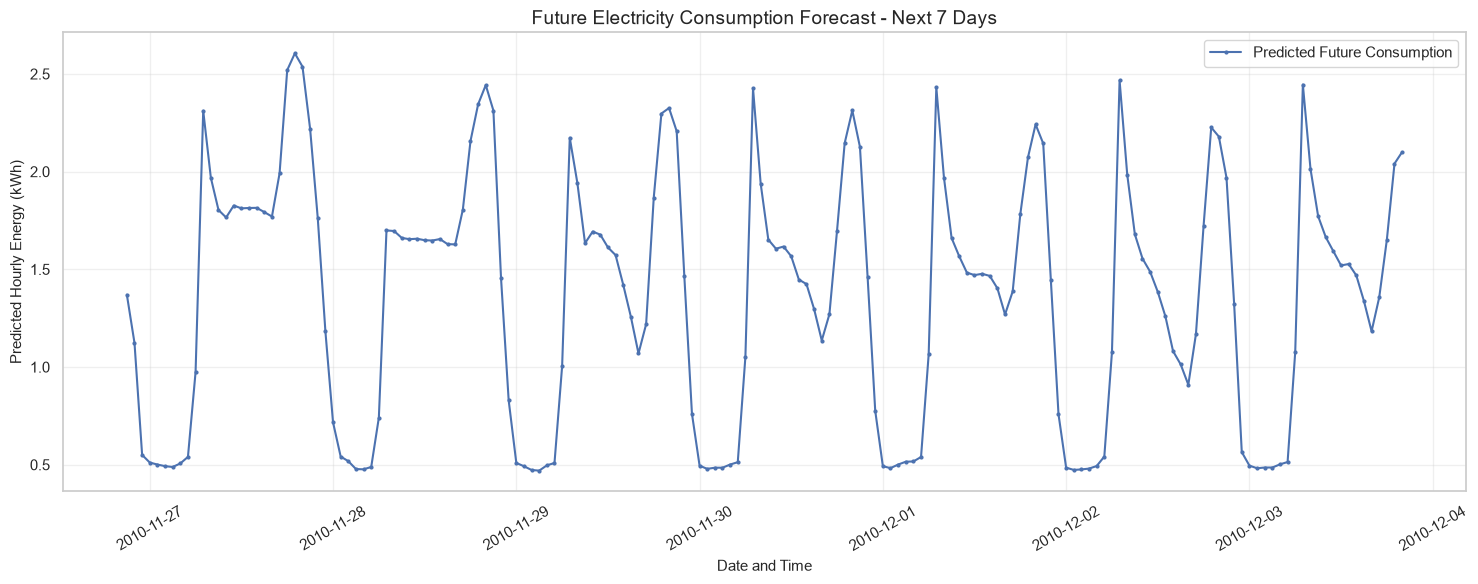

Future Energy Forecast Visualization Created!


In [246]:
# Cell 114: Future Electricity Consumption Forecast Graph

plt.figure(figsize=(15, 6))

plt.plot(
    future_forecast.index,
    future_forecast["Predicted_Energy_kWh"],
    label="Predicted Future Consumption",
    linewidth=1.5,
    marker="o",
    markersize=2
)

plt.title("Future Electricity Consumption Forecast - Next 7 Days")
plt.xlabel("Date and Time")
plt.ylabel("Predicted Hourly Energy (kWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    FORECAST_VISUALIZATION_PATH / "future_energy_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Future Energy Forecast Visualization Created!")

In [247]:
# Cell 115: Identify Future Peak-Demand Periods

# Historical 90th percentile threshold.
peak_threshold = historical_energy.quantile(0.90)

# Identify predicted hours above the threshold.
future_forecast["Demand_Status"] = np.where(
    future_forecast["Predicted_Energy_kWh"] >= peak_threshold,
    "High Demand",
    "Normal Demand"
)

# Extract predicted high-demand hours.
peak_demand_hours = future_forecast[
    future_forecast["Demand_Status"] == "High Demand"
].copy()

# Find the 10 highest predicted consumption hours.
top_peak_hours = future_forecast.nlargest(
    10,
    "Predicted_Energy_kWh"
)

print("=" * 70)
print("FUTURE PEAK-DEMAND ANALYSIS")
print("=" * 70)

print(
    "\nHistorical 90th Percentile Threshold:",
    round(peak_threshold, 4),
    "kWh"
)

print(
    "\nNumber of Predicted High-Demand Hours:",
    len(peak_demand_hours)
)

print("\nTop 10 Predicted Peak-Demand Hours:")
display(top_peak_hours.round(4))

print("\nAll Predicted High-Demand Periods:")
display(peak_demand_hours.round(4))

# Save peak-demand results.
peak_demand_hours.to_csv(
    FORECAST_OUTPUT_PATH / "predicted_peak_demand_hours.csv"
)

top_peak_hours.to_csv(
    FORECAST_OUTPUT_PATH / "top_10_peak_demand_hours.csv"
)

print("\nPeak-Demand Analysis Completed!")

FUTURE PEAK-DEMAND ANALYSIS

Historical 90th Percentile Threshold: 2.2487 kWh

Number of Predicted High-Demand Hours: 14

Top 10 Predicted Peak-Demand Hours:


,Predicted_Energy_kWh,Demand_Status
DateTime,,
2010-11-27 19:00:00,2.6052,High Demand
2010-11-27 20:00:00,2.5373,High Demand
2010-11-27 18:00:00,2.5195,High Demand
2010-12-02 07:00:00,2.4667,High Demand
2010-12-03 07:00:00,2.4454,High Demand
2010-11-28 20:00:00,2.4429,High Demand
2010-12-01 07:00:00,2.4313,High Demand
2010-11-30 07:00:00,2.4255,High Demand
2010-11-28 19:00:00,2.3446,High Demand



All Predicted High-Demand Periods:


,Predicted_Energy_kWh,Demand_Status
DateTime,,
2010-11-27 07:00:00,2.3116,High Demand
2010-11-27 18:00:00,2.5195,High Demand
2010-11-27 19:00:00,2.6052,High Demand
2010-11-27 20:00:00,2.5373,High Demand
2010-11-28 19:00:00,2.3446,High Demand
2010-11-28 20:00:00,2.4429,High Demand
2010-11-28 21:00:00,2.3127,High Demand
2010-11-29 19:00:00,2.2972,High Demand
2010-11-29 20:00:00,2.3255,High Demand



Peak-Demand Analysis Completed!


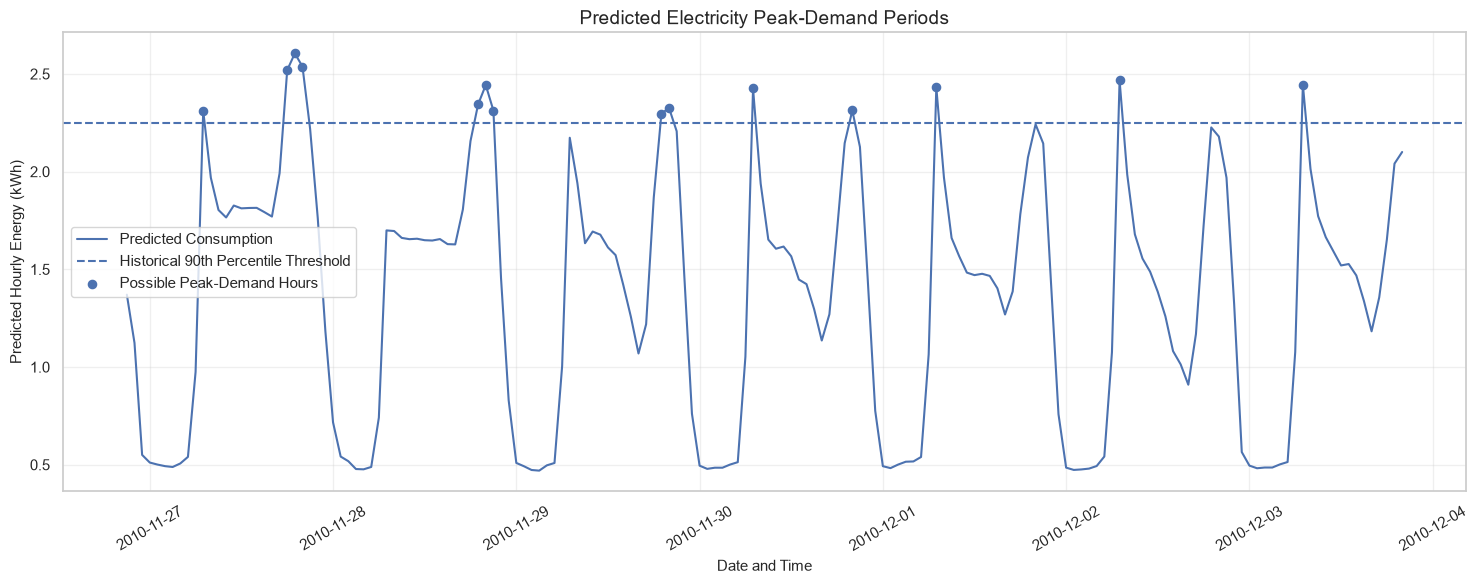

Peak-Demand Visualization Created!


In [248]:
# Cell 116: Visualize Predicted Peak-Demand Periods

plt.figure(figsize=(15, 6))

plt.plot(
    future_forecast.index,
    future_forecast["Predicted_Energy_kWh"],
    label="Predicted Consumption",
    linewidth=1.5
)

plt.axhline(
    y=peak_threshold,
    linestyle="--",
    label="Historical 90th Percentile Threshold"
)

plt.scatter(
    peak_demand_hours.index,
    peak_demand_hours["Predicted_Energy_kWh"],
    label="Possible Peak-Demand Hours",
    s=35
)

plt.title("Predicted Electricity Peak-Demand Periods")
plt.xlabel("Date and Time")
plt.ylabel("Predicted Hourly Energy (kWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    FORECAST_VISUALIZATION_PATH / "predicted_peak_demand.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Peak-Demand Visualization Created!")

In [249]:
# Cell 117: Save Future Forecasting Results

# Save hourly forecast.
future_forecast.to_csv(
    FORECAST_OUTPUT_PATH / "hourly_energy_forecast.csv",
    index_label="DateTime"
)

# Save actual vs predicted test comparison.
comparison_df.to_csv(
    FORECAST_OUTPUT_PATH / "actual_vs_predicted_comparison.csv",
    index_label="DateTime"
)

# Save forecasting summary.
forecast_summary = pd.DataFrame([{
    "Best_Model": best_model_name,
    "Next_Hour_Energy_kWh": next_hour_prediction,
    "Next_Day_Energy_kWh": next_day_energy,
    "Next_7_Days_Energy_kWh": seven_day_energy,
    "Historical_Peak_Threshold_kWh": peak_threshold,
    "Predicted_High_Demand_Hours": len(peak_demand_hours)
}])

forecast_summary.to_csv(
    FORECAST_OUTPUT_PATH / "forecast_summary.csv",
    index=False
)

print("=" * 65)
print("FUTURE FORECASTING RESULTS SAVED")
print("=" * 65)

print("Hourly Forecast:",
      FORECAST_OUTPUT_PATH / "hourly_energy_forecast.csv")

print("Daily Forecast:",
      FORECAST_OUTPUT_PATH / "daily_energy_forecast.csv")

print("Peak-Demand Results:",
      FORECAST_OUTPUT_PATH / "predicted_peak_demand_hours.csv")

print("Forecast Summary:",
      FORECAST_OUTPUT_PATH / "forecast_summary.csv")

print("\nAll Forecasting Outputs Saved Successfully!")

FUTURE FORECASTING RESULTS SAVED
Hourly Forecast: ..\evaluation\future_forecasting\hourly_energy_forecast.csv
Daily Forecast: ..\evaluation\future_forecasting\daily_energy_forecast.csv
Peak-Demand Results: ..\evaluation\future_forecasting\predicted_peak_demand_hours.csv
Forecast Summary: ..\evaluation\future_forecasting\forecast_summary.csv

All Forecasting Outputs Saved Successfully!


In [250]:
# Cell 118: Final Future Energy Forecasting Summary

print("=" * 75)
print("SMART ENERGY CONSUMPTION FORECASTING")
print("FUTURE ENERGY CONSUMPTION PREDICTION SUMMARY")
print("=" * 75)

print("\nSelected Best Model:", best_model_name)

print("\nForecasting Period:")
print(future_forecast.index.min(), "to", future_forecast.index.max())

print("\nNext-Hour Energy Prediction:",
      round(next_hour_prediction, 4), "kWh")

print("Next-Day Energy Prediction:",
      round(next_day_energy, 4), "kWh")

print("Next-7-Day Energy Prediction:",
      round(seven_day_energy, 4), "kWh")

print("\nHistorical Peak-Demand Threshold:",
      round(peak_threshold, 4), "kWh")

print("Predicted High-Demand Hours:",
      len(peak_demand_hours))

print("\nForecasted Daily Energy:")
display(daily_forecast_df.round(4))

print("\nTop Peak-Demand Hours:")
display(top_peak_hours.round(4))

print("\nForecast Output Folder:",
      FORECAST_OUTPUT_PATH.resolve())

print("\nForecast Visualization Folder:",
      FORECAST_VISUALIZATION_PATH.resolve())

print("\nFUTURE ENERGY CONSUMPTION FORECASTING COMPLETED!")

SMART ENERGY CONSUMPTION FORECASTING
FUTURE ENERGY CONSUMPTION PREDICTION SUMMARY

Selected Best Model: XGBoost

Forecasting Period:
2010-11-26 21:00:00 to 2010-12-03 20:00:00

Next-Hour Energy Prediction: 1.3703 kWh
Next-Day Energy Prediction: 35.3906 kWh
Next-7-Day Energy Prediction: 228.3429 kWh

Historical Peak-Demand Threshold: 2.2487 kWh
Predicted High-Demand Hours: 14

Forecasted Daily Energy:


,Predicted_Daily_Energy_kWh
DateTime,
2010-11-26,3.0440
2010-11-27,37.5093
2010-11-28,33.8803
2010-11-29,32.1475
2010-11-30,31.9087
2010-12-01,32.1379
2010-12-02,30.0018
2010-12-03,27.7134



Top Peak-Demand Hours:


,Predicted_Energy_kWh,Demand_Status
DateTime,,
2010-11-27 19:00:00,2.6052,High Demand
2010-11-27 20:00:00,2.5373,High Demand
2010-11-27 18:00:00,2.5195,High Demand
2010-12-02 07:00:00,2.4667,High Demand
2010-12-03 07:00:00,2.4454,High Demand
2010-11-28 20:00:00,2.4429,High Demand
2010-12-01 07:00:00,2.4313,High Demand
2010-11-30 07:00:00,2.4255,High Demand
2010-11-28 19:00:00,2.3446,High Demand



Forecast Output Folder: C:\Users\vyshu\OneDrive\Desktop\Smart-Energy-Forecasting\evaluation\future_forecasting

Forecast Visualization Folder: C:\Users\vyshu\OneDrive\Desktop\Smart-Energy-Forecasting\visualizations\future_forecasting

FUTURE ENERGY CONSUMPTION FORECASTING COMPLETED!


SMART ENERGY CONSUMPTION FORECASTING
TASK 8: INSIGHTS AND RECOMMENDATIONS

1. HOURLY CONSUMPTION INSIGHTS
Highest Consumption Hour: 20:00
Average Energy at Highest Hour: 1.8991 kWh
Lowest Consumption Hour: 4:00
Average Energy at Lowest Hour: 0.4438 kWh

2. WEEKDAY AND WEEKEND INSIGHTS
Average Weekday Consumption: 1.0354 kWh
Average Weekend Consumption: 1.2341 kWh
Highest Average Consumption Day: Saturday
Lowest Average Consumption Day: Thursday

3. MONTHLY AND SEASONAL INSIGHTS
Highest Average Daily Consumption Month: December
Lowest Average Daily Consumption Month: August
Highest Average Daily Consumption Season: Winter

Monthly Average Daily Energy:


,Average_Daily_Energy_kWh
January,35.0732
February,31.3732
March,29.5531
April,25.1571
May,24.7097
June,21.8702
July,16.8093
August,13.6325
September,23.4072
October,27.3006



Seasonal Average Daily Energy:


,Average_Daily_Energy_kWh
Season,
Autumn,27.2330
Spring,26.4817
Summer,17.4250
Winter,34.0429



4. FUTURE ENERGY DEMAND INSIGHTS
Forecast Model: XGBoost
Forecast Period: 2010-11-26 21:00:00 to 2010-12-03 20:00:00
Highest Forecast Demand Date: 2010-11-27
Highest Forecast Daily Energy: 37.5093 kWh
Predicted High-Demand Hours: 14

5. ENERGY-SAVING RECOMMENDATIONS


,Category,Recommendation
0,Households,"Monitor electricity use around 20:00, the high..."
1,Households,"Switch off unused lights and appliances, use e..."
2,Households,"Use washing machines, water heaters and other ..."
3,Businesses,Schedule flexible industrial and commercial lo...
4,Businesses,"Monitor equipment energy consumption, improve ..."
5,Electricity Providers,Use hourly and daily demand forecasts to plan ...
6,Electricity Providers,Monitor predicted peak-demand hours and prepar...
7,Electricity Providers,"Use historical weekly, monthly and seasonal pa..."


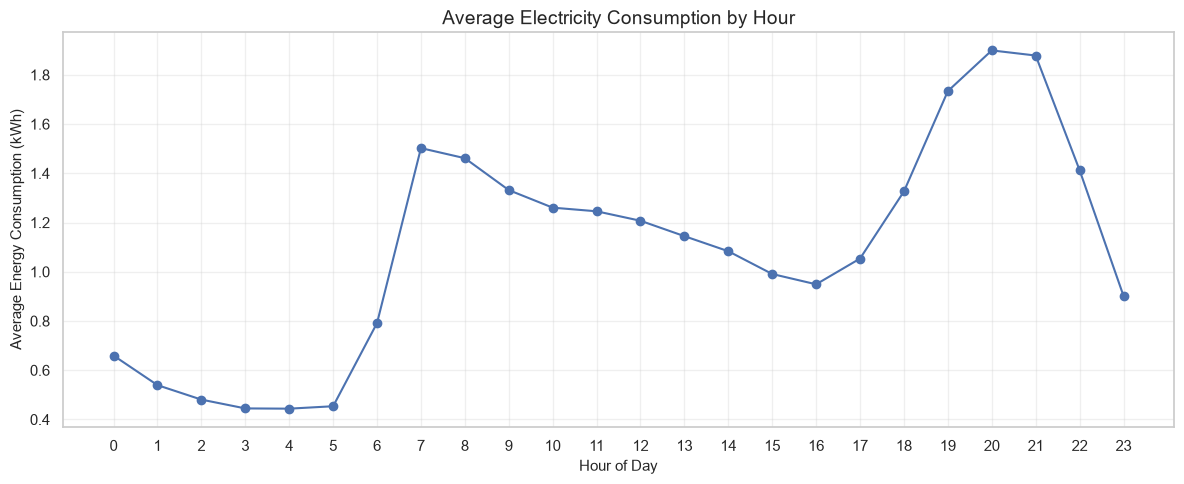

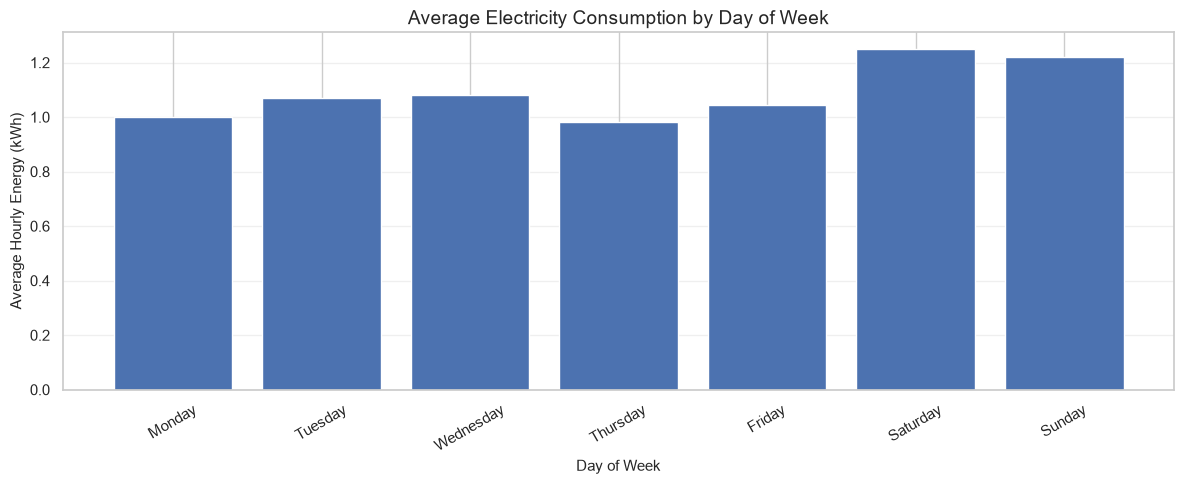

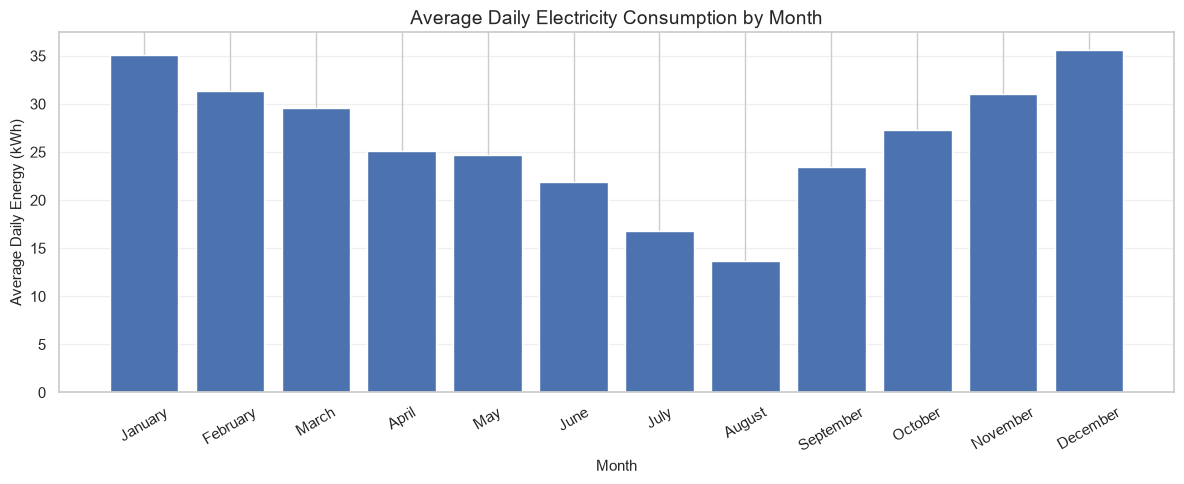

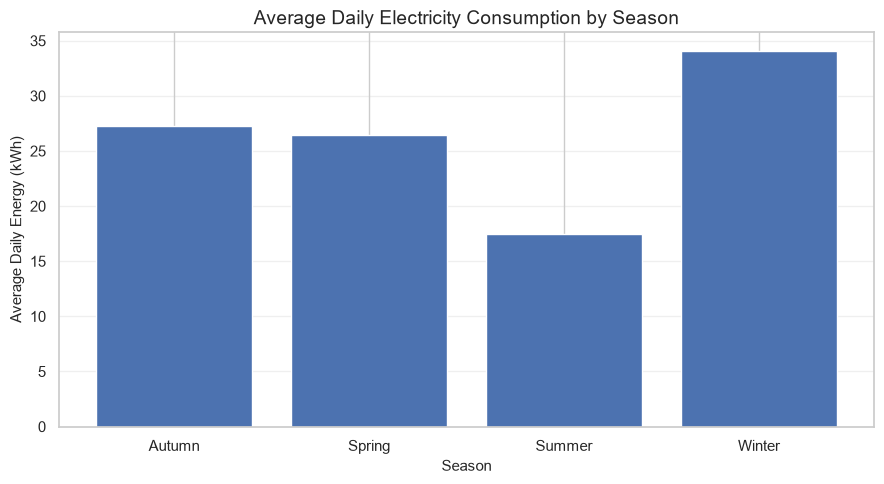

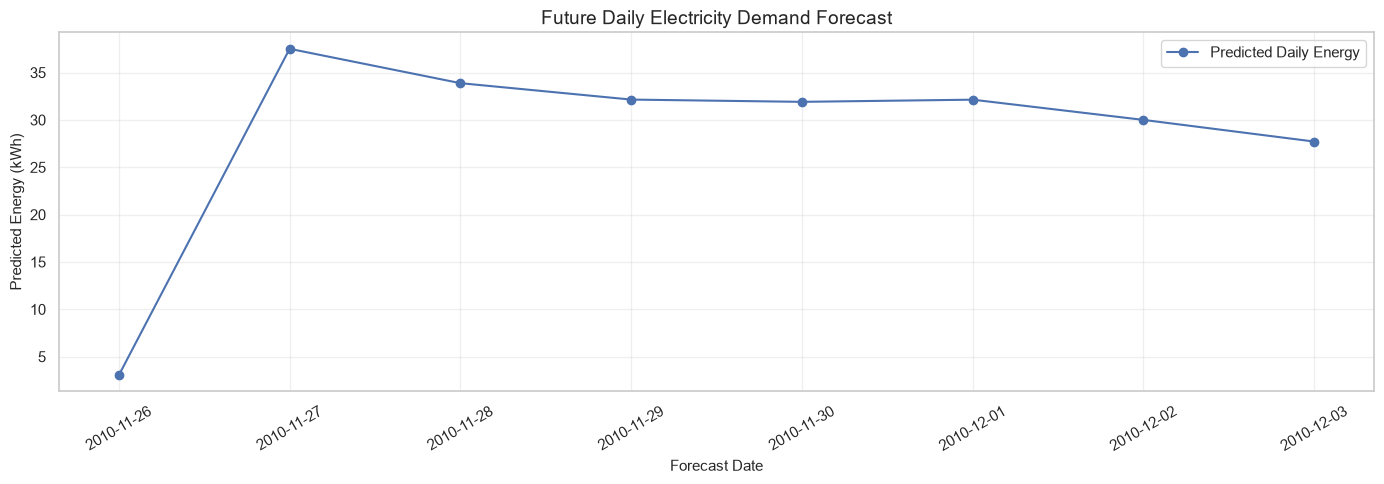


TASK 8: INSIGHTS AND RECOMMENDATIONS COMPLETED
Highest Consumption Hour: 20:00
Highest Consumption Day: Saturday
Highest Consumption Month: December
Highest Consumption Season: Winter
Best Forecasting Model: XGBoost
Predicted High-Demand Hours: 14

Recommendations Generated: 8

All Insights and Recommendation Reports Saved!
Output Folder: C:\Users\vyshu\OneDrive\Desktop\Smart-Energy-Forecasting\visualizations\insights_recommendations

TASK 8 COMPLETED SUCCESSFULLY!


In [251]:
# Cell 119: Insights and Recommendations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------------------------------------------------
# 1. PREPARE FULL HISTORICAL HOURLY ENERGY DATA
# ---------------------------------------------------------

# Use the full hourly dataset for descriptive insights, not the lag-filtered ML rows.
insights_data = hourly_data[["Energy_kWh"]].copy()

insights_data.index = pd.to_datetime(insights_data.index)
insights_data = insights_data.sort_index()

insights_data["Hour"] = insights_data.index.hour
insights_data["DayOfWeek"] = insights_data.index.dayofweek
insights_data["DayName"] = insights_data.index.day_name()
insights_data["Month"] = insights_data.index.month
insights_data["MonthName"] = insights_data.index.month_name()
insights_data["Year"] = insights_data.index.year

insights_data["DayType"] = np.where(
    insights_data["DayOfWeek"] >= 5,
    "Weekend",
    "Weekday"
)

# ---------------------------------------------------------
# 2. HOURLY CONSUMPTION ANALYSIS
# ---------------------------------------------------------

hourly_consumption = (
    insights_data.groupby("Hour")["Energy_kWh"].mean()
)

highest_hour = hourly_consumption.idxmax()
lowest_hour = hourly_consumption.idxmin()

highest_hour_value = hourly_consumption.max()
lowest_hour_value = hourly_consumption.min()

# ---------------------------------------------------------
# 3. WEEKDAY AND WEEKEND ANALYSIS
# ---------------------------------------------------------

weekday_weekend = (
    insights_data.groupby("DayType")["Energy_kWh"]
    .mean()
)

weekday_average = weekday_weekend.get("Weekday", np.nan)
weekend_average = weekday_weekend.get("Weekend", np.nan)

# Average consumption by day of week.
daily_pattern = (
    insights_data.groupby("DayName")["Energy_kWh"].mean()
)

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

daily_pattern = daily_pattern.reindex(day_order)

highest_day = daily_pattern.idxmax()
lowest_day = daily_pattern.idxmin()

# ---------------------------------------------------------
# 4. MONTHLY AND SEASONAL ANALYSIS
# ---------------------------------------------------------

# Calculate daily energy only for days with all 24 hours.
daily_total = insights_data["Energy_kWh"].resample("D").sum(
    min_count=24
)

daily_count = insights_data["Energy_kWh"].resample("D").count()

complete_daily_energy = daily_total[
    daily_count == 24
].dropna()

if complete_daily_energy.empty:
    raise ValueError(
        "No complete 24-hour days available for monthly analysis."
    )

daily_insights = complete_daily_energy.to_frame(
    name="Daily_Energy_kWh"
)

daily_insights["Month"] = daily_insights.index.month
daily_insights["MonthName"] = daily_insights.index.month_name()

monthly_pattern = (
    daily_insights.groupby("Month")["Daily_Energy_kWh"].mean()
)

month_names = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_pattern.index = [
    month_names[m - 1] for m in monthly_pattern.index
]

highest_month = monthly_pattern.idxmax()
lowest_month = monthly_pattern.idxmin()

# Seasonal analysis.
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}

daily_insights["Season"] = (
    daily_insights.index.month.map(season_map)
)

seasonal_pattern = (
    daily_insights.groupby("Season")["Daily_Energy_kWh"].mean()
)

highest_season = seasonal_pattern.idxmax()

# ---------------------------------------------------------
# 5. FUTURE FORECAST ANALYSIS
# ---------------------------------------------------------

forecast_daily_insights = (
    future_forecast["Predicted_Energy_kWh"]
    .resample("D")
    .sum()
)

highest_forecast_day = forecast_daily_insights.idxmax()
highest_forecast_energy = forecast_daily_insights.max()

forecast_peak_count = len(peak_demand_hours)

# ---------------------------------------------------------
# 6. PRINT IMPORTANT FINDINGS
# ---------------------------------------------------------

print("=" * 75)
print("SMART ENERGY CONSUMPTION FORECASTING")
print("TASK 8: INSIGHTS AND RECOMMENDATIONS")
print("=" * 75)

print("\n1. HOURLY CONSUMPTION INSIGHTS")

print("Highest Consumption Hour:",
      f"{highest_hour}:00")

print("Average Energy at Highest Hour:",
      round(highest_hour_value, 4), "kWh")

print("Lowest Consumption Hour:",
      f"{lowest_hour}:00")

print("Average Energy at Lowest Hour:",
      round(lowest_hour_value, 4), "kWh")

print("\n2. WEEKDAY AND WEEKEND INSIGHTS")

print("Average Weekday Consumption:",
      round(weekday_average, 4), "kWh")

print("Average Weekend Consumption:",
      round(weekend_average, 4), "kWh")

print("Highest Average Consumption Day:", highest_day)
print("Lowest Average Consumption Day:", lowest_day)

print("\n3. MONTHLY AND SEASONAL INSIGHTS")

print("Highest Average Daily Consumption Month:",
      highest_month)

print("Lowest Average Daily Consumption Month:",
      lowest_month)

print("Highest Average Daily Consumption Season:",
      highest_season)

print("\nMonthly Average Daily Energy:")
display(monthly_pattern.to_frame(
    "Average_Daily_Energy_kWh"
).round(4))

print("\nSeasonal Average Daily Energy:")
display(seasonal_pattern.to_frame(
    "Average_Daily_Energy_kWh"
).round(4))

print("\n4. FUTURE ENERGY DEMAND INSIGHTS")

print("Forecast Model:", best_model_name)

print("Forecast Period:",
      future_forecast.index.min(),
      "to",
      future_forecast.index.max())

print("Highest Forecast Demand Date:",
      highest_forecast_day.date())

print("Highest Forecast Daily Energy:",
      round(highest_forecast_energy, 4), "kWh")

print("Predicted High-Demand Hours:",
      forecast_peak_count)

# ---------------------------------------------------------
# 7. GENERATE PRACTICAL RECOMMENDATIONS
# ---------------------------------------------------------

recommendations = [
    {
        "Category": "Households",
        "Recommendation": (
            f"Monitor electricity use around {highest_hour}:00, "
            "the highest average consumption hour. "
            "Avoid operating multiple high-power appliances "
            "simultaneously during high-demand periods."
        )
    },
    {
        "Category": "Households",
        "Recommendation": (
            "Switch off unused lights and appliances, "
            "use energy-efficient equipment, and avoid "
            "unnecessary standby power consumption."
        )
    },
    {
        "Category": "Households",
        "Recommendation": (
            "Use washing machines, water heaters and other "
            "high-energy appliances efficiently. Where practical, "
            "shift flexible usage away from predicted peak hours."
        )
    },
    {
        "Category": "Businesses",
        "Recommendation": (
            "Schedule flexible industrial and commercial loads "
            "outside forecast high-demand periods whenever "
            "operationally possible."
        )
    },
    {
        "Category": "Businesses",
        "Recommendation": (
            "Monitor equipment energy consumption, improve "
            "maintenance, use efficient lighting and optimize "
            "heating, ventilation and air-conditioning systems."
        )
    },
    {
        "Category": "Electricity Providers",
        "Recommendation": (
            "Use hourly and daily demand forecasts to plan "
            "electricity generation, distribution and reserve capacity."
        )
    },
    {
        "Category": "Electricity Providers",
        "Recommendation": (
            "Monitor predicted peak-demand hours and prepare "
            "appropriate load-management measures to reduce "
            "the risk of overloading."
        )
    },
    {
        "Category": "Electricity Providers",
        "Recommendation": (
            "Use historical weekly, monthly and seasonal patterns "
            "to support maintenance scheduling, demand response "
            "and long-term energy planning."
        )
    }
]

recommendations_df = pd.DataFrame(recommendations)

print("\n5. ENERGY-SAVING RECOMMENDATIONS")
display(recommendations_df)

# ---------------------------------------------------------
# 8. CREATE INSIGHTS VISUALIZATIONS
# ---------------------------------------------------------

INSIGHTS_OUTPUT_PATH = Path(
    "../visualizations/insights_recommendations"
)

INSIGHTS_OUTPUT_PATH.mkdir(
    parents=True,
    exist_ok=True
)

# Graph 1: Average hourly consumption.
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_consumption.index,
    hourly_consumption.values,
    marker="o"
)

plt.title("Average Electricity Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Energy Consumption (kWh)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    INSIGHTS_OUTPUT_PATH / "hourly_consumption_insights.png",
    dpi=300
)

plt.show()

# Graph 2: Average consumption by weekday.
plt.figure(figsize=(12, 5))

plt.bar(
    daily_pattern.index,
    daily_pattern.values
)

plt.title("Average Electricity Consumption by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Hourly Energy (kWh)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    INSIGHTS_OUTPUT_PATH / "weekday_consumption_insights.png",
    dpi=300
)

plt.show()

# Graph 3: Monthly average daily energy.
plt.figure(figsize=(12, 5))

plt.bar(
    monthly_pattern.index,
    monthly_pattern.values
)

plt.title("Average Daily Electricity Consumption by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Energy (kWh)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    INSIGHTS_OUTPUT_PATH / "monthly_consumption_insights.png",
    dpi=300
)

plt.show()

# Graph 4: Seasonal energy consumption.
plt.figure(figsize=(9, 5))

plt.bar(
    seasonal_pattern.index,
    seasonal_pattern.values
)

plt.title("Average Daily Electricity Consumption by Season")
plt.xlabel("Season")
plt.ylabel("Average Daily Energy (kWh)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    INSIGHTS_OUTPUT_PATH / "seasonal_consumption_insights.png",
    dpi=300
)

plt.show()

# Graph 5: Historical and forecast daily energy.
plt.figure(figsize=(14, 5))

plt.plot(
    forecast_daily_insights.index,
    forecast_daily_insights.values,
    marker="o",
    label="Predicted Daily Energy"
)

plt.title("Future Daily Electricity Demand Forecast")
plt.xlabel("Forecast Date")
plt.ylabel("Predicted Energy (kWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    INSIGHTS_OUTPUT_PATH / "future_demand_insights.png",
    dpi=300
)

plt.show()

# ---------------------------------------------------------
# 9. SAVE INSIGHTS AND RECOMMENDATIONS
# ---------------------------------------------------------

hourly_consumption.to_csv(
    INSIGHTS_OUTPUT_PATH / "hourly_consumption_summary.csv"
)

daily_pattern.to_csv(
    INSIGHTS_OUTPUT_PATH / "weekday_consumption_summary.csv"
)

monthly_pattern.to_csv(
    INSIGHTS_OUTPUT_PATH / "monthly_consumption_summary.csv"
)

seasonal_pattern.to_csv(
    INSIGHTS_OUTPUT_PATH / "seasonal_consumption_summary.csv"
)

recommendations_df.to_csv(
    INSIGHTS_OUTPUT_PATH / "energy_saving_recommendations.csv",
    index=False
)

forecast_daily_insights.to_csv(
    INSIGHTS_OUTPUT_PATH / "future_demand_summary.csv"
)

# ---------------------------------------------------------
# 10. FINAL PROJECT SUMMARY
# ---------------------------------------------------------

print("\n" + "=" * 75)
print("TASK 8: INSIGHTS AND RECOMMENDATIONS COMPLETED")
print("=" * 75)

print("Highest Consumption Hour:", f"{highest_hour}:00")
print("Highest Consumption Day:", highest_day)
print("Highest Consumption Month:", highest_month)
print("Highest Consumption Season:", highest_season)

print("Best Forecasting Model:", best_model_name)

print("Predicted High-Demand Hours:", forecast_peak_count)

print("\nRecommendations Generated:",
      len(recommendations_df))

print("\nAll Insights and Recommendation Reports Saved!")

print("Output Folder:",
      INSIGHTS_OUTPUT_PATH.resolve())

print("\nTASK 8 COMPLETED SUCCESSFULLY!")

